# PDIoT Lab 3 – Training a Human Activity Recognition Model and Converting it to TensorFlow Lite

In Lab 2 you cleaned and checked the recordings. In this lab, you will use the class dataset from a previous year (`datasetJan2026.zip`) to train a classifier that identifies the activity from a short window of accelerometer data. You will then convert the trained model to TensorFlow Lite (TFLite), which is the format used to run models on a phone. In Lab 4, you will use a TFLite model in the PDIoT app to classify activities in real time.

The notebook has two parts:

* **Part A** is a complete example that takes you through the whole process. Run it from top to bottom. It trains a simple multilayer perceptron (MLP) using raw accelerometer windows and produces a `.tflite` model.
* **Part B** contains a set of exercises where you modify different parts of the pipeline, such as the window length, features, or model, and compare the results. The model you develop here will be used on the phone in Lab 4.

### How the pieces fit together

```
 recordings (CSV, 30 s @ 12.5 Hz)
        │  make_windows()          sliding window, WINDOW samples long, STEP samples apart
        ▼
 windows  X: (n, WINDOW, 3)   y: (n,)            ← split train / val / test BY RECORDING
        │  build_mlp() + fit()
        ▼
 Keras model  (Normalization → Flatten → Dense → Dense → softmax)
        │  convert_to_tflite()
        ▼
 model.tflite + model_meta.json  ──── verify_tflite() ────►  Lab 4: the app
```

> **Why windows?** The phone receives one sample every 80 ms (12.5 Hz). It cannot wait 30 s to tell you what you are doing, so the model must decide from a short *window* of the most recent samples – here 4 s (50 samples). The app keeps a rolling buffer of the last `WINDOW` samples and runs the model on it every `STEP` samples. The constants in the configuration cell therefore describe the **contract between your model and the app**.

# Part A · A complete pipeline

## A0 · Setup

Use the Python environment you set up in Lab 2 (plain Python + `venv`, Anaconda, or Colab) and install two additional packages: TensorFlow and scikit-learn.

| Plain Python (`venv` active) | Anaconda / Miniforge (env active) | Google Colab |
|---|---|---|
| `pip install tensorflow scikit-learn` | `pip install tensorflow` then `conda install scikit-learn` | Both are pre-installed |

TensorFlow is about 500 MB, so install it before the lab if possible. This notebook was written with TensorFlow 2.21 / Keras 3, although TensorFlow 2.16 or later should work. On a Mac with Apple silicon, `tensorflow` can be installed normally. On Windows, TensorFlow requires 64-bit Python 3.10–3.13. A GPU is not required; the models in this lab should train in under two minutes on a laptop CPU.

Next, put **`datasetJan2026.zip` in the same folder as this notebook**. This is also where the trained models will be saved. The next cell will unzip the dataset if the unzipped folder does not already exist.

If you keep the dataset somewhere else, change `DATA_DIR` in the configuration cell to point to its location.

In [ ]:
import zipfile
from pathlib import Path

# Check whether the dataset has already been unzipped.
# If not, check whether the ZIP file is available and extract it.
if not Path("datasetJan2026").exists() and Path("datasetJan2026.zip").exists():
    zipfile.ZipFile("datasetJan2026.zip").extractall(".")
    # The extracted folder contains:
    #   datasetJan2026/daily_activity
    #   datasetJan2026/social_signal
    print("unzipped datasetJan2026.zip")

# Show the current working folder.
# This is the folder where the notebook looks for the dataset.
print("working folder:", Path.cwd())

unzipped datasetJan2026.zip
working folder: /content


In [ ]:
import io, json, time, warnings, contextlib
from pathlib import Path

# Numerical and data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# TensorFlow and Keras for building and training the model
import tensorflow as tf
import keras
from keras import layers

# Tools for splitting the data and evaluating the classifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Reduce TensorFlow messages in the notebook output
tf.get_logger().setLevel("ERROR")

# Hide a known TensorFlow warning about the TFLite interpreter
warnings.filterwarnings(
    "ignore",
    category=UserWarning,
    module="tensorflow"
)

# Print the versions being used
print("TensorFlow", tf.__version__, "· Keras", keras.__version__)

TensorFlow 2.21.0 · Keras 3.13.2


## A1 · Configuration

The settings below are used throughout the notebook. `WINDOW`, `STEP`, and `CLASSES` determine the input and output of the model:

- `WINDOW` sets the number of samples in each input window.
- `STEP` sets how far the window moves between consecutive samples.
- `CLASSES` lists the activities that the model will classify, in the order used for its outputs.

The model takes a `WINDOW × 3` array of raw accelerometer values in g and returns one probability for each class. These settings are also saved in `model_meta.json` alongside the model so that they are available when the model is used later.

In [ ]:
DATA_DIR = Path("datasetJan2026")               # <-- folder produced by unzipping datasetJan2026.zip (relative to this notebook)
OUT_DIR  = Path("lab3_models")                  # models and metadata are written here, next to the notebook
OUT_DIR.mkdir(parents=True, exist_ok=True)

TASK = "daily_activity"                         # sub-folder of the dataset to classify (Exercise B6 uses "social_signal")

SAMPLING_FREQ = 12.5                            # Hz – RESpeck sampling rate
WINDOW = 50                                     # samples per window: 50 / 12.5 Hz = 4 s
STEP   = 25                                     # samples between consecutive windows (50 % overlap)
AXES   = ["accelX", "accelY", "accelZ"]

# Class order is FIXED here (not derived from the folder listing) so that the model's output
# index i always means CLASSES[i], on the phone as well as in this notebook.
CLASSES = ["sittingStanding", "lyingBack", "lyingLeft", "lyingRight", "lyingStomach",
           "normalWalking", "shuffleWalking", "ascending", "descending", "running", "miscMovement"]

SEED = 0
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

assert DATA_DIR.exists(), f"{DATA_DIR.resolve()} not found – unzip datasetJan2026.zip next to this notebook or change DATA_DIR"
assert all((DATA_DIR / TASK / c).is_dir() for c in CLASSES), "a class folder is missing – check TASK and CLASSES"
print(f"Window = {WINDOW} samples = {WINDOW / SAMPLING_FREQ:.1f} s;  step = {STEP} samples = {STEP / SAMPLING_FREQ:.1f} s")
print(f"{len(CLASSES)} classes:", CLASSES)

Window = 50 samples = 4.0 s;  step = 25 samples = 2.0 s
11 classes: ['sittingStanding', 'lyingBack', 'lyingLeft', 'lyingRight', 'lyingStomach', 'normalWalking', 'shuffleWalking', 'ascending', 'descending', 'running', 'miscMovement']


## A2 · Load the recordings and cut them into windows

Each CSV file in the dataset contains one recording of a single activity. The files contain three acceleration columns and around 375 rows, corresponding to approximately 30 seconds of data.

`list_recordings()` finds all the recording files and their activity labels. `make_windows()` then divides each recording into overlapping windows of `WINDOW` samples, moving forward by `STEP` samples each time. The result is an array with shape `(n_windows, WINDOW, 3)`.

> **Which recording does each window come from?**
>
> We keep a `rec` ID for each window so that we can keep track of which recording it came from. You will see why this is important in A3.

`load_recording()` removes rows containing missing values. The class dataset contains one file with a row of NaNs. If these values were left in the data, any window containing that row would also contain NaNs. It is therefore worth checking for missing values when loading the recordings.

In [ ]:
# 先遍历活动类别，再遍历每个类别下的文件，把每个文件的信息加入列表。
def list_recordings(task: str = TASK, classes=CLASSES) -> pd.DataFrame:
    """Find all CSV recordings and store their paths and activity labels."""
    rows = [
        {"path": p, "label": c, "y": i}
        for i, c in enumerate(classes)
        for p in sorted((DATA_DIR / task / c).glob("*.csv"))
    ]
    return pd.DataFrame(rows)


def load_recording(path) -> np.ndarray:
    """Load one recording and return the three acceleration axes as float32."""
    # Keep only the acceleration columns and remove rows with missing values.
    return (
        pd.read_csv(path, usecols=AXES)[AXES]
        .dropna()
        .to_numpy(dtype=np.float32)
    )


def make_windows(
    signal: np.ndarray,
    window: int = WINDOW,
    step: int = STEP
) -> np.ndarray:
    """Split a recording into overlapping windows of shape (window, 3)."""
    n = len(signal)

    # Generate the starting position of each window.
    starts = range(0, n - window + 1, step)

    # Return an empty array if the recording is shorter than one window.
    if n < window:
        return np.empty((0, window, 3), np.float32)

    # Extract a window starting at each position.
    return np.stack([signal[s:s + window] for s in starts])

###
# 这个函数把前面三个步骤连接起来：
# 1. 已经有文件清单 recs。
# 2. 循环读取每个 CSV。
# 3. 将每个文件切割成窗口。
# 4. 给窗口添加正确的活动标签和来源记录编号。
# 5. 最后合并成整个数据集。
###
def windows_from_recordings(
    recs: pd.DataFrame,
    window: int = WINDOW,
    step: int = STEP
):
    """Create windows for all recordings and keep their labels and recording IDs."""
    X, y, rec = [], [], []

    for i, r in recs.iterrows():
        # Load the recording and split it into windows.
        w = make_windows(load_recording(r.path), window, step)

        # Store the windows, activity label, and source recording ID.
        X.append(w)
        y += [r.y] * len(w)
        rec += [i] * len(w)

    # Combine the windows from all recordings into single arrays.
    return np.concatenate(X), np.array(y), np.array(rec)


# Find all recordings in the selected task and class folders.
recordings = list_recordings()

print(f"{len(recordings)} recordings in '{TASK}'")

# Show how many recordings there are for each activity.
recordings.label.value_counts().reindex(CLASSES).rename("recordings").to_frame().T

1919 recordings in 'daily_activity'


label,sittingStanding,lyingBack,lyingLeft,lyingRight,lyingStomach,normalWalking,shuffleWalking,ascending,descending,running,miscMovement
recordings,351,161,124,120,173,166,168,164,148,174,170


The table shows that the dataset is **imbalanced**: there are about twice as many sitting/standing recordings as recordings of the other activities. This is because every social-signal recording made while sitting or standing is included as a sitting/standing recording. Keep this in mind when interpreting accuracy results later, particularly in Exercise B5.

Let's look at one 4-second window from a few activities. The stationary postures can be distinguished by the direction of gravity, with one axis typically close to ±1 g, as seen in Lab 2. The moving activities have more variation in the signal, with differences in both the size and speed of these changes.

In [ ]:
def plot_windows(classes_to_show, recs=recordings, window=WINDOW):
    # Create one plot for each activity.
    fig, axs = plt.subplots(
        1,
        len(classes_to_show),
        figsize=(4 * len(classes_to_show), 3),
        sharey=True
    )

    # Convert sample numbers to time in seconds.
    t = np.arange(window) / SAMPLING_FREQ

    for ax, c in zip(np.atleast_1d(axs), classes_to_show):
        # Load the first recording for this activity and select the third window.
        w = make_windows(
            load_recording(recs[recs.label == c].path.iloc[0]),
            window
        )[2]

        # Plot the three acceleration axes.
        for k, a in enumerate(AXES):
            ax.plot(t, w[:, k], label=a, lw=1.2)

        # Add labels and formatting to the plot.
        ax.set_title(c)
        ax.set_xlabel("time (s)")
        ax.set_ylim(-2.2, 2.2)
        ax.grid(alpha=0.3)

    # Add a shared y-axis label and legend.
    np.atleast_1d(axs)[0].set_ylabel("acceleration (g)")
    np.atleast_1d(axs)[0].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


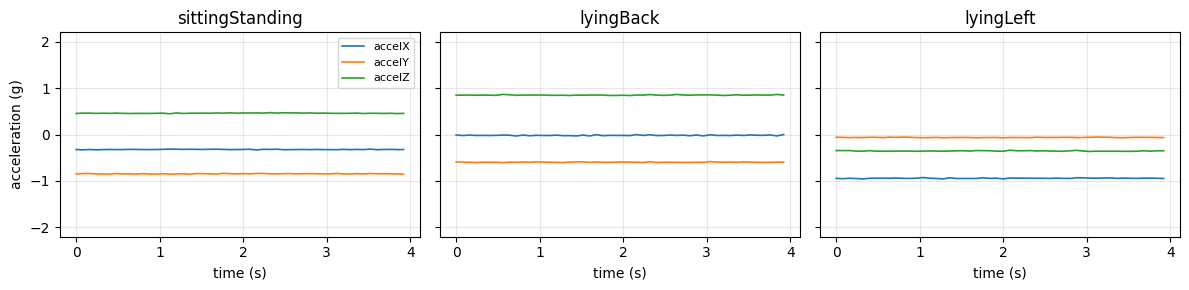

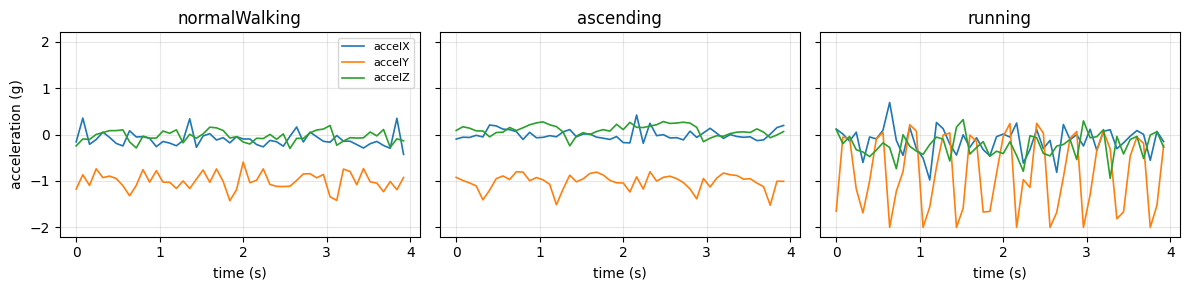

In [ ]:
# Plot examples of stationary activities.
plot_windows(["sittingStanding", "lyingBack", "lyingLeft"])

# Plot examples of activities involving movement.
plot_windows(["normalWalking", "ascending", "running"])

## A3 · Split into training, validation and test sets – by file

The model should be evaluated on data from people it has not seen during training. We therefore keep a **validation** set for development, such as choosing the number of training epochs or comparing models, and a separate **test** set for the final evaluation.

The split must be done **by subject, not by window**. The windows overlap by 50%, and windows from the same recording are very similar because they come from the same person performing the same activity. If windows from one subject were included in both the training and test sets, the model would be tested on data very similar to data it had already seen. This would give an overly optimistic estimate of its performance.

In this dataset, the file name identifies the subject. For example, `N_12.csv` in the `running/` folder is the running recording for subject 12. Each subject has at most one recording for each activity. Subject numbers are **not** shared across activities, so subject 12 in `running/` is not the same person as subject 12 in `lyingBack/`.

Because of this, we can split the recordings within each activity before creating the windows. `split_recordings()` does this while keeping roughly the same proportion of each activity in the different sets. The recordings are then divided into windows after the split.

> **How the coursework evaluates your model**
>
> Coursework 3 uses **subject-wise 10-fold cross-validation**, with the fold assignments provided on Learn. Since not every subject recorded every activity, and subject numbers are specific to each activity, the folds are created separately for each activity. The subjects for each activity are divided into 10 roughly equal groups. In each fold, one group from each activity is used for testing and the remaining groups are used for training.
>
> This means that, within each activity, a subject's data is never included in both the training and test sets for the same fold. The single hold-out split used in this lab is sufficient for developing and comparing models. For the final results, use the 10 folds provided on Learn and report the average accuracy across the folds (Exercise B9).

In [ ]:
def split_recordings(
    recs: pd.DataFrame,
    val_frac=0.15,
    test_frac=0.15,
    seed=SEED
):
    """Split the recordings into stratified train, validation, and test sets."""

    # Split off the test recordings first.
    # Stratification keeps a similar number of recordings from each activity.
    train_val, test = train_test_split(
        recs,
        test_size=test_frac,
        stratify=recs.y,
        random_state=seed
    )

    # Split the remaining recordings into training and validation sets.
    train, val = train_test_split(
        train_val,
        test_size=val_frac / (1 - test_frac),
        stratify=train_val.y,
        random_state=seed
    )

    return train, val, test


# Split the recordings before creating any windows.
rec_train, rec_val, rec_test = split_recordings(recordings)

# Create windows from each set.
# This is done after the split so that windows from the same recording
# cannot end up in different sets.
t0 = time.time()

X_train, y_train, rec_id_train = windows_from_recordings(rec_train)
X_val, y_val, _ = windows_from_recordings(rec_val)
X_test, y_test, rec_id_test = windows_from_recordings(rec_test)

print(f"windowed in {time.time() - t0:.0f} s")

# Show how many recordings were assigned to each set.
print(
    f"recordings  train {len(rec_train)}  "
    f"val {len(rec_val)}  test {len(rec_test)}"
)

# Show the number and shape of windows in each set.
print(
    f"windows     train {X_train.shape}  "
    f"val {X_val.shape}  test {X_test.shape}"
)

windowed in 4 s
recordings  train 1343  val 288  test 288
windows     train (18729, 50, 3)  val (3997, 50, 3)  test (4034, 50, 3)


## A4 · Build the model

The model takes each `50 × 3` accelerometer window and first flattens it into 150 values. These are then passed through two fully connected (`Dense`) layers, followed by a `softmax` layer that gives one output for each activity class.

There are two details to note:

* **Normalisation is part of the model.** The first layer is a `Normalization` layer. It subtracts the mean and divides by the standard deviation for each accelerometer axis, calculated from the training data. Since this step is included in the model, the app can provide the raw accelerometer values in g without applying the normalisation itself.

* **The model input is `(WINDOW, 3)`.** The input is kept as a `50 × 3` window. The model handles the flattening internally, so the app can pass in the accelerometer window in the same format as it was recorded.

In [ ]:
def build_mlp(
    window: int = WINDOW,
    n_classes: int = len(CLASSES),
    hidden=(64, 32),
    dropout=0.2
) -> keras.Model:
    # Normalise each accelerometer axis using statistics from the training data.
    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_train)

    # Define the model input and flatten each window before the Dense layers.
    model = keras.Sequential(
        [
            keras.Input(shape=(window, 3), name="window"),
            norm,
            layers.Flatten()
        ],
        name="har_mlp"
    )
    # Add the hidden Dense layers with ReLU activation and dropout.
    for h in hidden:
        model.add(layers.Dense(h, activation="relu"))
        model.add(layers.Dropout(dropout))
    # Output one probability for each activity class.
    model.add(
        layers.Dense(
            n_classes,
            activation="softmax",
            name="probabilities"
        )
    )
    return model


# Build the model with the default settings.
model = build_mlp()

# Set the optimiser, loss function, and metric used during training.
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture and number of parameters.
model.summary()

Model: "har_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         9,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           363 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,114 (47.32 KB)

 Trainable params: 12,107 (47.29 KB)

 Non-trainable params: 7 (32.00 B)

## A5 · Train

`EarlyStopping` watches the validation accuracy and keeps the best weights, so a too-large `epochs` is harmless. The MLP trains in well under a minute on a CPU.

trained 40 epochs in 37 s; best epoch 35: val accuracy 0.837


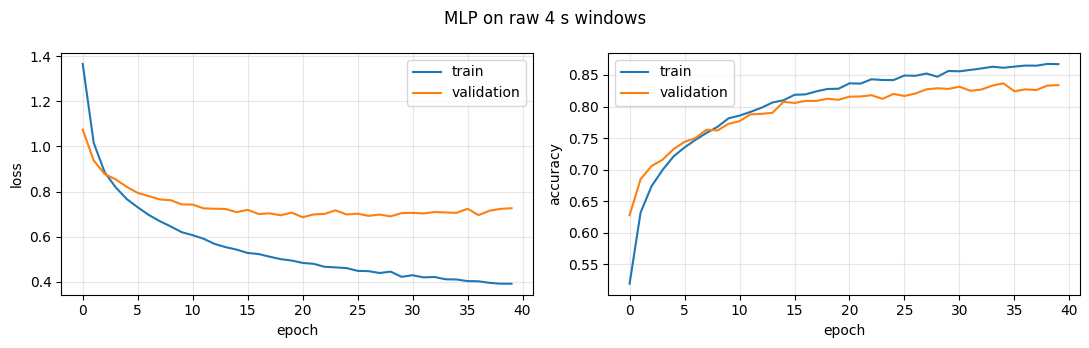

In [ ]:
def train(
    model: keras.Model,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    class_weight=None,
    verbose=0
):
    """Train the model and stop early if validation accuracy stops improving."""

    # Stop training if validation accuracy has not improved for 8 epochs.
    # Restore the model weights from the best epoch.
    cb = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=8,
            restore_best_weights=True
        )
    ]

    t0 = time.time()

    # Train the model using the training set and evaluate on the validation set
    # after each epoch.
    hist = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weight,
        callbacks=cb,
        verbose=verbose
    )

    # Find the epoch with the highest validation accuracy.
    best = int(np.argmax(hist.history["val_accuracy"]))

    print(
        f"trained {len(hist.history['loss'])} epochs in "
        f"{time.time() - t0:.0f} s; "
        f"best epoch {best + 1}: "
        f"val accuracy {hist.history['val_accuracy'][best]:.3f}"
    )

    return hist


def plot_history(hist, title=""):
    # Create separate plots for the loss and accuracy.
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))

    for ax, key in zip(axs, ["loss", "accuracy"]):
        # Plot the training and validation values for each epoch.
        ax.plot(hist.history[key], label="train")
        ax.plot(
            hist.history["val_" + key],
            label="validation"
        )

        ax.set_xlabel("epoch")
        ax.set_ylabel(key)
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Train the model using the training and validation sets.
history = train(
    model,
    X_train,
    y_train,
    X_val,
    y_val
)

# Plot the training and validation loss and accuracy.
plot_history(history, "MLP on raw 4 s windows")

## A6 · Evaluate on the test set

Start with the overall accuracy, then look at the **confusion matrix**. Rows show the true activity and columns show the predicted activity. The off-diagonal values show which activities are being confused with each other.

Some confusion is expected with accelerometer data, for example between ascending and descending stairs, normal and shuffle walking, or other activities grouped as miscellaneous movements. Check which activities your model has the most difficulty distinguishing.

`evaluate()` also calculates **per-recording accuracy**. For each recording, the predicted activity is the class that appears most often across its windows. This gives an indication of how well the model classifies a recording as a whole, rather than individual 4-second windows. It is usually a little higher than the per-window accuracy.

MLP  per-window accuracy: 0.851
MLP  per-recording accuracy (majority vote over windows): 0.896
                 precision    recall  f1-score   support

sittingStanding      0.947     0.896     0.921       781
      lyingBack      0.951     1.000     0.975       332
      lyingLeft      0.992     0.943     0.967       263
     lyingRight      0.954     1.000     0.976       249
   lyingStomach      0.938     1.000     0.968       360
  normalWalking      0.672     0.591     0.629       350
 shuffleWalking      0.692     0.772     0.730       346
      ascending      0.729     0.746     0.737       346
     descending      0.726     0.750     0.738       304
        running      0.920     0.961     0.940       358
   miscMovement      0.759     0.693     0.724       345

       accuracy                          0.851      4034
      macro avg      0.844     0.850     0.846      4034
   weighted avg      0.850     0.851     0.850      4034



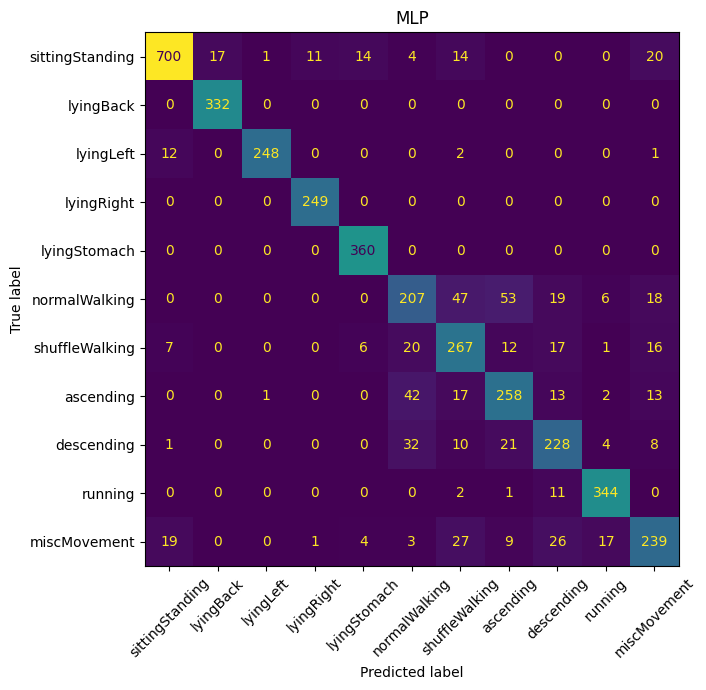

In [ ]:
def evaluate(
    predict_fn,
    X,
    y,
    rec_id=None,
    classes=CLASSES,
    title="",
    report=True
):
    """Evaluate predictions and display accuracy, classification report, and confusion matrix."""

    # Get the predicted class for each window.
    # predict_fn returns one probability for each class.
    y_pred = predict_fn(X).argmax(axis=1)

    # Calculate accuracy across individual windows.
    acc = accuracy_score(y, y_pred)
    print(f"{title}  per-window accuracy: {acc:.3f}")

    if rec_id is not None:
        # Group the windows by their source recording.
        # The most common prediction is used as the prediction for the recording.
        votes = (
            pd.DataFrame({
                "rec": rec_id,
                "y": y,
                "pred": y_pred
            })
            .groupby("rec")
            .agg(
                y=("y", "first"),
                pred=("pred", lambda s: s.mode().iloc[0])
            )
        )

        # Calculate accuracy across complete recordings.
        rec_acc = accuracy_score(votes.y, votes.pred)
        print(
            f"{title}  per-recording accuracy "
            f"(majority vote over windows): {rec_acc:.3f}"
        )

    if report:
        # Print precision, recall, and F1 score for each activity.
        print(
            classification_report(
                y,
                y_pred,
                target_names=classes,
                digits=3,
                zero_division=0
            )
        )

    # Create and display the confusion matrix.
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(
        confusion_matrix(y, y_pred),
        display_labels=classes
    ).plot(
        ax=ax,
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(title or "confusion matrix (test windows)")
    plt.tight_layout()
    plt.show()

    return acc


# Use the trained Keras model to generate class probabilities.
keras_predict = lambda X: model.predict(
    X,
    batch_size=512,
    verbose=0
)

# Evaluate the model on the test set.
mlp_acc = evaluate(
    keras_predict,
    X_test,
    y_test,
    rec_id_test,
    title="MLP"
)

## A7 · Convert to TensorFlow Lite

TFLite is a compact, portable format for running trained models on phones and microcontrollers. `convert_to_tflite()` converts the Keras model and writes two files:

* `har_mlp.tflite` – the model itself (a few hundred kB at most).
* `har_mlp_meta.json` – the contract: sampling rate, window length, step, class names in output order, and the input/output tensor shapes. The app reads this instead of having the numbers hard-coded.

The input shape is fixed to **batch size 1** (`[1, WINDOW, 3]`) because that is how the phone will call it: one window at a time.

In [ ]:
def convert_to_tflite(
    model: keras.Model,
    name: str,
    window: int = WINDOW,
    step: int = STEP,
    classes=CLASSES,
    out_dir: Path = OUT_DIR,
    optimizations=()
) -> Path:
    """Convert a Keras model to TFLite and save the model and its metadata."""

    # Create a TFLite converter from the trained Keras model.
    converter = tf.lite.TFLiteConverter.from_keras_model(model)

    # Apply any requested TFLite optimisations.
    converter.optimizations = list(optimizations)

    # Convert the model. The converter can print a lot of output,
    # so redirect it to a string instead of displaying it.
    with contextlib.redirect_stdout(io.StringIO()):
        tflite_bytes = converter.convert()

    # Save the TFLite model to a file.
    tflite_path = out_dir / f"{name}.tflite"
    tflite_path.write_bytes(tflite_bytes)

    # Load the converted model so that we can check its input and output
    # details and use them when creating the metadata file.
    interp = tf.lite.Interpreter(model_content=tflite_bytes)

    # Set the input shape to one window: (batch, samples, axes).
    interp.resize_tensor_input(
        interp.get_input_details()[0]["index"],
        [1, window, 3]
    )
    interp.allocate_tensors()
    # Store the information needed to use the model later.
    meta = {
        "model_file": tflite_path.name,
        "task": TASK,
        "sampling_frequency_hz": SAMPLING_FREQ,
        "window_samples": window,
        "step_samples": step,
        # Information about the model input.
        "input": {
            "shape": [1, window, 3],
            "channels": AXES,
            "units": "g (raw accelerometer values)",
            "dtype": str(
                np.dtype(interp.get_input_details()[0]["dtype"])
            )
        },
        # Information about the model output and activity classes.
        "output": {
            "shape": [1, len(classes)],
            "classes": list(classes),
            "dtype": str(
                np.dtype(interp.get_output_details()[0]["dtype"])
            )
        },
        # Normalisation is already included in the model.
        "normalization": "inside the model – feed raw values",
    }
    # Save the metadata alongside the TFLite model.
    (out_dir / f"{name}_meta.json").write_text(
        json.dumps(meta, indent=2)
    )
    print(
        f"wrote {tflite_path.name} "
        f"({len(tflite_bytes) / 1024:.1f} kB) "
        f"and {name}_meta.json"
    )
    return tflite_path


# Convert the trained model to TFLite and save it.
tflite_path = convert_to_tflite(model, "har_mlp")

# Display the saved metadata so we can check the model settings.
print((OUT_DIR / "har_mlp_meta.json").read_text())

wrote har_mlp.tflite (51.0 kB) and har_mlp_meta.json
{
  "model_file": "har_mlp.tflite",
  "task": "daily_activity",
  "sampling_frequency_hz": 12.5,
  "window_samples": 50,
  "step_samples": 25,
  "input": {
    "shape": [
      1,
      50,
      3
    ],
    "channels": [
      "accelX",
      "accelY",
      "accelZ"
    ],
    "units": "g (raw accelerometer values)",
    "dtype": "float32"
  },
  "output": {
    "shape": [
      1,
      11
    ],
    "classes": [
      "sittingStanding",
      "lyingBack",
      "lyingLeft",
      "lyingRight",
      "lyingStomach",
      "normalWalking",
      "shuffleWalking",
      "ascending",
      "descending",
      "running",
      "miscMovement"
    ],
    "dtype": "float32"
  },
  "normalization": "inside the model \u2013 feed raw values"
}


## A8 · Verify the TFLite model

After converting the model, check that the TFLite version gives the same results as the original Keras model. `run_tflite()` runs the `.tflite` file using the TFLite **interpreter** in Python, one window at a time. `verify_tflite()` then compares its predictions with the Keras model on the test set. The predicted classes should be the same for almost all windows, with only small differences in the output probabilities due to floating-point calculations.

This cell also saves `har_mlp_example.json`, which contains one test window and the probabilities produced by the model. In Lab 4, you can use this example to check that the app is passing data to the model correctly and getting the expected output.

In [ ]:
class TFLiteModel:
    '''Minimal wrapper around the TFLite interpreter: predicts one window at a time, like the app.'''
    def __init__(self, path):
        self.interp = tf.lite.Interpreter(model_path=str(path))
        self.inp = self.interp.get_input_details()[0]; self.out = self.interp.get_output_details()[0]
        self.interp.resize_tensor_input(self.inp["index"], [1, *self.inp["shape"][1:]]); self.interp.allocate_tensors()

    def predict_one(self, window: np.ndarray) -> np.ndarray:
        self.interp.set_tensor(self.inp["index"], window[np.newaxis].astype(self.inp["dtype"]))
        self.interp.invoke()
        return self.interp.get_tensor(self.out["index"])[0]

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.stack([self.predict_one(w) for w in X])


def verify_tflite(tflite_path, keras_model, X, y, name=None):
    '''Compare TFLite and Keras predictions on X; write an example input/output pair for the app.'''
    lite = TFLiteModel(tflite_path)
    t0 = time.time(); p_lite = lite.predict(X); dt = (time.time() - t0) / len(X) * 1000
    p_keras = keras_model.predict(X, batch_size=512, verbose=0)
    agree = (p_lite.argmax(1) == p_keras.argmax(1)).mean()
    print(f"{Path(tflite_path).name}: TFLite accuracy {accuracy_score(y, p_lite.argmax(1)):.3f} · "
          f"argmax agrees with Keras on {agree:.1%} of windows · max |Δprob| = {np.abs(p_lite - p_keras).max():.2e} · "
          f"{dt:.2f} ms per window on this CPU")
    name = name or Path(tflite_path).stem
    example = {"input_window": X[0].round(6).tolist(), "expected_probabilities": p_lite[0].round(6).tolist(),
               "expected_class": CLASSES[int(p_lite[0].argmax())], "true_class": CLASSES[int(y[0])]}
    (OUT_DIR / f"{name}_example.json").write_text(json.dumps(example))
    return p_lite


p_lite = verify_tflite(tflite_path, model, X_test, y_test)

har_mlp.tflite: TFLite accuracy 0.851 · argmax agrees with Keras on 100.0% of windows · max |Δprob| = 1.25e-06 · 0.01 ms per window on this CPU


## A9 · Simulate a real-time run

To see how the model will work in Lab 4, take one unseen recording and process it as a stream of data. The model uses a rolling buffer containing the last `WINDOW` samples and makes a new prediction every `STEP` samples (2 s).

The plot shows the predicted activity over time. For a steady activity, the predictions should usually stay the same. Changes between classes show where the model is less consistent, which you can compare with the confusions in the confusion matrix.

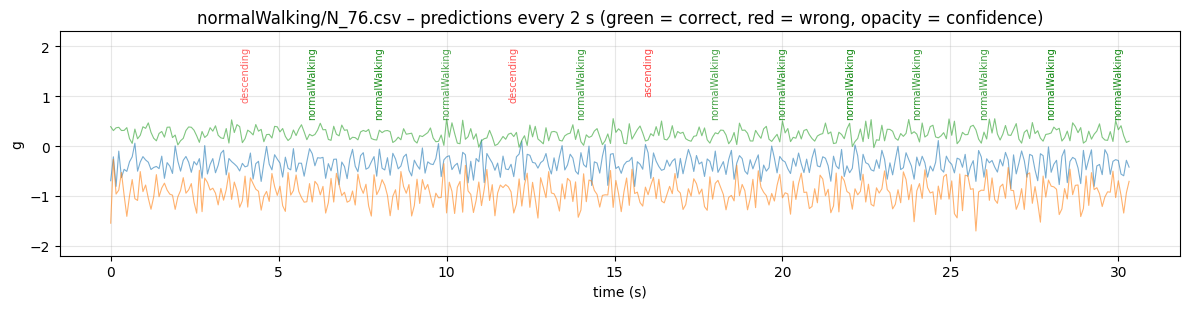

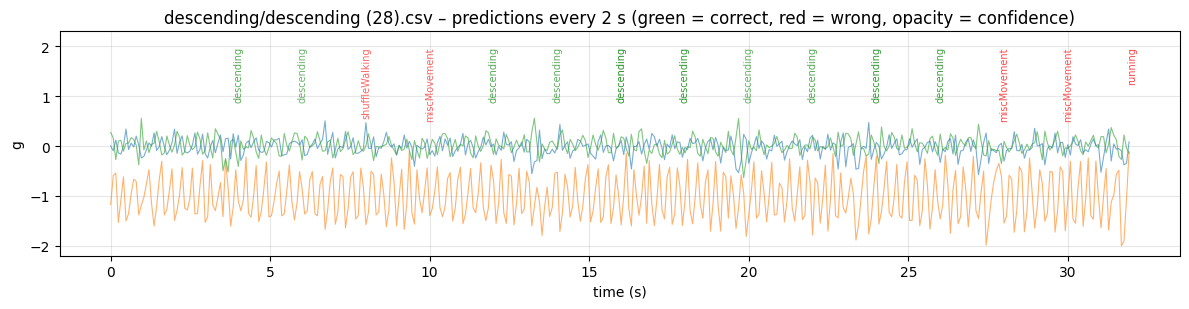

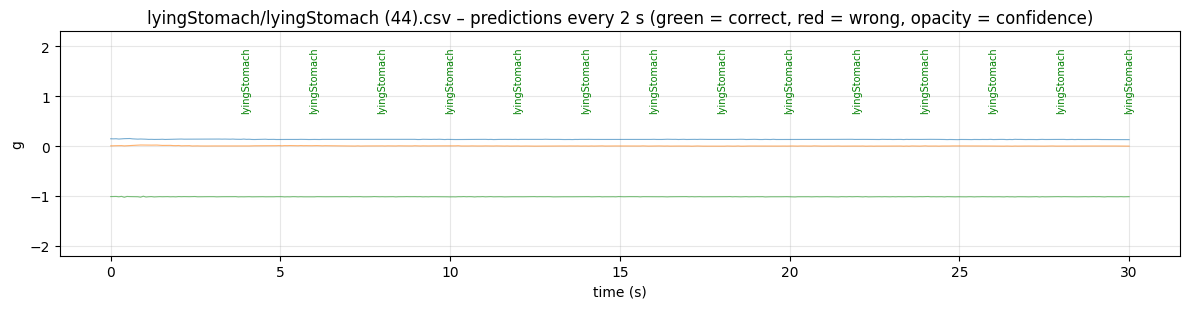

In [ ]:
def simulate_realtime(tflite_path, recording_path, true_label=None, window=WINDOW, step=STEP, classes=CLASSES):
    lite = TFLiteModel(tflite_path); signal = load_recording(recording_path)
    times, preds, confs = [], [], []
    for end in range(window, len(signal) + 1, step):
        p = lite.predict_one(signal[end - window:end])
        times.append(end / SAMPLING_FREQ); preds.append(int(p.argmax())); confs.append(float(p.max()))
    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.plot(np.arange(len(signal)) / SAMPLING_FREQ, signal, lw=0.8, alpha=0.6)
    for t, k, c in zip(times, preds, confs):
        ax.text(t, 2.0, classes[k], rotation=90, fontsize=7, ha="center", va="top",
                color="green" if (true_label is None or classes[k] == true_label) else "red", alpha=0.4 + 0.6 * c)
    ax.set_ylim(-2.2, 2.3); ax.set_xlabel("time (s)"); ax.set_ylabel("g"); ax.grid(alpha=0.3)
    ax.set_title(f"{Path(recording_path).parent.name}/{Path(recording_path).name} – predictions every {step / SAMPLING_FREQ:.0f} s "
                 f"(green = correct, red = wrong, opacity = confidence)")
    plt.tight_layout(); plt.show()
    return pd.DataFrame({"t_s": times, "prediction": [classes[k] for k in preds], "confidence": np.round(confs, 2)})


for label in ["normalWalking", "descending", "lyingStomach"]:
    r = rec_test[rec_test.label == label].iloc[0]
    simulate_realtime(tflite_path, r.path, true_label=label)

> **Checkpoint for Part A.**  
> The `lab3_models/` folder (next to this notebook) should now contain `har_mlp.tflite`, `har_mlp_meta.json` and `har_mlp_example.json`. Check that the TFLite and Keras predictions agree, and note the test accuracy and the two or three most common confusions. Keep this folder for Lab 4. If you are using Colab, download the files before the session ends.
>
> Make a note of the MLP's per-window test accuracy. You will use this as the baseline when comparing the models in Part B.

# Part B · Optional Exercises

Part A uses a simple MLP as a starting point. In each exercise below, you will change one part of the pipeline and compare the result with the baseline model.

For each model, record the following in the table at the end of the notebook: **per-window test accuracy, per-recording accuracy, `.tflite` size, inference time per window**, and one or two confusions that it fixes or introduces. Use the validation set when making decisions about the model, and use the test set only for the final results.

For models that you plan to use in Lab 4:

1. The input must be raw accelerometer values in g, with shape `[1, WINDOW, 3]`, where `WINDOW` can vary between models. The output should contain one probability for each class, in the order given by `CLASSES`. Any normalisation or feature calculation must be included in the model itself; otherwise, you would need to implement it separately in Dart.

2. Convert the model using `convert_to_tflite()` and check it using `verify_tflite()`. The functions from Part A can be used with any Keras model that has the same input and output format.


## B1 · Window length

The 4 s window used in Part A is just a starting point. A longer window contains more of the activity, but the app has to wait longer before making a prediction and needs to store more data. A shorter window can make predictions more frequently, but contains less information about the activity.

Repeat the Part A pipeline using **1 s, 2 s, 4 s and 8 s** windows. Keep 50% overlap by setting `step = window // 2`. Plot the per-window test accuracy against window length. Which window would you choose for the app, and why? Also note how the number of training windows changes for each window length.

*Hint: the functions from Part A take `window` and `step` as arguments, so you can loop over `[12, 25, 50, 100]`. Recreate the windows before building each model, so that `build_mlp()` adapts its normalisation layer to the new training data.*

In [ ]:

# Save Part A's original data before experimenting.
original_data = (X_train, y_train, X_val, y_val, X_test, y_test)

results_b1 = {}
window_counts = {}

for window in [12, 25, 50, 100]:
    step = window // 2

    print(f"\nTesting window = {window} samples")

    # 1. Recreate windows using the same recording split.
    X_train, y_train, _ = windows_from_recordings(
        rec_train, window=window, step=step
    )
    X_val, y_val, _ = windows_from_recordings(
        rec_val, window=window, step=step
    )
    X_test, y_test, _ = windows_from_recordings(
        rec_test, window=window, step=step
    )

    window_counts[window] = len(X_train)
    print("Training windows:", len(X_train))

    # 2. Build a NEW MLP for this window length.
    m = build_mlp(window=window)

    # 3. Compile the model.
    m.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # 4. Train the model.
    hist = train(m, X_train, y_train, X_val, y_val)

    # 5. Record validation accuracy.
    val_acc = max(hist.history["val_accuracy"])

    # 6. Evaluate on the test windows.
    test_probs = m.predict(X_test, batch_size=512, verbose=0)
    test_acc = accuracy_score(y_test, test_probs.argmax(axis=1))

    results_b1[window] = {
        "val_accuracy": val_acc,
        "test_accuracy": test_acc,
        "train_windows": len(X_train)
    }

    print(f"Validation accuracy: {val_acc:.3f}")
    print(f"Test accuracy: {test_acc:.3f}")

# Restore Part A's data for later exercises.
X_train, y_train, X_val, y_val, X_test, y_test = original_data

# Show the comparison table.
b1_table = pd.DataFrame.from_dict(results_b1, orient="index")
b1_table.index.name = "window_samples"
b1_table["seconds"] = b1_table.index / SAMPLING_FREQ

display(b1_table)



Testing window = 12 samples
Training windows: 83249
trained 34 epochs in 74 s; best epoch 26: val accuracy 0.847
Validation accuracy: 0.847
Test accuracy: 0.851

Testing window = 25 samples
Training windows: 40465
trained 31 epochs in 35 s; best epoch 23: val accuracy 0.856
Validation accuracy: 0.856
Test accuracy: 0.858

Testing window = 50 samples
Training windows: 18729
trained 40 epochs in 25 s; best epoch 39: val accuracy 0.849
Validation accuracy: 0.849
Test accuracy: 0.855

Testing window = 100 samples
Training windows: 8131
trained 38 epochs in 14 s; best epoch 30: val accuracy 0.791
Validation accuracy: 0.791
Test accuracy: 0.789


,val_accuracy,test_accuracy,train_windows,seconds
window_samples,,,,
12,0.846868,0.850816,83249,0.96
25,0.856052,0.857863,40465,2.00
50,0.849387,0.854983,18729,4.00
100,0.791259,0.789174,8131,8.00


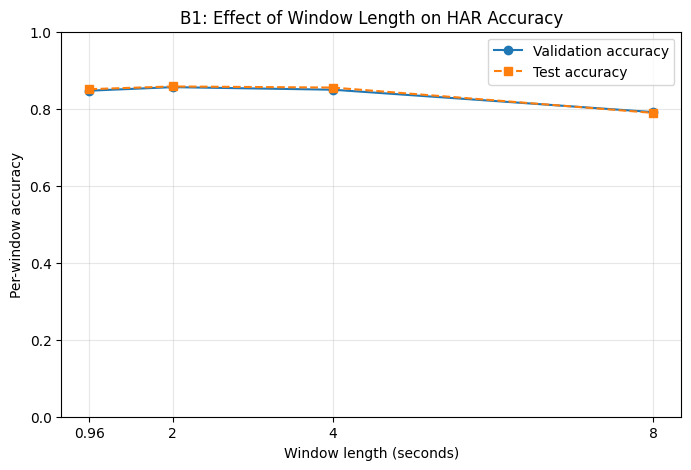

In [ ]:

windows = list(results_b1.keys())
seconds = [w / SAMPLING_FREQ for w in windows]
val_accs = [results_b1[w]["val_accuracy"] for w in windows]
test_accs = [results_b1[w]["test_accuracy"] for w in windows]

plt.figure(figsize=(8, 5))

plt.plot(seconds, val_accs, "o-", label="Validation accuracy")
plt.plot(seconds, test_accs, "s--", label="Test accuracy")

plt.xlabel("Window length (seconds)")
plt.ylabel("Per-window accuracy")
plt.title("B1: Effect of Window Length on HAR Accuracy")

plt.xticks(seconds, ["0.96", "2", "4", "8"])
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


## B2 · Hand-crafted features and a classical classifier

Before deep learning, activity recognition often used two steps: calculate **features** that summarise each window, then use a classical classifier to predict the activity. This approach is still useful for small sensor datasets because it is relatively simple to run and the features can be inspected directly. In this exercise, you will build a feature pipeline, train a **random forest**, and compare its results with the MLP from Part A.

### Which features?

The skeleton below already calculates five simple statistics for each axis and for the acceleration magnitude. These provide a starting point. The table lists other feature types commonly used in human activity recognition (HAR) and what they can capture in this dataset. You do not need to use all of them. Try different combinations and see which features improve the results.

| Family | Examples (per axis unless stated) | What it captures here |
|---|---|---|
| **Orientation** | mean of each axis | The direction of gravity, which gives information about posture (Lab 2). This can distinguish the four lying postures and sitting/standing. |
| **Intensity** | standard deviation, variance, energy (mean of squares), mean absolute deviation, range (max − min), interquartile range, signal magnitude area | The amount of movement. These features can help distinguish stationary activities from moving activities, as well as running from walking. |
| **Shape / variability** | skewness, kurtosis, number of zero-crossings or mean-crossings, mean absolute difference between consecutive samples | How the signal changes within the window. These features may help distinguish less regular movements from rhythmic activities. |
| **Between axes** | Pearson correlation between X–Y, X–Z, Y–Z | How the acceleration axes change together. For example, climbing stairs changes the relationship between the vertical and forward axes compared with level walking. |
| **Frequency domain** | dominant frequency and its power (`np.fft.rfft`), spectral energy in a few bands, spectral entropy | Repeated movement such as walking and running. Walking is roughly 1.5–2 steps/s, while running is around 2.5–3 steps/s. Shuffling is slower and less regular. At 12.5 Hz, frequencies up to 6.25 Hz can be represented. |
| **Orientation-free** | any of the above calculated on the magnitude $\sqrt{x^2+y^2+z^2}$ | Movement information that does not depend on the orientation of the sensor. This can help when the sensor position varies, but it does not provide information about posture. |

A few things to keep in mind:

* **Add features one family at a time** and check the validation accuracy and confusion matrix after each addition. This lets you see which feature groups improve the results.

* `rf.feature_importances_` gives an importance score for each feature. Keep the feature names alongside the output of `extract_features()` so you can see which features have the highest scores. You may find that orientation features are particularly useful for the stationary activities, while intensity and frequency features help with the moving activities.

* Random forests do not require feature scaling. `LogisticRegression` and k-nearest-neighbours do, so if you use either of these, fit a `StandardScaler` using the **training** features only, then apply the same scaler to the validation and test features.

* Calculate the features using NumPy on the whole `(n, window, 3)` array at once (`axis=1`), as in the skeleton. Avoid looping over all 18,000 windows in Python, as this will be slower.

### Which classifier?

Start with `RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)`. This gives you a starting point without needing to tune the model. Then try at least one of `LogisticRegression(max_iter=1000)`, `KNeighborsClassifier`, or `GradientBoostingClassifier` / `HistGradientBoostingClassifier`.

Use `evaluate()` from Part A to compare the classifiers by passing `clf.predict_proba` as the `predict_fn`.

In your results table, record:

- Which activities does the feature-based model classify correctly that the MLP gets wrong?
- Which activities does the MLP classify correctly that the feature-based model gets wrong?
- What is the smallest feature set that gives an accuracy within one or two percentage points of the full feature set?

### Could this run on the phone?

Not directly with TensorFlow Lite, because a random forest is not a TensorFlow model. There are two ways you could use this approach on the phone, although you do not need to implement either one for this exercise:

1. **Generate Dart code from the trained forest.** A decision tree is nothing but nested `if`/`else` on feature thresholds, so a forest can be exported as source code. The [m2cgen](https://github.com/BayesWitnesses/m2cgen) library does this for scikit-learn models and has a Dart target: `m2cgen.export_to_dart(rf)` returns a Dart function that maps a feature vector to class probabilities. The app would then compute the *same* features in Dart from its buffered window and call that function. Two things to watch: 200 unlimited-depth trees produce megabytes of Dart that the compiler will not like (retrain with something like `n_estimators=30, max_depth=10` and check what it costs you), and **feature parity** – the Dart features must be computed exactly as in Python (same order, same definition of standard deviation, same magnitude), which is why a saved example window with its feature vector and probabilities is essential for checking.
2. **Put the features inside a Keras model.** Write the feature extraction as a layer using TensorFlow operations (`tf.reduce_mean`, `tf.math.reduce_std`, `tf.reduce_min/max`, … are all supported by TFLite), add a small `Dense` head, train it, and convert it with `convert_to_tflite()` as in Part A. The classifier is then no longer a forest, but the whole model – features included – is one `.tflite` file and the app needs no change at all.

This is the trade-off behind Part A: a model that takes raw windows is the one with the least to re-implement on the phone.

### Resources

* D. Figo, P. C. Diniz, D. R. Ferreira and J. M. P. Cardoso, *Preprocessing techniques for context recognition from accelerometer data*, Personal and Ubiquitous Computing 14 (2010) – a readable survey of time-domain, frequency-domain and symbolic features for accelerometer data. https://link.springer.com/article/10.1007/s00779-010-0293-9
* The UCI *Human Activity Recognition Using Smartphones* dataset – its `features_info.txt` lists the 561 features used by a classic HAR pipeline (means, standard deviations, energies, correlations, FFT bands, …); a good catalogue to borrow from. https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones
* scikit-learn user guide: [Ensembles – random forests](https://scikit-learn.org/stable/modules/ensemble.html#random-forests) and [feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html) (permutation importance is more trustworthy than `feature_importances_` when features are correlated, as these are); [preprocessing / StandardScaler](https://scikit-learn.org/stable/modules/preprocessing.html).
* `scipy.stats.skew`, `scipy.stats.kurtosis` and `numpy.fft.rfft` / `numpy.fft.rfftfreq` for the shape and frequency features.
* [m2cgen](https://github.com/BayesWitnesses/m2cgen) – model-to-code generation, including Dart, for the phone route.

In [ ]:
# 看数据集对不对
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Window length:", X_train.shape[1])
print("Number of axes:", X_train.shape[2])


X_train: (18729, 50, 3)
X_val: (3997, 50, 3)
X_test: (4034, 50, 3)
Window length: 50
Number of axes: 3


In [ ]:
# 它将 Part A 的每个原始加速度窗口转换成两种版本：
# - 基础版：20 个统计特征（Mean、Std、Min、Max、Energy）。
# - 扩展版：28 个特征（额外增加 Range 和 Mean Absolute Difference）。
# 其中 Range 表示最大值减最小值，Difference 表示相邻采样点平均变化多大。
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

# Use Part A's original 4-second windows
assert X_train.shape[1:] == (50, 3), "Please restore Part A's 4-second windows first."

channels = list(AXES) + ["mag"]

def extract_features(X, extra=False):
    # Calculate acceleration magnitude
    mag = np.linalg.norm(X, axis=2, keepdims=True)
    sig = np.concatenate([X, mag], axis=2)

    # Five basic statistics for each of four channels
    feats = [
        sig.mean(axis=1),
        sig.std(axis=1),
        sig.min(axis=1),
        sig.max(axis=1),
        (sig ** 2).mean(axis=1)
    ]

    names = [
        f"{stat}_{ch}"
        for stat in ["mean", "std", "min", "max", "energy"]
        for ch in channels
    ]

    if extra:
        # Range: maximum minus minimum
        feats.append(np.ptp(sig, axis=1))
        names += [f"range_{ch}" for ch in channels]

        # Mean absolute difference between consecutive samples
        diff = np.abs(np.diff(sig, axis=1)).mean(axis=1)
        feats.append(diff)
        names += [f"diff_{ch}" for ch in channels]

    return np.concatenate(feats, axis=1), names


# Baseline: 20 features
F_train_20, names_20 = extract_features(X_train)
F_val_20, _ = extract_features(X_val)
F_test_20, _ = extract_features(X_test)

# Extended: 28 features
F_train_28, names_28 = extract_features(X_train, extra=True)
F_val_28, _ = extract_features(X_val, extra=True)
F_test_28, _ = extract_features(X_test, extra=True)

print("Original:", X_train.shape)
print("Basic features:", F_train_20.shape)
print("Extended features:", F_train_28.shape)


Original: (18729, 50, 3)
Basic features: (18729, 20)
Extended features: (18729, 28)


In [ ]:
# 训练 Random Forest，并比较特征组合
# 模型	特征数量
# Random Forest	20
# Random Forest	24
# Random Forest	28
# Logistic Regression	28
# 这样我们就能回答：

# 增加特征是否让模型更加准确？Random Forest 是否比 Logistic Regression 更好？

results_b2 = []

# Three feature sets:
# 20 basic features
# 24 features: basic + range
# 28 features: basic + range + difference

feature_sets = [
    ("Basic 20", F_train_28[:, :20], F_val_28[:, :20]),
    ("Basic + Range 24", F_train_28[:, :24], F_val_28[:, :24]),
    ("Extended 28", F_train_28, F_val_28)
]

rf_models = {}

for name, train_features, val_features in feature_sets:
    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1
    )

    rf.fit(train_features, y_train)
    pred = rf.predict(val_features)

    acc = accuracy_score(y_val, pred)
    rf_models[name] = rf

    results_b2.append({
        "Model": "Random Forest",
        "Features": name,
        "Feature count": train_features.shape[1],
        "Validation accuracy": acc
    })

# Try another classifier, with scaling
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED)
)

lr.fit(F_train_28, y_train)
lr_acc = accuracy_score(y_val, lr.predict(F_val_28))

results_b2.append({
    "Model": "Logistic Regression",
    "Features": "Extended 28",
    "Feature count": 28,
    "Validation accuracy": lr_acc
})

b2_results = pd.DataFrame(results_b2)
display(b2_results.sort_values("Validation accuracy", ascending=False))


,Model,Features,Feature count,Validation accuracy
3,Logistic Regression,Extended 28,28,0.825369
2,Random Forest,Extended 28,28,0.812359
1,Random Forest,Basic + Range 24,24,0.794096
0,Random Forest,Basic 20,20,0.793345


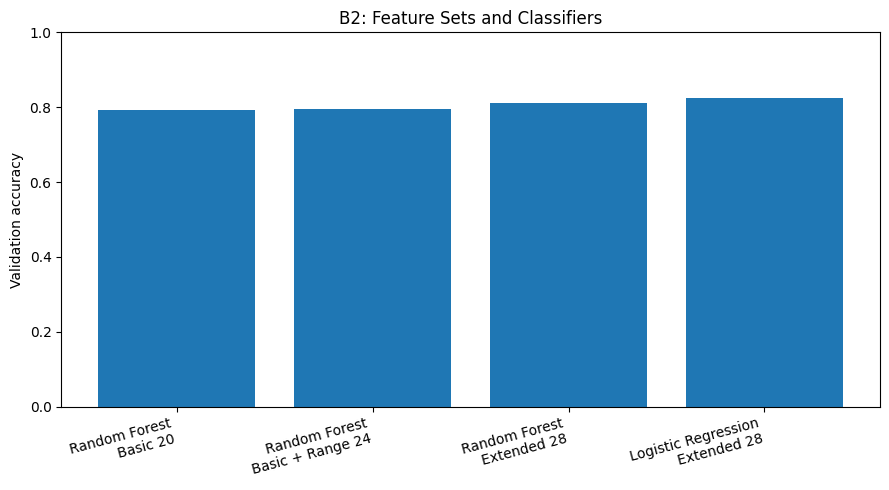

In [ ]:
# 画图比较准确率

plt.figure(figsize=(9, 5))

labels = b2_results["Model"] + "\n" + b2_results["Features"]
scores = b2_results["Validation accuracy"]

plt.bar(labels, scores)
plt.ylabel("Validation accuracy")
plt.title("B2: Feature Sets and Classifiers")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


Best model:
Model                  Logistic Regression
Features                       Extended 28
Feature count                           28
Validation accuracy               0.825369
Name: 3, dtype: object

Smallest feature set within 2 percentage points:
Model                  Random Forest
Features                 Extended 28
Feature count                     28
Validation accuracy         0.812359
Name: 2, dtype: object


,Feature,Importance
13,max_accelY,0.076880
10,min_accelZ,0.062357
2,mean_accelZ,0.061628
9,min_accelY,0.058675
27,diff_mag,0.052378
25,diff_accelY,0.048679
14,max_accelZ,0.047522
7,std_mag,0.044504
0,mean_accelX,0.041954
8,min_accelX,0.040488


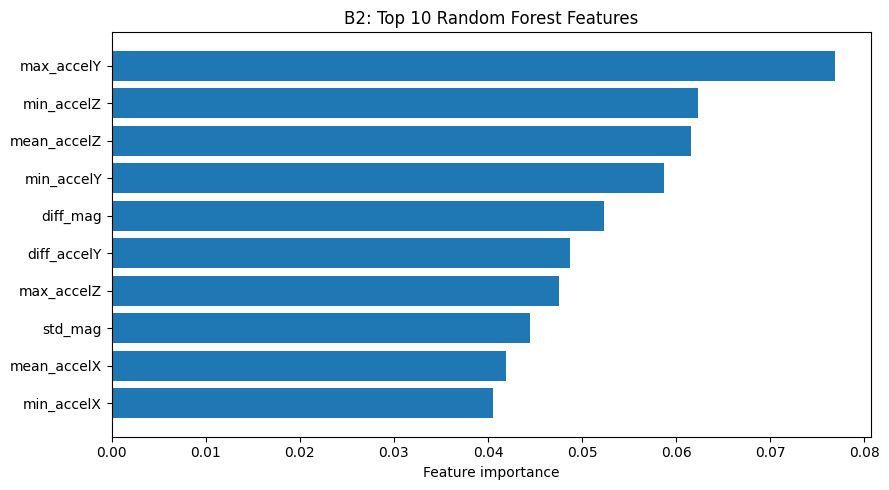

In [ ]:
# 选择模型，检查 Feature Importance

# Select the best model using validation accuracy
best_idx = b2_results["Validation accuracy"].idxmax()
best_row = b2_results.loc[best_idx]

print("Best model:")
print(best_row)

# Select the corresponding model and features
if best_row["Model"] == "Random Forest":
    best_model = rf_models[best_row["Features"]]
else:
    best_model = lr

feature_count = int(best_row["Feature count"])
best_F_test = F_test_28[:, :feature_count]

# Find the smallest feature set within 2 percentage points
best_acc = b2_results["Validation accuracy"].max()

near_best = b2_results[
    b2_results["Validation accuracy"] >= best_acc - 0.02
]

smallest = near_best.sort_values("Feature count").iloc[0]

print("\nSmallest feature set within 2 percentage points:")
print(smallest)

# Show feature importance for the best Random Forest
rf_rows = b2_results[b2_results["Model"] == "Random Forest"]
best_rf_row = rf_rows.sort_values(
    "Validation accuracy", ascending=False
).iloc[0]

best_rf = rf_models[best_rf_row["Features"]]
rf_count = int(best_rf_row["Feature count"])

importance = pd.DataFrame({
    "Feature": names_28[:rf_count],
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(10))

plt.figure(figsize=(9, 5))
top10 = importance.head(10).iloc[::-1]
plt.barh(top10["Feature"], top10["Importance"])
plt.xlabel("Feature importance")
plt.title("B2: Top 10 Random Forest Features")
plt.tight_layout()
plt.show()


B2: Best Feature-Based Model  per-window accuracy: 0.857
B2: Best Feature-Based Model  per-recording accuracy (majority vote over windows): 0.892
                 precision    recall  f1-score   support

sittingStanding      0.908     0.918     0.913       781
      lyingBack      0.951     1.000     0.975       332
      lyingLeft      0.996     0.943     0.969       263
     lyingRight      0.958     1.000     0.978       249
   lyingStomach      1.000     1.000     1.000       360
  normalWalking      0.649     0.677     0.663       350
 shuffleWalking      0.696     0.749     0.721       346
      ascending      0.782     0.662     0.717       346
     descending      0.813     0.757     0.784       304
        running      0.931     0.941     0.936       358
   miscMovement      0.741     0.754     0.747       345

       accuracy                          0.857      4034
      macro avg      0.857     0.855     0.855      4034
   weighted avg      0.858     0.857     0.857      40

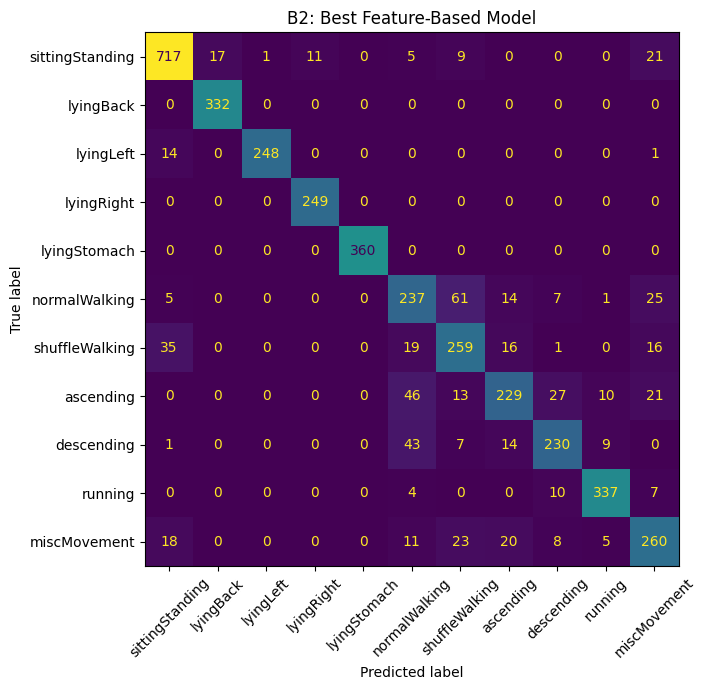


Part A MLP test accuracy: 0.8507684680218146
Part B2 test accuracy: 0.8572136836886465
Difference: 0.006445215666831872


In [ ]:
# 用 Part A 的评价函数测试最佳模型
# Evaluate the selected B2 model on the test set
b2_acc = evaluate(
    best_model.predict_proba,
    best_F_test,
    y_test,
    rec_id_test,
    title="B2: Best Feature-Based Model"
)

print("\nPart A MLP test accuracy:", mlp_acc)
print("Part B2 test accuracy:", b2_acc)
print("Difference:", b2_acc - mlp_acc)


In [ ]:
# 比较不同活动的识别效果
from sklearn.metrics import recall_score

# Predictions from Part A MLP
mlp_pred = model.predict(
    X_test, batch_size=512, verbose=0
).argmax(axis=1)

# Predictions from selected B2 model
b2_pred = best_model.predict(best_F_test)

# Per-class recall (correctly identified proportion)
class_ids = np.arange(len(CLASSES))

mlp_recall = recall_score(
    y_test, mlp_pred,
    labels=class_ids, average=None, zero_division=0
)

b2_recall = recall_score(
    y_test, b2_pred,
    labels=class_ids, average=None, zero_division=0
)

comparison = pd.DataFrame({
    "Activity": CLASSES,
    "MLP recall": mlp_recall,
    "B2 recall": b2_recall,
    "Difference": b2_recall - mlp_recall
})

display(comparison.sort_values("Difference", ascending=False))

# Directly compare individual window predictions
b2_only = (b2_pred == y_test) & (mlp_pred != y_test)
mlp_only = (mlp_pred == y_test) & (b2_pred != y_test)

print("Windows correct only in B2:", b2_only.sum())
print("Windows correct only in MLP:", mlp_only.sum())

# Number of exclusive correct predictions by activity
exclusive = pd.DataFrame({
    "Activity": CLASSES,
    "B2 only correct": [
        np.sum(b2_only & (y_test == i))
        for i in class_ids
    ],
    "MLP only correct": [
        np.sum(mlp_only & (y_test == i))
        for i in class_ids
    ]
})

display(exclusive)


,Activity,MLP recall,B2 recall,Difference
5,normalWalking,0.591429,0.677143,0.085714
10,miscMovement,0.692754,0.753623,0.060870
0,sittingStanding,0.896287,0.918054,0.021767
8,descending,0.750000,0.756579,0.006579
1,lyingBack,1.000000,1.000000,0.000000
2,lyingLeft,0.942966,0.942966,0.000000
3,lyingRight,1.000000,1.000000,0.000000
4,lyingStomach,1.000000,1.000000,0.000000
9,running,0.960894,0.941341,-0.019553
6,shuffleWalking,0.771676,0.748555,-0.023121


Windows correct only in B2: 254
Windows correct only in MLP: 228


,Activity,B2 only correct,MLP only correct
0,sittingStanding,23,6
1,lyingBack,0,0
2,lyingLeft,0,0
3,lyingRight,0,0
4,lyingStomach,0,0
5,normalWalking,70,40
6,shuffleWalking,43,51
7,ascending,32,61
8,descending,38,36
9,running,0,7


### B2 — Results and Analysis

We compared Random Forest and Logistic Regression classifiers using 20, 24 and 28 hand-crafted features extracted from 4-second accelerometer windows.

Adding range features produced little improvement in Random Forest validation accuracy, whereas adding temporal difference features increased accuracy from 79.41% to 81.24%. Logistic Regression with 28 features achieved the highest validation accuracy (82.54%) and a test accuracy of approximately 85.7%.

The feature-based model performed better than the Part A MLP on normalWalking (67.7% vs 59.1% recall) and miscMovement (75.4% vs 69.3%). However, the MLP performed better on ascending (74.6% vs 66.2%) and running (96.1% vs 94.1%).

The two models also made different errors: 254 test windows were classified correctly only by the feature-based model, while 228 were classified correctly only by the MLP. This suggests that statistical features and raw time-series representations capture complementary information.

Although the 28-feature model performed best among the configurations tested, further feature selection would be needed to determine whether a smaller subset could retain similar accuracy.

## B3 · A 1-D convolutional network

The MLP treats all 150 values in a window as separate inputs. This means it has to learn that the same movement can occur at different points in the window.

A **1-D convolution** looks at small sections of the signal as it moves along the time axis. This makes it easier for the model to recognise patterns such as steps, turns, and other movements wherever they occur. CNNs are commonly used for accelerometer-based activity recognition and should give better results than the MLP, particularly for the moving classes.

Complete `build_cnn()` below. A good starting point is:

- two `Conv1D` layers with 32 and 64 filters
- `kernel_size=5` and `relu` activation
- `MaxPooling1D(2)` after each convolution
- `GlobalAveragePooling1D()` (or `Flatten()`)
- `Dropout`
- a softmax output layer

Keep the `Normalization` layer as the first layer.

Train and evaluate the model, then convert it and check that the converted model gives the same results as in Part A.

Once the basic CNN is working, try a few changes to improve its performance. For example, you could increase the number of filters, add `BatchNormalization`, add a third convolutional block, or change the kernel size. Use the validation set to compare these versions.

Finally, compare the CNN with the MLP in terms of **accuracy, model size, and inference time**.

In [ ]:

# B3: Build the baseline 1-D CNN

def build_cnn(window: int = WINDOW,
              n_classes: int = len(CLASSES)) -> keras.Model:

    # 1. Normalise the accelerometer data
    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_train)

    # 2. Build the CNN
    cnn = keras.Sequential([
        keras.Input(shape=(window, 3), name="window"),

        norm,

        # First convolutional block
        layers.Conv1D(
            filters=32,
            kernel_size=5,
            activation="relu"
        ),
        layers.MaxPooling1D(pool_size=2),

        # Second convolutional block
        layers.Conv1D(
            filters=64,
            kernel_size=5,
            activation="relu"
        ),
        layers.MaxPooling1D(pool_size=2),

        # Summarise features across time
        layers.GlobalAveragePooling1D(),

        # Reduce overfitting
        layers.Dropout(0.2),

        # Output probabilities for 11 activities
        layers.Dense(
            n_classes,
            activation="softmax",
            name="probabilities"
        )
    ], name="har_cnn")

    return cnn


# Check that Part A's 4-second windows are being used
assert X_train.shape[1:] == (50, 3)
assert X_val.shape[1:] == (50, 3)
assert X_test.shape[1:] == (50, 3)

# Create a new CNN
cnn = build_cnn()

# Configure the training process
cnn.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Show the model architecture
cnn.summary()


Model: "har_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 46, 32)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 23, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 19, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,538 (45.07 KB)

 Trainable params: 11,531 (45.04 KB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6399 - loss: 1.0734 - val_accuracy: 0.7205 - val_loss: 0.8004
Epoch 2/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7662 - loss: 0.6619 - val_accuracy: 0.8074 - val_loss: 0.6591
Epoch 3/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8270 - loss: 0.5285 - val_accuracy: 0.8461 - val_loss: 0.5778
Epoch 4/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8570 - loss: 0.4484 - val_accuracy: 0.8591 - val_loss: 0.5394
Epoch 5/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8745 - loss: 0.4026 - val_accuracy: 0.8689 - val_loss: 0.5198
Epoch 6/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8878 - loss: 0.3691 - val_accuracy: 0.8712 - val_loss: 0.5078
Epoch 7/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8952 - loss: 0.3440 - val_accuracy: 0.8789 - val_loss: 0.4939
Epoch 8/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9018 - loss: 0.3243 - val_accuracy: 0.

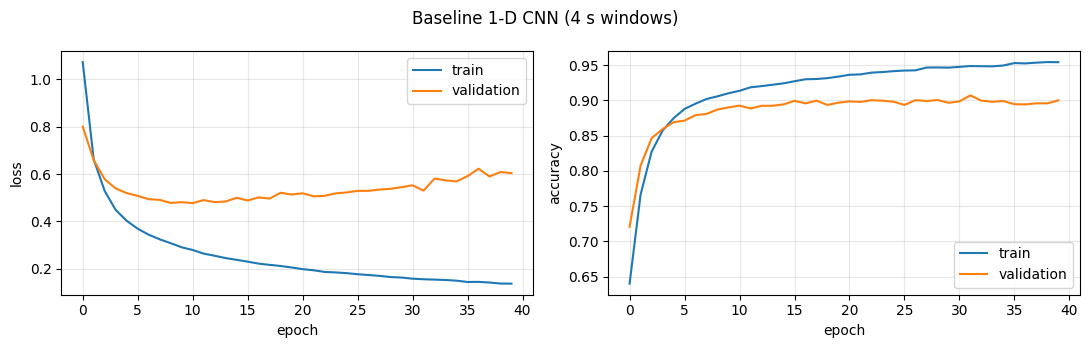

Best epoch: 32
Best validation accuracy: 0.9069


In [ ]:

# B3: Train the baseline CNN

cnn_history = train(
    cnn,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    verbose=1
)

# Visualise training and validation performance
plot_history(cnn_history, "Baseline 1-D CNN (4 s windows)")

# Record the best validation accuracy
best_cnn_epoch = int(np.argmax(cnn_history.history["val_accuracy"]))
best_cnn_val_acc = cnn_history.history["val_accuracy"][best_cnn_epoch]

print(f"Best epoch: {best_cnn_epoch + 1}")
print(f"Best validation accuracy: {best_cnn_val_acc:.4f}")


In [ ]:

# B3 Experiment 2: CNN with BatchNormalization

def build_cnn_bn(window=WINDOW, n_classes=len(CLASSES)):

    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_train)

    model_bn = keras.Sequential([
        keras.Input(shape=(window, 3), name="window"),
        norm,

        # First convolutional block
        layers.Conv1D(32, kernel_size=5, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling1D(2),

        # Second convolutional block
        layers.Conv1D(64, kernel_size=5, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling1D(2),

        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.2),
        layers.Dense(n_classes, activation="softmax",
                     name="probabilities")
    ], name="har_cnn_bn")

    return model_bn


cnn_bn = build_cnn_bn()

cnn_bn.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_bn.summary()


Model: "har_cnn_bn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 46, 32)         │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 46, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 46, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 23, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 19, 64)         │        10,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 19, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,826 (46.20 KB)

 Trainable params: 11,627 (45.42 KB)

 Non-trainable params: 199 (800.00 B)

Epoch 1/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7167 - loss: 0.8884 - val_accuracy: 0.7621 - val_loss: 0.7339
Epoch 2/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8352 - loss: 0.5325 - val_accuracy: 0.8524 - val_loss: 0.5038
Epoch 3/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8654 - loss: 0.4373 - val_accuracy: 0.8784 - val_loss: 0.4605
Epoch 4/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8823 - loss: 0.3871 - val_accuracy: 0.8829 - val_loss: 0.4558
Epoch 5/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8896 - loss: 0.3606 - val_accuracy: 0.8824 - val_loss: 0.4459
Epoch 6/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8992 - loss: 0.3349 - val_accuracy: 0.8852 - val_loss: 0.4584
Epoch 7/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9017 - loss: 0.3168 - val_accuracy: 0.8859 - val_loss: 0.4400
Epoch 8/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9081 - loss: 0.3033 - val_accuracy: 0.

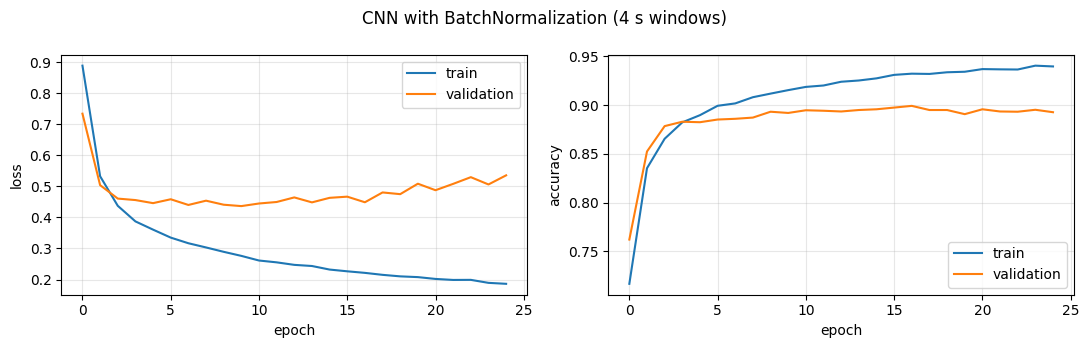

Baseline CNN validation accuracy: 0.9069
CNN + BatchNorm validation accuracy: 0.8992
Difference: -0.78 percentage points


In [ ]:

# Train the CNN with BatchNormalization

cnn_bn_history = train(
    cnn_bn,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    verbose=1
)

plot_history(
    cnn_bn_history,
    "CNN with BatchNormalization (4 s windows)"
)

# Compare validation performance
baseline_val = max(cnn_history.history["val_accuracy"])
bn_val = max(cnn_bn_history.history["val_accuracy"])

print(f"Baseline CNN validation accuracy: {baseline_val:.4f}")
print(f"CNN + BatchNorm validation accuracy: {bn_val:.4f}")
print(f"Difference: {(bn_val - baseline_val) * 100:+.2f} percentage points")


In [ ]:

# B3 Experiment 3: CNN with kernel size 3

def build_cnn_k3(window=WINDOW, n_classes=len(CLASSES)):

    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_train)

    model_k3 = keras.Sequential([
        keras.Input(shape=(window, 3), name="window"),
        norm,

        layers.Conv1D(32, kernel_size=3, activation="relu"),
        layers.MaxPooling1D(2),

        layers.Conv1D(64, kernel_size=3, activation="relu"),
        layers.MaxPooling1D(2),

        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.2),

        layers.Dense(
            n_classes,
            activation="softmax",
            name="probabilities"
        )
    ], name="har_cnn_k3")

    return model_k3


cnn_k3 = build_cnn_k3()

cnn_k3.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_k3.summary()


Model: "har_cnn_k3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 48, 32)         │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 22, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 11, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,250 (28.32 KB)

 Trainable params: 7,243 (28.29 KB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6099 - loss: 1.1998 - val_accuracy: 0.7265 - val_loss: 0.8580
Epoch 2/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7336 - loss: 0.7432 - val_accuracy: 0.7681 - val_loss: 0.7452
Epoch 3/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7755 - loss: 0.6301 - val_accuracy: 0.8026 - val_loss: 0.6754
Epoch 4/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8071 - loss: 0.5495 - val_accuracy: 0.8191 - val_loss: 0.6360
Epoch 5/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8284 - loss: 0.5011 - val_accuracy: 0.8331 - val_loss: 0.6078
Epoch 6/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8429 - loss: 0.4638 - val_accuracy: 0.8471 - val_loss: 0.5945
Epoch 7/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8566 - loss: 0.4343 - val_accuracy: 0.8566 - val_loss: 0.5701
Epoch 8/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8665 - loss: 0.4077 - val_accuracy: 0.

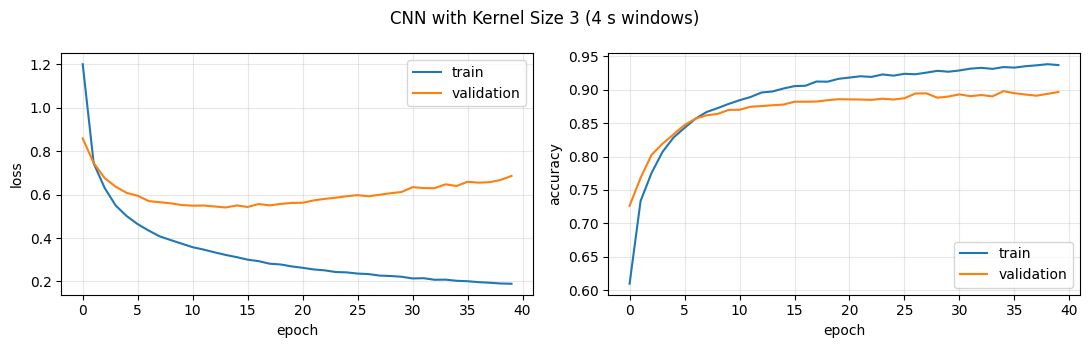

                  Model  Best val accuracy  Best epoch  Parameters
Baseline CNN (kernel=5)           0.906930          32       11538
        CNN + BatchNorm           0.899174          17       11826
         CNN (kernel=3)           0.897673          35        7250


In [ ]:

# Train CNN with kernel size 3

cnn_k3_history = train(
    cnn_k3,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    verbose=1
)

plot_history(
    cnn_k3_history,
    "CNN with Kernel Size 3 (4 s windows)"
)

# Compare all three experiments
results_b3 = pd.DataFrame({
    "Model": [
        "Baseline CNN (kernel=5)",
        "CNN + BatchNorm",
        "CNN (kernel=3)"
    ],
    "Best val accuracy": [
        max(cnn_history.history["val_accuracy"]),
        max(cnn_bn_history.history["val_accuracy"]),
        max(cnn_k3_history.history["val_accuracy"])
    ],
    "Best epoch": [
        np.argmax(cnn_history.history["val_accuracy"]) + 1,
        np.argmax(cnn_bn_history.history["val_accuracy"]) + 1,
        np.argmax(cnn_k3_history.history["val_accuracy"]) + 1
    ],
    "Parameters": [
        cnn.count_params(),
        cnn_bn.count_params(),
        cnn_k3.count_params()
    ]
})

print(results_b3.to_string(index=False))


In [ ]:

# B3 Experiment 4: CNN with three convolutional layers

def build_cnn_3conv(window=WINDOW, n_classes=len(CLASSES)):

    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_train)

    model_3conv = keras.Sequential([
        keras.Input(shape=(window, 3), name="window"),
        norm,

        layers.Conv1D(32, kernel_size=5, activation="relu"),
        layers.MaxPooling1D(2),

        layers.Conv1D(64, kernel_size=5, activation="relu"),
        layers.MaxPooling1D(2),

        # Additional convolutional layer
        layers.Conv1D(64, kernel_size=3, activation="relu"),

        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.2),

        layers.Dense(
            n_classes,
            activation="softmax",
            name="probabilities"
        )
    ], name="har_cnn_3conv")

    return model_3conv


cnn_3conv = build_cnn_3conv()

cnn_3conv.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_3conv.summary()


Model: "har_cnn_3conv"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 46, 32)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 23, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 19, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 7, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,890 (93.32 KB)

 Trainable params: 23,883 (93.29 KB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6570 - loss: 0.9935 - val_accuracy: 0.7461 - val_loss: 0.7353
Epoch 2/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8066 - loss: 0.5624 - val_accuracy: 0.8374 - val_loss: 0.5608
Epoch 3/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8706 - loss: 0.4135 - val_accuracy: 0.8621 - val_loss: 0.5141
Epoch 4/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8903 - loss: 0.3556 - val_accuracy: 0.8744 - val_loss: 0.4857
Epoch 5/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9035 - loss: 0.3166 - val_accuracy: 0.8787 - val_loss: 0.4859
Epoch 6/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9079 - loss: 0.2939 - val_accuracy: 0.8789 - val_loss: 0.4747
Epoch 7/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9133 - loss: 0.2748 - val_accuracy: 0.8837 - val_loss: 0.4798
Epoch 8/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9178 - loss: 0.2575 - val_accuracy: 0.

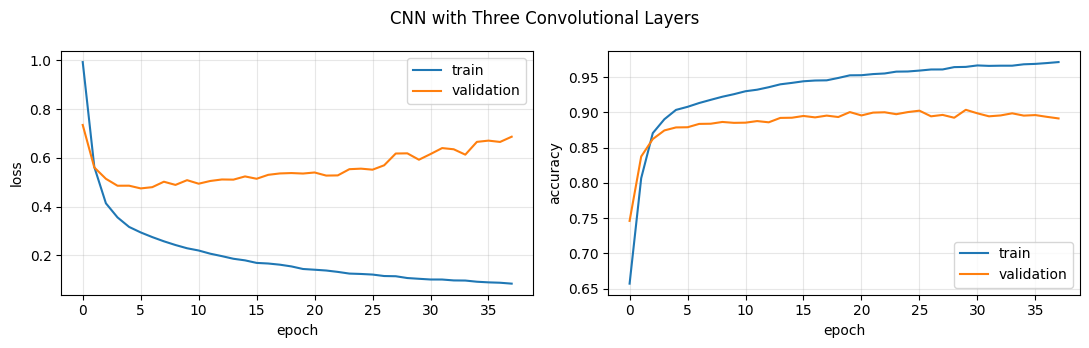

                  Model  Best val accuracy  Best epoch  Parameters
Baseline CNN (kernel=5)           0.906930          32       11538
    CNN (3 conv layers)           0.903678          30       23890
        CNN + BatchNorm           0.899174          17       11826
         CNN (kernel=3)           0.897673          35        7250


In [ ]:

# Train the three-layer CNN

cnn_3conv_history = train(
    cnn_3conv,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    verbose=1
)

plot_history(
    cnn_3conv_history,
    "CNN with Three Convolutional Layers"
)

# Add the result to our comparison table
results_b3.loc[len(results_b3)] = {
    "Model": "CNN (3 conv layers)",
    "Best val accuracy": max(
        cnn_3conv_history.history["val_accuracy"]
    ),
    "Best epoch": np.argmax(
        cnn_3conv_history.history["val_accuracy"]
    ) + 1,
    "Parameters": cnn_3conv.count_params()
}

print(
    results_b3.sort_values(
        "Best val accuracy",
        ascending=False
    ).to_string(index=False)
)


B3 Baseline CNN - Test  per-window accuracy: 0.908
B3 Baseline CNN - Test  per-recording accuracy (majority vote over windows): 0.917
                 precision    recall  f1-score   support

sittingStanding      0.945     0.901     0.923       781
      lyingBack      0.951     1.000     0.975       332
      lyingLeft      0.996     0.943     0.969       263
     lyingRight      0.958     1.000     0.978       249
   lyingStomach      0.963     1.000     0.981       360
  normalWalking      0.874     0.734     0.798       350
 shuffleWalking      0.780     0.841     0.809       346
      ascending      0.920     0.899     0.909       346
     descending      0.939     0.905     0.921       304
        running      0.989     0.975     0.982       358
   miscMovement      0.704     0.829     0.762       345

       accuracy                          0.908      4034
      macro avg      0.911     0.912     0.910      4034
   weighted avg      0.912     0.908     0.908      4034



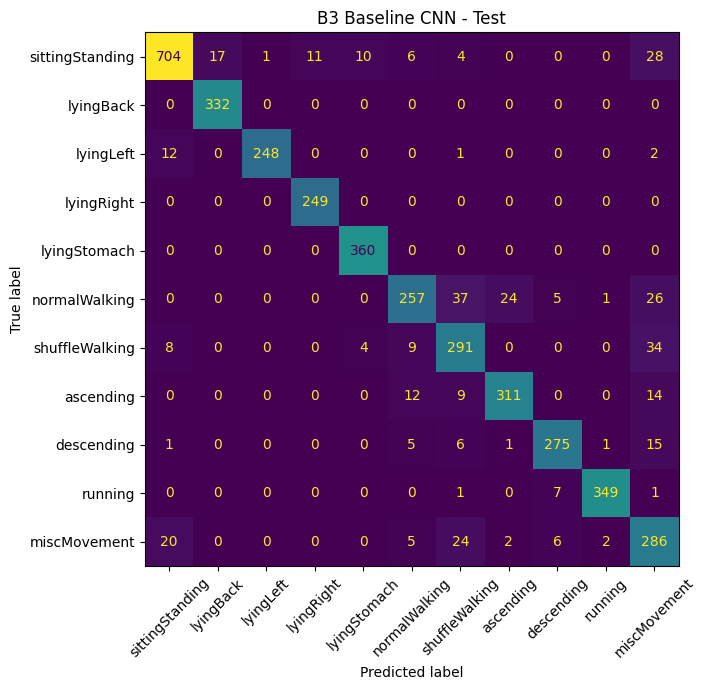

Final CNN test accuracy: 0.9078


In [ ]:

# B3: Final test evaluation of the selected CNN

# Use the selected baseline CNN
best_cnn = cnn

# Predict class probabilities using Keras
cnn_predict = lambda X: best_cnn.predict(
    X,
    batch_size=512,
    verbose=0
)

# Reuse Part A's evaluation function
cnn_test_acc = evaluate(
    cnn_predict,
    X_test,
    y_test,
    rec_id=rec_id_test,
    classes=CLASSES,
    title="B3 Baseline CNN - Test"
)

print(f"Final CNN test accuracy: {cnn_test_acc:.4f}")


### B3 — Final CNN Test Evaluation

The selected baseline 1-D CNN achieved a **per-window test accuracy of 90.8%** and a **per-recording accuracy of 91.7%** using majority voting. Its test accuracy was close to the best validation accuracy of 90.69%, suggesting good generalisation on the held-out test set despite signs of overfitting during training.

The CNN performed particularly well on static postures, achieving 100% recall for lyingBack, lyingRight and lyingStomach. Running also achieved a high recall of 97.5%.

However, normalWalking remained challenging, with a recall of 73.4%. It was frequently confused with shuffleWalking, ascending and miscMovement. The miscMovement class also had relatively low precision (70.4%), indicating that several other activities were incorrectly assigned to this class.

Compared with the Part A MLP test accuracy of approximately 85.1%, the CNN achieved an improvement of approximately 5.7 percentage points. This is consistent with the potential benefit of learning local temporal patterns using 1-D convolution.

In [ ]:

# B3: Convert the selected CNN to TensorFlow Lite

cnn_tflite_path = convert_to_tflite(
    best_cnn,
    "har_cnn"
)

# Check the output file and metadata
print("\nTFLite file:", cnn_tflite_path)
print("TFLite size (KB):",
      cnn_tflite_path.stat().st_size / 1024)

print("\nModel metadata:")
print((OUT_DIR / "har_cnn_meta.json").read_text())


wrote har_cnn.tflite (51.0 kB) and har_cnn_meta.json

TFLite file: lab3_models/har_cnn.tflite
TFLite size (KB): 51.0234375

Model metadata:
{
  "model_file": "har_cnn.tflite",
  "task": "daily_activity",
  "sampling_frequency_hz": 12.5,
  "window_samples": 50,
  "step_samples": 25,
  "input": {
    "shape": [
      1,
      50,
      3
    ],
    "channels": [
      "accelX",
      "accelY",
      "accelZ"
    ],
    "units": "g (raw accelerometer values)",
    "dtype": "float32"
  },
  "output": {
    "shape": [
      1,
      11
    ],
    "classes": [
      "sittingStanding",
      "lyingBack",
      "lyingLeft",
      "lyingRight",
      "lyingStomach",
      "normalWalking",
      "shuffleWalking",
      "ascending",
      "descending",
      "running",
      "miscMovement"
    ],
    "dtype": "float32"
  },
  "normalization": "inside the model \u2013 feed raw values"
}


In [ ]:

# B3: Verify TFLite predictions against Keras

cnn_p_lite = verify_tflite(
    cnn_tflite_path,
    best_cnn,
    X_test,
    y_test,
    name="har_cnn"
)

# Compare the two accuracies
cnn_lite_acc = accuracy_score(
    y_test,
    cnn_p_lite.argmax(axis=1)
)

print(f"\nKeras CNN accuracy: {cnn_test_acc:.4f}")
print(f"TFLite CNN accuracy: {cnn_lite_acc:.4f}")
print(f"Accuracy difference: {cnn_lite_acc - cnn_test_acc:+.6f}")


har_cnn.tflite: TFLite accuracy 0.908 · argmax agrees with Keras on 100.0% of windows · max |Δprob| = 6.85e-07 · 0.03 ms per window on this CPU

Keras CNN accuracy: 0.9078
TFLite CNN accuracy: 0.9078
Accuracy difference: +0.000000


In [ ]:

# B3: Final comparison between MLP and CNN

# Load both TFLite models
mlp_lite = TFLiteModel(OUT_DIR / "har_mlp.tflite")
cnn_lite = TFLiteModel(OUT_DIR / "har_cnn.tflite")

# Use the same test set for both models
mlp_probs = mlp_lite.predict(X_test)
cnn_probs = cnn_lite.predict(X_test)

mlp_preds = mlp_probs.argmax(axis=1)
cnn_preds = cnn_probs.argmax(axis=1)

# Calculate per-recording accuracy
def recording_accuracy(preds):
    votes = (
        pd.DataFrame({
            "rec": rec_id_test,
            "y": y_test,
            "pred": preds
        })
        .groupby("rec")
        .agg(
            y=("y", "first"),
            pred=("pred", lambda s: s.mode().iloc[0])
        )
    )
    return accuracy_score(votes["y"], votes["pred"])


# Measure inference time using the same method
def measure_time(lite_model, X, repeats=3):
    times = []

    # Warm up the interpreter
    for w in X[:10]:
        lite_model.predict_one(w)

    for _ in range(repeats):
        start = time.perf_counter()

        for w in X:
            lite_model.predict_one(w)

        elapsed = time.perf_counter() - start
        times.append(elapsed / len(X) * 1000)

    return np.median(times)


# Build the comparison table
comparison_b3 = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Test accuracy": [
        accuracy_score(y_test, mlp_preds),
        accuracy_score(y_test, cnn_preds)
    ],
    "Recording accuracy": [
        recording_accuracy(mlp_preds),
        recording_accuracy(cnn_preds)
    ],
    "TFLite size (KiB)": [
        (OUT_DIR / "har_mlp.tflite").stat().st_size / 1024,
        (OUT_DIR / "har_cnn.tflite").stat().st_size / 1024
    ],
    "Inference (ms/window)": [
        measure_time(mlp_lite, X_test),
        measure_time(cnn_lite, X_test)
    ]
})

print(comparison_b3.round(4).to_string(index=False))


Model  Test accuracy  Recording accuracy  TFLite size (KiB)  Inference (ms/window)
  MLP         0.8508              0.8958            50.9688                 0.0090
  CNN         0.9078              0.9167            51.0234                 0.0178


In [ ]:

# B3: Compare class recall and confusion patterns

from sklearn.metrics import recall_score

mlp_recall = recall_score(
    y_test, mlp_preds,
    labels=range(len(CLASSES)),
    average=None
)

cnn_recall = recall_score(
    y_test, cnn_preds,
    labels=range(len(CLASSES)),
    average=None
)

recall_comparison = pd.DataFrame({
    "Activity": CLASSES,
    "MLP recall": mlp_recall,
    "CNN recall": cnn_recall,
    "Change (pp)": (cnn_recall - mlp_recall) * 100
})

print("Per-class recall comparison:")
print(
    recall_comparison.round(3).to_string(index=False)
)

# Show the most frequent incorrect predictions
def top_confusions(y_true, y_pred, classes, top_n=5):
    cm = confusion_matrix(y_true, y_pred)
    errors = []

    for i in range(len(classes)):
        for j in range(len(classes)):
            if i != j and cm[i, j] > 0:
                errors.append((
                    classes[i],
                    classes[j],
                    int(cm[i, j])
                ))

    return sorted(
        errors,
        key=lambda x: x[2],
        reverse=True
    )[:top_n]


print("\nMLP top confusions:")
for item in top_confusions(y_test, mlp_preds, CLASSES):
    print(item)

print("\nCNN top confusions:")
for item in top_confusions(y_test, cnn_preds, CLASSES):
    print(item)


Per-class recall comparison:
       Activity  MLP recall  CNN recall  Change (pp)
sittingStanding       0.896       0.901        0.512
      lyingBack       1.000       1.000        0.000
      lyingLeft       0.943       0.943        0.000
     lyingRight       1.000       1.000        0.000
   lyingStomach       1.000       1.000        0.000
  normalWalking       0.591       0.734       14.286
 shuffleWalking       0.772       0.841        6.936
      ascending       0.746       0.899       15.318
     descending       0.750       0.905       15.461
        running       0.961       0.975        1.397
   miscMovement       0.693       0.829       13.623

MLP top confusions:
('normalWalking', 'ascending', 53)
('normalWalking', 'shuffleWalking', 47)
('ascending', 'normalWalking', 42)
('descending', 'normalWalking', 32)
('miscMovement', 'shuffleWalking', 27)

CNN top confusions:
('normalWalking', 'shuffleWalking', 37)
('shuffleWalking', 'miscMovement', 34)
('sittingStanding', 'miscMove

## B4 · A recurrent network

Recurrent layers such as `LSTM` and `GRU` process the window one sample at a time while keeping information from earlier samples. This can be useful for time-series data.

Build a model with either an `LSTM(32)` or `GRU(32)` layer after the normalisation layer. Train it and compare its performance with the CNN.

Then try converting the model to TFLite. The standard version will **fail** with an error mentioning `TensorListReserve`. This happens because the converter cannot represent the LSTM's loop using the standard TFLite operators.

There are two ways to fix this:

- `layers.LSTM(32, unroll=True)` – expands the loop into `WINDOW` copies of the LSTM cell. This allows the model to use the standard TFLite operators, so it can run on the phone without any extra libraries. The downside is that the model will be larger. **Use this option.**
- `converter.target_spec.supported_ops = [TFLITE_BUILTINS, SELECT_TF_OPS]` – keeps the loop as a TensorFlow operation. This produces a smaller model, but the app would need the "Flex delegate" library, which is large and is not included in the Lab 4 app.

Finally, compare the recurrent model with the CNN. Consider both **accuracy and inference time**, as well as the model size.

In [ ]:

# B4 Step 1: Build an LSTM model

def build_rnn(
    window: int = WINDOW,
    n_classes: int = len(CLASSES),
    units: int = 32
) -> keras.Model:

    # 1. Normalise using training data only
    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_train)

    # 2. Build the recurrent network
    rnn = keras.Sequential([
        keras.Input(shape=(window, 3), name="window"),

        norm,

        layers.LSTM(
            units,
            unroll=True
        ),

        layers.Dropout(0.2),

        layers.Dense(
            n_classes,
            activation="softmax",
            name="probabilities"
        )
    ], name="har_rnn")

    return rnn


# Check that the original 4-second windows are used
assert X_train.shape[1:] == (50, 3)
assert X_val.shape[1:] == (50, 3)
assert X_test.shape[1:] == (50, 3)

# Create the LSTM model
rnn = build_rnn()

# Configure training
rnn.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture and parameter count
rnn.summary()


Model: "har_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           363 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,978 (19.45 KB)

 Trainable params: 4,971 (19.42 KB)

 Non-trainable params: 7 (32.00 B)

Epoch 1/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.5035 - loss: 1.4959 - val_accuracy: 0.5739 - val_loss: 1.2254
Epoch 2/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5971 - loss: 1.1068 - val_accuracy: 0.6210 - val_loss: 1.1208
Epoch 3/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6382 - loss: 1.0210 - val_accuracy: 0.6620 - val_loss: 1.0424
Epoch 4/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6696 - loss: 0.9310 - val_accuracy: 0.6627 - val_loss: 1.0007
Epoch 5/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6952 - loss: 0.8638 - val_accuracy: 0.6688 - val_loss: 0.9876
Epoch 6/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7074 - loss: 0.8279 - val_accuracy: 0.6933 - val_loss: 0.8987
Epoch 7/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7164 - loss: 0.8064 - val_accuracy: 0.7205 - val_loss: 0.8924
Epoch 8/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7250 - loss: 0.7805 - val_accuracy:

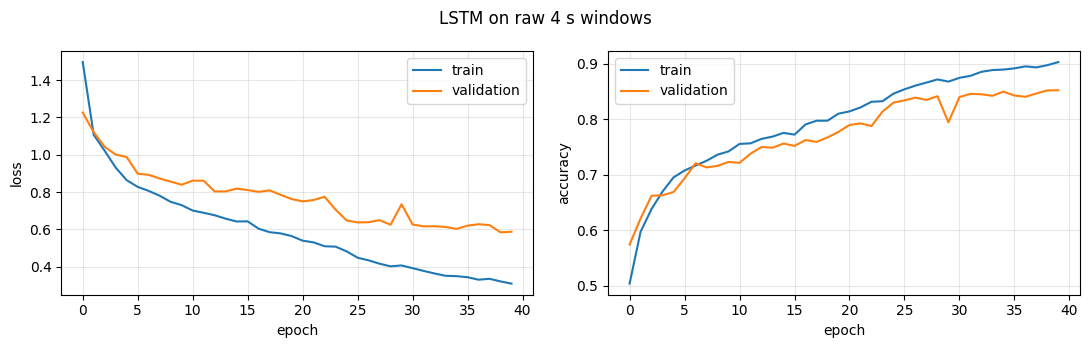

In [ ]:

# B4 Step 2: Train the LSTM

rnn_history = train(
    rnn,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    verbose=1
)

# Visualise training and validation performance
plot_history(rnn_history, "LSTM on raw 4 s windows")


LSTM  per-window accuracy: 0.867
LSTM  per-recording accuracy (majority vote over windows): 0.903
                 precision    recall  f1-score   support

sittingStanding      0.944     0.908     0.926       781
      lyingBack      0.985     1.000     0.993       332
      lyingLeft      0.973     0.943     0.958       263
     lyingRight      0.958     1.000     0.978       249
   lyingStomach      0.921     1.000     0.959       360
  normalWalking      0.729     0.691     0.710       350
 shuffleWalking      0.691     0.737     0.713       346
      ascending      0.793     0.844     0.818       346
     descending      0.924     0.717     0.807       304
        running      0.915     0.961     0.937       358
   miscMovement      0.696     0.725     0.710       345

       accuracy                          0.867      4034
      macro avg      0.866     0.866     0.864      4034
   weighted avg      0.869     0.867     0.867      4034



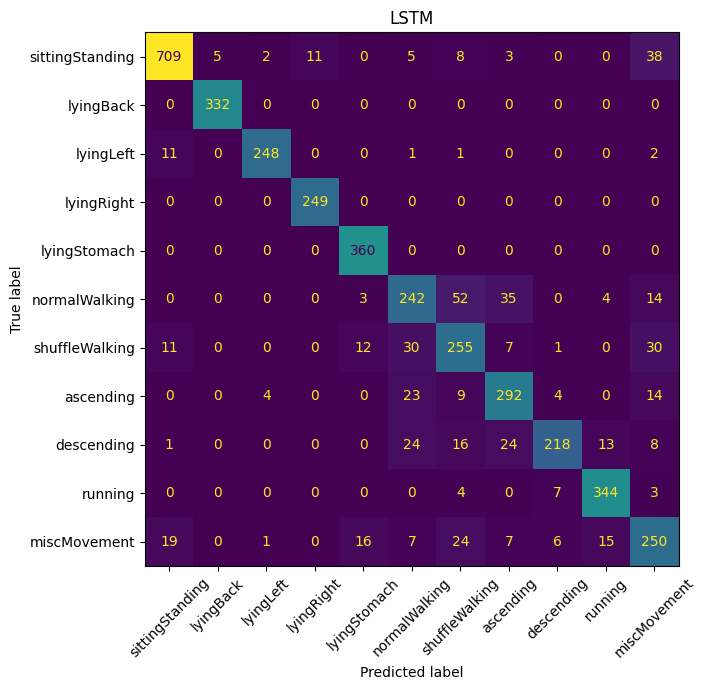

CNN test accuracy:  0.9078
LSTM test accuracy: 0.8674
Difference: -4.04 percentage points


In [ ]:

# B4 Step 3: Evaluate LSTM on the test set

# Use the trained LSTM to predict class probabilities
rnn_predict = lambda X: rnn.predict(
    X,
    batch_size=512,
    verbose=0
)

# Reuse the evaluation function from Part A
rnn_acc = evaluate(
    rnn_predict,
    X_test,
    y_test,
    rec_id_test,
    title="LSTM"
)

# Compare test accuracy with the previous CNN
print(f"CNN test accuracy:  {0.9078:.4f}")
print(f"LSTM test accuracy: {rnn_acc:.4f}")
print(f"Difference: {(rnn_acc - 0.9078) * 100:+.2f} percentage points")


In [ ]:

# B4 Step 4: Convert the LSTM to TFLite

# Convert and save the model
rnn_tflite_path = convert_to_tflite(
    rnn,
    "har_rnn"
)

# Display the model file size
rnn_size_kib = rnn_tflite_path.stat().st_size / 1024

print(f"LSTM TFLite size: {rnn_size_kib:.3f} KiB")

# Display metadata
print((OUT_DIR / "har_rnn_meta.json").read_text())


wrote har_rnn.tflite (152.4 kB) and har_rnn_meta.json
LSTM TFLite size: 152.418 KiB
{
  "model_file": "har_rnn.tflite",
  "task": "daily_activity",
  "sampling_frequency_hz": 12.5,
  "window_samples": 50,
  "step_samples": 25,
  "input": {
    "shape": [
      1,
      50,
      3
    ],
    "channels": [
      "accelX",
      "accelY",
      "accelZ"
    ],
    "units": "g (raw accelerometer values)",
    "dtype": "float32"
  },
  "output": {
    "shape": [
      1,
      11
    ],
    "classes": [
      "sittingStanding",
      "lyingBack",
      "lyingLeft",
      "lyingRight",
      "lyingStomach",
      "normalWalking",
      "shuffleWalking",
      "ascending",
      "descending",
      "running",
      "miscMovement"
    ],
    "dtype": "float32"
  },
  "normalization": "inside the model \u2013 feed raw values"
}


In [ ]:

# B4 Step 5: Verify TFLite predictions and measure inference time

# Reuse the verification function from Part A
rnn_p_lite = verify_tflite(
    rnn_tflite_path,
    rnn,
    X_test,
    y_test,
    name="har_rnn"
)

# Compare model sizes
cnn_size_kib = (OUT_DIR / "har_cnn.tflite").stat().st_size / 1024

print("\nTFLite model size comparison:")
print(f"CNN:  {cnn_size_kib:.3f} KiB")
print(f"LSTM: {rnn_size_kib:.3f} KiB")
print(f"LSTM / CNN size ratio: {rnn_size_kib / cnn_size_kib:.2f}x")


har_rnn.tflite: TFLite accuracy 0.867 · argmax agrees with Keras on 100.0% of windows · max |Δprob| = 2.15e-06 · 0.08 ms per window on this CPU

TFLite model size comparison:
CNN:  51.023 KiB
LSTM: 152.418 KiB
LSTM / CNN size ratio: 2.99x


## B5 · Class imbalance

There are about twice as many sitting/standing recordings as recordings from the other classes. This can make the model more likely to predict sitting/standing, especially when it is unsure.

Two common ways to deal with this are:

- **Class weights** – give more weight to the smaller classes during training. You can use `class_weight=` in `train()` and calculate the weights with `sklearn.utils.class_weight.compute_class_weight("balanced", ...)`.
- **Resampling** – reduce the number of sitting/standing recordings to match the other classes, or duplicate recordings from the smaller classes.

Try both approaches with your best model. Does either one improve the confusion matrix?

Pay particular attention to the **per-class recall** in the classification report rather than just the overall accuracy. Think about which types of mistakes would matter most in an app that, for example, is being used to track how long someone spends lying down.

B5: Training class distribution


,Activity,Train recordings,Train windows,Window percentage (%)
0,sittingStanding,245,3490,18.63
1,lyingBack,113,1568,8.37
2,lyingLeft,87,1206,6.44
3,lyingRight,84,1159,6.19
4,lyingStomach,121,1680,8.97
5,normalWalking,116,1610,8.60
6,shuffleWalking,118,1636,8.74
7,ascending,114,1588,8.48
8,descending,104,1442,7.70
9,running,122,1689,9.02


Total training recordings: 1343
Total training windows: 18729


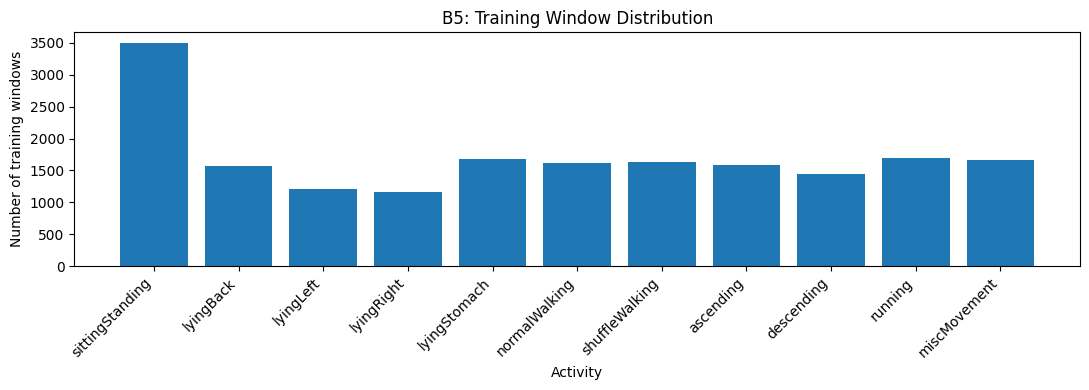

In [ ]:

# B5 Step 1: Inspect training class distribution

# Count recordings for each activity
recording_counts = (
    rec_train["label"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
)

# Count training windows for each activity
window_counts_b5 = np.bincount(
    y_train,
    minlength=len(CLASSES)
)

# Create a comparison table
class_distribution = pd.DataFrame({
    "Activity": CLASSES,
    "Train recordings": recording_counts.values,
    "Train windows": window_counts_b5
})

class_distribution["Window percentage (%)"] = (
    class_distribution["Train windows"]
    / len(y_train) * 100
)

print("B5: Training class distribution")
display(class_distribution.round(2))

print("Total training recordings:", len(rec_train))
print("Total training windows:", len(y_train))

# Visualise the training window distribution
plt.figure(figsize=(11, 4))
plt.bar(CLASSES, window_counts_b5)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Activity")
plt.ylabel("Number of training windows")
plt.title("B5: Training Window Distribution")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.utils.class_weight import compute_class_weight

# Calculate balanced class weights using training windows
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=y_train
)

# Map each class index to its weight
class_weight = dict(enumerate(weights))

# Display class weights
weight_table = pd.DataFrame({
    "Activity": CLASSES,
    "Train windows": window_counts_b5,
    "Class weight": weights
})

display(weight_table.round(3))
print("Class weight dictionary:", class_weight)


,Activity,Train windows,Class weight
0,sittingStanding,3490,0.488
1,lyingBack,1568,1.086
2,lyingLeft,1206,1.412
3,lyingRight,1159,1.469
4,lyingStomach,1680,1.013
5,normalWalking,1610,1.058
6,shuffleWalking,1636,1.041
7,ascending,1588,1.072
8,descending,1442,1.181
9,running,1689,1.008


Class weight dictionary: {0: np.float64(0.4878614222453764), 1: np.float64(1.0858650278293136), 2: np.float64(1.4118046132971507), 3: np.float64(1.469056396580124), 4: np.float64(1.013474025974026), 5: np.float64(1.0575381140598532), 6: np.float64(1.0407312736163592), 7: np.float64(1.0721891458667276), 8: np.float64(1.1807464380279915), 9: np.float64(1.0080736315194574), 10: np.float64(1.0250670461386897)}


trained 33 epochs in 55 s; best epoch 25: val accuracy 0.898


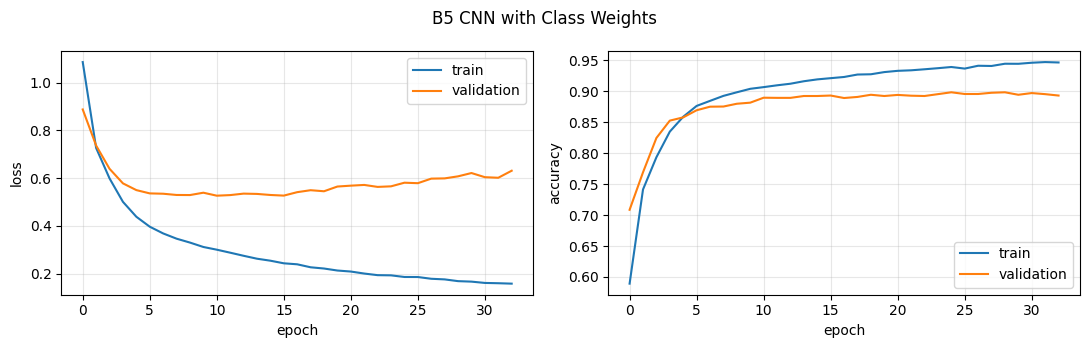

In [ ]:

# B5: Train CNN with balanced class weights

# Build a new baseline CNN
cnn_weighted = build_cnn()

# Configure the same training settings as B3
cnn_weighted.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train using class weights
cnn_weighted_history = train(
    cnn_weighted,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    class_weight=class_weight
)

# Plot training and validation curves
plot_history(
    cnn_weighted_history,
    "B5 CNN with Class Weights"
)


B5 Weighted CNN (Validation)  per-window accuracy: 0.898
                 precision    recall  f1-score   support

sittingStanding      0.925     0.976     0.950       737
      lyingBack      0.990     0.916     0.952       333
      lyingLeft      1.000     0.972     0.986       250
     lyingRight      0.907     0.940     0.923       249
   lyingStomach      0.997     0.967     0.982       363
  normalWalking      0.877     0.930     0.903       344
 shuffleWalking      0.784     0.775     0.780       347
      ascending      0.926     0.859     0.891       348
     descending      0.814     0.820     0.817       305
        running      0.956     0.953     0.954       361
   miscMovement      0.712     0.714     0.713       360

       accuracy                          0.898      3997
      macro avg      0.899     0.893     0.895      3997
   weighted avg      0.899     0.898     0.898      3997



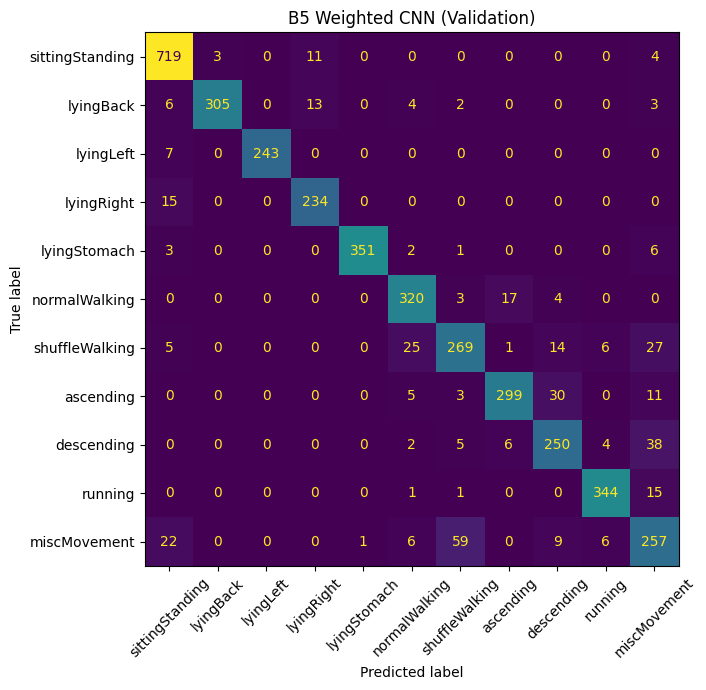

In [ ]:

# B5: Evaluate the weighted CNN on validation data

weighted_val_acc = evaluate(
    lambda X: cnn_weighted.predict(
        X,
        batch_size=512,
        verbose=0
    ),
    X_val,
    y_val,
    title="B5 Weighted CNN (Validation)"
)


In [ ]:

# B5: Compare baseline and weighted CNN recall on validation data

from sklearn.metrics import recall_score

# Predict with both models on the same validation set
y_pred_baseline = best_cnn.predict(
    X_val, batch_size=512, verbose=0
).argmax(axis=1)

y_pred_weighted = cnn_weighted.predict(
    X_val, batch_size=512, verbose=0
).argmax(axis=1)

# Calculate recall for each class
baseline_recall = recall_score(
    y_val, y_pred_baseline,
    labels=np.arange(len(CLASSES)),
    average=None,
    zero_division=0
)

weighted_recall = recall_score(
    y_val, y_pred_weighted,
    labels=np.arange(len(CLASSES)),
    average=None,
    zero_division=0
)

# Compare recall changes in percentage points
recall_comparison = pd.DataFrame({
    "Activity": CLASSES,
    "Baseline Recall (%)": baseline_recall * 100,
    "Weighted Recall (%)": weighted_recall * 100,
    "Change (pp)": (weighted_recall - baseline_recall) * 100
})

display(recall_comparison.round(2))


,Activity,Baseline Recall (%),Weighted Recall (%),Change (pp)
0,sittingStanding,96.74,97.56,0.81
1,lyingBack,91.59,91.59,0.00
2,lyingLeft,100.00,97.20,-2.80
3,lyingRight,93.98,93.98,0.00
4,lyingStomach,96.42,96.69,0.28
5,normalWalking,96.80,93.02,-3.78
6,shuffleWalking,80.69,77.52,-3.17
7,ascending,87.36,85.92,-1.44
8,descending,82.30,81.97,-0.33
9,running,95.29,95.29,0.00


In [ ]:

# B5: Undersample sittingStanding recordings

# Set the target number of sitting/standing recordings
target_count = 115

# Separate the majority class from other classes
rec_sitting = rec_train[
    rec_train["label"] == "sittingStanding"
]

rec_other = rec_train[
    rec_train["label"] != "sittingStanding"
]

# Randomly keep 115 sitting/standing recordings
rec_sitting_sampled = rec_sitting.sample(
    n=target_count,
    random_state=SEED
)

# Combine the sampled recordings with other classes
rec_train_under = pd.concat([
    rec_sitting_sampled,
    rec_other
]).sample(frac=1, random_state=SEED)

# Compare recording counts
recording_comparison = pd.DataFrame({
    "Activity": CLASSES,
    "Original": rec_train["label"].value_counts().reindex(
        CLASSES, fill_value=0
    ).values,
    "Undersampled": rec_train_under["label"].value_counts().reindex(
        CLASSES, fill_value=0
    ).values
})

display(recording_comparison)

print("Original recordings:", len(rec_train))
print("Undersampled recordings:", len(rec_train_under))


,Activity,Original,Undersampled
0,sittingStanding,245,115
1,lyingBack,113,113
2,lyingLeft,87,87
3,lyingRight,84,84
4,lyingStomach,121,121
5,normalWalking,116,116
6,shuffleWalking,118,118
7,ascending,114,114
8,descending,104,104
9,running,122,122


Original recordings: 1343
Undersampled recordings: 1213


In [ ]:

# B5: Create training windows from undersampled recordings

X_train_under, y_train_under, rec_id_train_under = windows_from_recordings(
    rec_train_under,
    window=WINDOW,
    step=STEP
)

# Compare the original and undersampled datasets
print("Original X_train shape:", X_train.shape)
print("Undersampled X_train shape:", X_train_under.shape)

print("Original y_train shape:", y_train.shape)
print("Undersampled y_train shape:", y_train_under.shape)

# Count windows for each activity
under_window_counts = np.bincount(
    y_train_under,
    minlength=len(CLASSES)
)

window_comparison = pd.DataFrame({
    "Activity": CLASSES,
    "Original windows": np.bincount(
        y_train,
        minlength=len(CLASSES)
    ),
    "Undersampled windows": under_window_counts
})

window_comparison["Change"] = (
    window_comparison["Undersampled windows"]
    - window_comparison["Original windows"]
)

display(window_comparison)

print("Total original windows:", len(y_train))
print("Total undersampled windows:", len(y_train_under))

# Check that window shape and labels are valid
assert X_train_under.shape[1:] == (WINDOW, 3)
assert len(X_train_under) == len(y_train_under)


Original X_train shape: (18729, 50, 3)
Undersampled X_train shape: (16870, 50, 3)
Original y_train shape: (18729,)
Undersampled y_train shape: (16870,)


,Activity,Original windows,Undersampled windows,Change
0,sittingStanding,3490,1631,-1859
1,lyingBack,1568,1568,0
2,lyingLeft,1206,1206,0
3,lyingRight,1159,1159,0
4,lyingStomach,1680,1680,0
5,normalWalking,1610,1610,0
6,shuffleWalking,1636,1636,0
7,ascending,1588,1588,0
8,descending,1442,1442,0
9,running,1689,1689,0


Total original windows: 18729
Total undersampled windows: 16870


trained 37 epochs in 56 s; best epoch 29: val accuracy 0.897


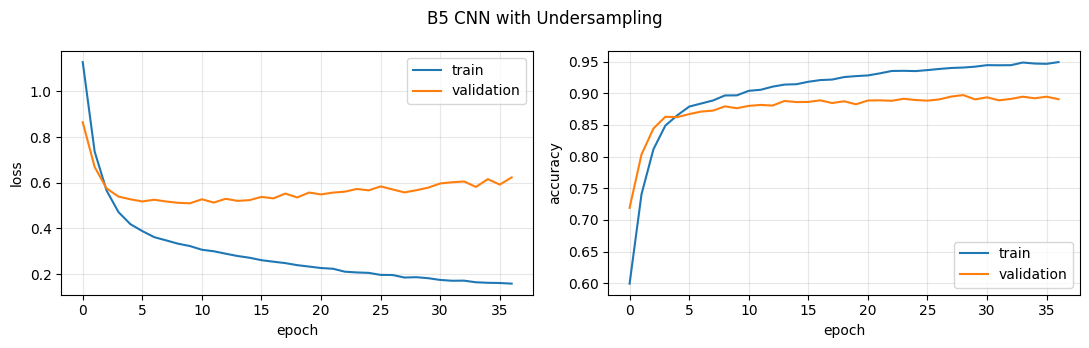

In [ ]:

# B5: Train CNN with undersampled data

# Build a new baseline CNN
cnn_under = build_cnn()

# Use the same training configuration as B3
cnn_under.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train with undersampled windows
cnn_under_history = train(
    cnn_under,
    X_train_under,
    y_train_under,
    X_val,
    y_val,
    epochs=40,
    batch_size=64
)

# Plot training and validation curves
plot_history(
    cnn_under_history,
    "B5 CNN with Undersampling"
)



B5 Undersampled CNN (Validation)  per-window accuracy: 0.897
                 precision    recall  f1-score   support

sittingStanding      0.946     0.974     0.960       737
      lyingBack      0.987     0.898     0.940       333
      lyingLeft      1.000     0.988     0.994       250
     lyingRight      0.907     0.940     0.923       249
   lyingStomach      0.994     0.970     0.982       363
  normalWalking      0.822     0.977     0.892       344
 shuffleWalking      0.743     0.767     0.755       347
      ascending      0.976     0.830     0.898       348
     descending      0.860     0.807     0.832       305
        running      0.959     0.964     0.961       361
   miscMovement      0.690     0.697     0.693       360

       accuracy                          0.897      3997
      macro avg      0.898     0.892     0.894      3997
   weighted avg      0.901     0.897     0.897      3997



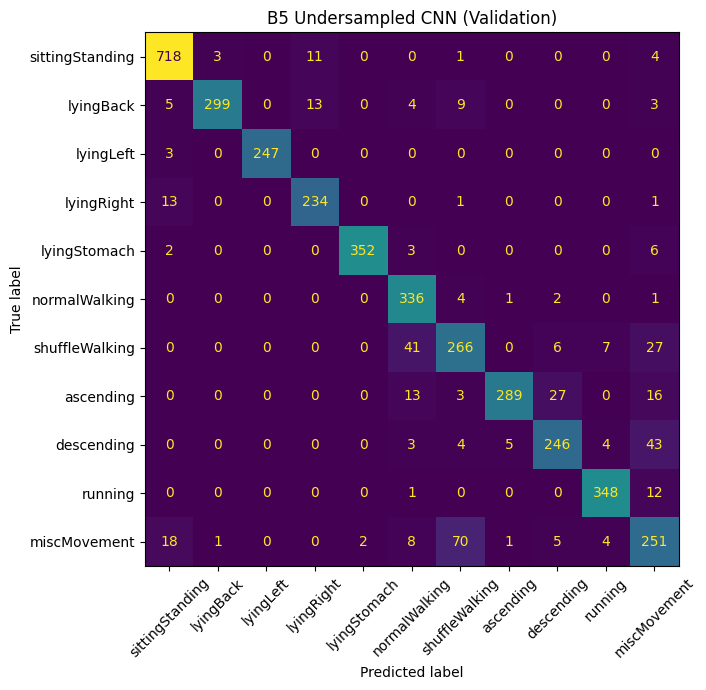

In [ ]:

# B5: Evaluate the undersampled CNN on validation data

under_val_acc = evaluate(
    lambda X: cnn_under.predict(
        X,
        batch_size=512,
        verbose=0
    ),
    X_val,
    y_val,
    title="B5 Undersampled CNN (Validation)"
)


In [ ]:

# B5: Compare per-class recall across three CNN models

# Predict using the undersampled CNN
y_pred_under = cnn_under.predict(
    X_val,
    batch_size=512,
    verbose=0
).argmax(axis=1)

# Calculate per-class recall
under_recall = recall_score(
    y_val,
    y_pred_under,
    labels=np.arange(len(CLASSES)),
    average=None,
    zero_division=0
)

# Combine previous results with undersampling
comparison_b5 = recall_comparison.copy()

comparison_b5["Undersampled Recall (%)"] = (
    under_recall * 100
)

comparison_b5["Undersampled Change (pp)"] = (
    (under_recall - baseline_recall) * 100
)

# Display comparison in a consistent order
comparison_b5 = comparison_b5[[
    "Activity",
    "Baseline Recall (%)",
    "Weighted Recall (%)",
    "Undersampled Recall (%)",
    "Change (pp)",
    "Undersampled Change (pp)"
]]

comparison_b5 = comparison_b5.rename(columns={
    "Change (pp)": "Weighted Change (pp)"
})

display(comparison_b5.round(2))


,Activity,Baseline Recall (%),Weighted Recall (%),Undersampled Recall (%),Weighted Change (pp),Undersampled Change (pp)
0,sittingStanding,96.74,97.56,97.42,0.81,0.68
1,lyingBack,91.59,91.59,89.79,0.00,-1.80
2,lyingLeft,100.00,97.20,98.80,-2.80,-1.20
3,lyingRight,93.98,93.98,93.98,0.00,0.00
4,lyingStomach,96.42,96.69,96.97,0.28,0.55
5,normalWalking,96.80,93.02,97.67,-3.78,0.87
6,shuffleWalking,80.69,77.52,76.66,-3.17,-4.03
7,ascending,87.36,85.92,83.05,-1.44,-4.31
8,descending,82.30,81.97,80.66,-0.33,-1.64
9,running,95.29,95.29,96.40,0.00,1.11


In [ ]:

# B5: Evaluate lying detection for time tracking

from sklearn.metrics import precision_score, recall_score, f1_score

lying_classes = ["lyingBack", "lyingLeft", "lyingRight", "lyingStomach"]
lying_ids = [CLASSES.index(c) for c in lying_classes]

# Convert 11 activity labels to lying / not lying
y_val_lying = np.isin(y_val, lying_ids)

lying_results = []

for name, predictions in [
    ("Baseline CNN", y_pred_baseline),
    ("Weighted CNN", y_pred_weighted),
    ("Undersampled CNN", y_pred_under)
]:
    pred_lying = np.isin(predictions, lying_ids)

    lying_results.append({
        "Model": name,
        "Lying precision": precision_score(y_val_lying, pred_lying),
        "Lying recall": recall_score(y_val_lying, pred_lying),
        "Lying F1": f1_score(y_val_lying, pred_lying),
        "False negatives": int(np.sum(y_val_lying & ~pred_lying)),
        "False positives": int(np.sum(~y_val_lying & pred_lying))
    })

lying_comparison = pd.DataFrame(lying_results)
display(lying_comparison.round(3))


,Model,Lying precision,Lying recall,Lying F1,False negatives,False positives
0,Baseline CNN,0.982,0.964,0.973,43,21
1,Weighted CNN,0.987,0.959,0.973,49,15
2,Undersampled CNN,0.985,0.958,0.972,50,17


## B6 · Social signals: breathing normally, coughing, hyperventilating (core)

The `social_signal/` folder contains recordings labelled **`breathingNormally`**, **`coughing`**, **`hyperventilation`**, and **`other`**. The `other` class includes activities such as talking, eating, singing, and laughing, recorded in different postures.

Follow the same steps as Part A:

1. Set `TASK = "social_signal"` and create a new `CLASSES` list. Rebuild the recording list, split the data, and create the windows. If you still need the daily-activity data, keep those arrays under different variable names.
2. Train the MLP and your best model from B3. Evaluate, convert, and verify both models as before.

As you work through this task, think about the following:

- **Class imbalance:** The `other` class is about three times larger than the other classes, so the issue from B5 applies here too. The MLP may end up predicting `other` for almost every window. In that case, its accuracy will be around the proportion of `other` windows (about 0.53), but the recall for the other three classes will be zero. Check the **classification report**, not just the overall accuracy.

- **Coughing and hyperventilation:** These can happen in short bursts.Does the model detect the bursts and then return to `breathingNormally` afterwards?

- **Using both models:** In Lab 4, the app would need to run **two models** on the same data: one for activity and one for social signals. Keep in mind that the social signal classes can only be detected while the person is **stationary**. How might this affect the way you design the combined model and its class list?

In [ ]:
SOCIAL_CLASSES = ["breathingNormally", "coughing", "hyperventilation", "other"]
recordings_social = list_recordings("social_signal", SOCIAL_CLASSES)
print(recordings_social.label.value_counts().reindex(SOCIAL_CLASSES))

# TODO: split, window, train, evaluate, convert (pass classes=SOCIAL_CLASSES and task-specific names to the Part A functions).
#       Note: convert_to_tflite() writes TASK into the meta file – set TASK = "social_signal" first, or add a `task` argument.

label
breathingNormally    1054
coughing              983
hyperventilation     1033
other                3422
Name: count, dtype: int64


In [ ]:

# B6 Step 1: Prepare and inspect the social signal dataset

# Preserve the daily activity data
daily_data = {
    "train": (X_train, y_train, rec_id_train),
    "val": (X_val, y_val),
    "test": (X_test, y_test, rec_id_test),
    "classes": CLASSES.copy()
}

# Set the task and class labels for social signals
TASK = "social_signal"
CLASSES = SOCIAL_CLASSES.copy()

# Check the social signal recordings
recordings_social = list_recordings(TASK, CLASSES)

social_counts = (
    recordings_social["label"]
    .value_counts()
    .reindex(CLASSES)
)

print("Task:", TASK)
print("Classes:", CLASSES)
print("Total recordings:", len(recordings_social))
print("\nRecordings per class:")
print(social_counts)

print("\nClass proportions:")
print((social_counts / social_counts.sum()).round(3))

print("\nMissing class folders:")
print([c for c in CLASSES if not (DATA_DIR / TASK / c).is_dir()])

print("\nSaved daily activity train shape:", daily_data["train"][0].shape)


Task: social_signal
Classes: ['breathingNormally', 'coughing', 'hyperventilation', 'other']
Total recordings: 6492

Recordings per class:
label
breathingNormally    1054
coughing              983
hyperventilation     1033
other                3422
Name: count, dtype: int64

Class proportions:
label
breathingNormally    0.162
coughing             0.151
hyperventilation     0.159
other                0.527
Name: count, dtype: float64

Missing class folders:
[]

Saved daily activity train shape: (18729, 50, 3)


In [ ]:

# B6 Step 2: Split social signal recordings

rec_train_social, rec_val_social, rec_test_social = split_recordings(
    recordings_social,
    val_frac=0.15,
    test_frac=0.15,
    seed=SEED
)

# Compare class distributions across splits
split_counts = pd.DataFrame({
    "Train": rec_train_social["label"].value_counts(),
    "Validation": rec_val_social["label"].value_counts(),
    "Test": rec_test_social["label"].value_counts()
}).reindex(CLASSES)

print("Recording counts per class:")
print(split_counts)

print("\nTotal recordings:")
print(split_counts.sum())

print("\nClass proportions per split:")
print((split_counts / split_counts.sum()).round(3))

# Check that no recording appears in multiple splits
train_paths = set(rec_train_social["path"])
val_paths = set(rec_val_social["path"])
test_paths = set(rec_test_social["path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

assert len(train_paths | val_paths | test_paths) == len(recordings_social)

print("\nAll recordings are assigned to exactly one split.")


Recording counts per class:
                   Train  Validation  Test
label                                     
breathingNormally    738         158   158
coughing             688         147   148
hyperventilation     723         155   155
other               2395         514   513

Total recordings:
Train         4544
Validation     974
Test           974
dtype: int64

Class proportions per split:
                   Train  Validation   Test
label                                      
breathingNormally  0.162       0.162  0.162
coughing           0.151       0.151  0.152
hyperventilation   0.159       0.159  0.159
other              0.527       0.528  0.527

All recordings are assigned to exactly one split.


In [ ]:

# B6 Step 3: Create social signal windows

t0 = time.time()

X_train_social, y_train_social, rec_id_train_social = windows_from_recordings(
    rec_train_social
)

X_val_social, y_val_social, rec_id_val_social = windows_from_recordings(
    rec_val_social
)

X_test_social, y_test_social, rec_id_test_social = windows_from_recordings(
    rec_test_social
)

print(f"Windowing time: {time.time() - t0:.1f} s")

print("\nWindow shapes:")
print("Train:", X_train_social.shape)
print("Validation:", X_val_social.shape)
print("Test:", X_test_social.shape)

print("\nLabel shapes:")
print("Train:", y_train_social.shape)
print("Validation:", y_val_social.shape)
print("Test:", y_test_social.shape)

# Check input dimensions and label values
assert X_train_social.shape[1:] == (WINDOW, 3)
assert X_val_social.shape[1:] == (WINDOW, 3)
assert X_test_social.shape[1:] == (WINDOW, 3)

assert np.isin(y_train_social, np.arange(len(CLASSES))).all()
assert np.isin(y_val_social, np.arange(len(CLASSES))).all()
assert np.isin(y_test_social, np.arange(len(CLASSES))).all()

# Compare class proportions after windowing
window_counts_social = pd.DataFrame({
    "Train": np.bincount(y_train_social, minlength=len(CLASSES)),
    "Validation": np.bincount(y_val_social, minlength=len(CLASSES)),
    "Test": np.bincount(y_test_social, minlength=len(CLASSES))
}, index=CLASSES)

print("\nWindows per class:")
print(window_counts_social)

print("\nClass proportions per split:")
print((window_counts_social / window_counts_social.sum()).round(3))

print("\nWindow and label checks passed.")


Windowing time: 12.0 s

Window shapes:
Train: (63090, 50, 3)
Validation: (13595, 50, 3)
Test: (13534, 50, 3)

Label shapes:
Train: (63090,)
Validation: (13595,)
Test: (13534,)

Windows per class:
                   Train  Validation  Test
breathingNormally  10294        2270  2199
coughing            9539        2033  2051
hyperventilation   10026        2149  2153
other              33231        7143  7131

Class proportions per split:
                   Train  Validation   Test
breathingNormally  0.163       0.167  0.162
coughing           0.151       0.150  0.152
hyperventilation   0.159       0.158  0.159
other              0.527       0.525  0.527

Window and label checks passed.


In [ ]:

# B6 Step 4: Build the social signal MLP

# Temporarily use social training data for normalization
X_train_original = X_train

try:
    X_train = X_train_social
    social_mlp = build_mlp(
        window=WINDOW,
        n_classes=len(SOCIAL_CLASSES)
    )
finally:
    X_train = X_train_original

# Compile the model
social_mlp.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect the model
social_mlp.summary()

print("\nModel input shape:", social_mlp.input_shape)
print("Model output shape:", social_mlp.output_shape)
print("Trainable parameters:", social_mlp.count_params())

# Check input and output dimensions
assert social_mlp.input_shape[1:] == (50, 3)
assert social_mlp.output_shape[-1] == len(SOCIAL_CLASSES)

print("\nSocial MLP is ready for training.")


Model: "har_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         9,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,883 (46.42 KB)

 Trainable params: 11,876 (46.39 KB)

 Non-trainable params: 7 (32.00 B)


Model input shape: (None, 50, 3)
Model output shape: (None, 4)
Trainable parameters: 11883

Social MLP is ready for training.


trained 9 epochs in 19 s; best epoch 1: val accuracy 0.525


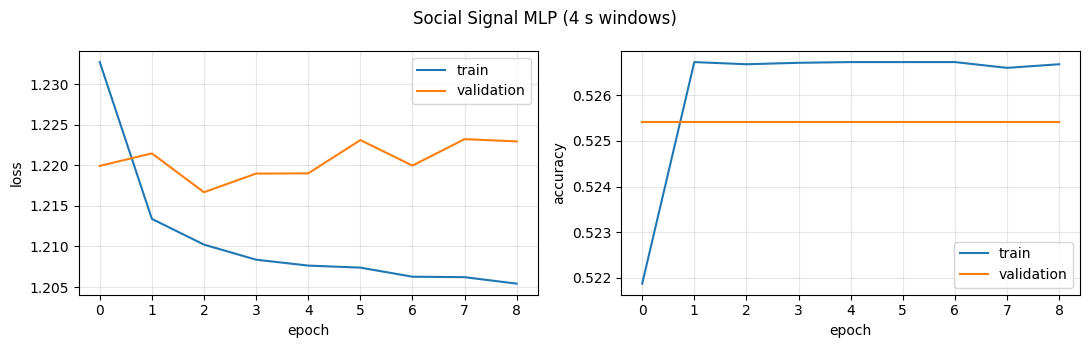


Best epoch: 1
Best validation accuracy: 0.5254
Total epochs: 9


In [ ]:

# B6 Step 5: Train the social signal MLP

social_mlp_history = train(
    social_mlp,
    X_train_social,
    y_train_social,
    X_val_social,
    y_val_social,
    epochs=40,
    batch_size=64,
    class_weight=None
)

# Plot training and validation curves
plot_history(
    social_mlp_history,
    "Social Signal MLP (4 s windows)"
)

# Record the best validation accuracy
social_mlp_best_epoch = int(
    np.argmax(social_mlp_history.history["val_accuracy"])
)

social_mlp_best_val_acc = social_mlp_history.history["val_accuracy"][
    social_mlp_best_epoch
]

print(f"\nBest epoch: {social_mlp_best_epoch + 1}")
print(f"Best validation accuracy: {social_mlp_best_val_acc:.4f}")
print(f"Total epochs: {len(social_mlp_history.history['loss'])}")


Social MLP - Validation  per-window accuracy: 0.525
Social MLP - Validation  per-recording accuracy (majority vote over windows): 0.528
                   precision    recall  f1-score   support

breathingNormally      0.000     0.000     0.000      2270
         coughing      0.000     0.000     0.000      2033
 hyperventilation      0.000     0.000     0.000      2149
            other      0.525     1.000     0.689      7143

         accuracy                          0.525     13595
        macro avg      0.131     0.250     0.172     13595
     weighted avg      0.276     0.525     0.362     13595



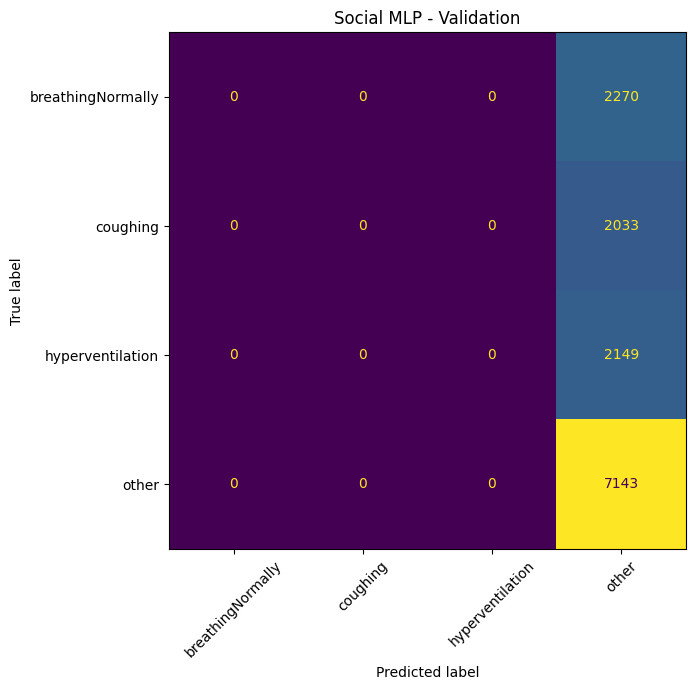


Predicted windows per class:
breathingNormally        0
coughing                 0
hyperventilation         0
other                13595
dtype: int64

Predicted class proportions:
breathingNormally    0.0
coughing             0.0
hyperventilation     0.0
other                1.0
dtype: float64


In [ ]:

# B6 Step 6: Evaluate the social MLP on validation data

social_mlp_predict = lambda X: social_mlp.predict(
    X,
    batch_size=512,
    verbose=0
)

social_mlp_val_acc = evaluate(
    social_mlp_predict,
    X_val_social,
    y_val_social,
    rec_id=rec_id_val_social,
    classes=SOCIAL_CLASSES,
    title="Social MLP - Validation"
)

# Inspect predicted class distribution
social_mlp_val_pred = social_mlp_predict(X_val_social).argmax(axis=1)

pred_counts = pd.Series(
    np.bincount(
        social_mlp_val_pred,
        minlength=len(SOCIAL_CLASSES)
    ),
    index=SOCIAL_CLASSES
)

print("\nPredicted windows per class:")
print(pred_counts)

print("\nPredicted class proportions:")
print((pred_counts / pred_counts.sum()).round(3))


In [ ]:

# B6 Step 7: Build the social signal CNN

# Temporarily use social training data for normalization
X_train_original = X_train

try:
    X_train = X_train_social
    social_cnn = build_cnn(
        window=WINDOW,
        n_classes=len(SOCIAL_CLASSES)
    )
finally:
    X_train = X_train_original

# Compile with the same training configuration as the MLP
social_cnn.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect the model
social_cnn.summary()

print("\nModel input shape:", social_cnn.input_shape)
print("Model output shape:", social_cnn.output_shape)
print("Total parameters:", social_cnn.count_params())

# Verify input and output dimensions
assert social_cnn.input_shape[1:] == (WINDOW, 3)
assert social_cnn.output_shape[-1] == len(SOCIAL_CLASSES)

print("\nSocial CNN is ready for training.")


Model: "har_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 46, 32)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_12 (MaxPooling1D) │ (None, 23, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_14 (Conv1D)              │ (None, 19, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_13 (MaxPooling1D) │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_6      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,083 (43.30 KB)

 Trainable params: 11,076 (43.27 KB)

 Non-trainable params: 7 (32.00 B)


Model input shape: (None, 50, 3)
Model output shape: (None, 4)
Total parameters: 11083

Social CNN is ready for training.


trained 40 epochs in 205 s; best epoch 38: val accuracy 0.654


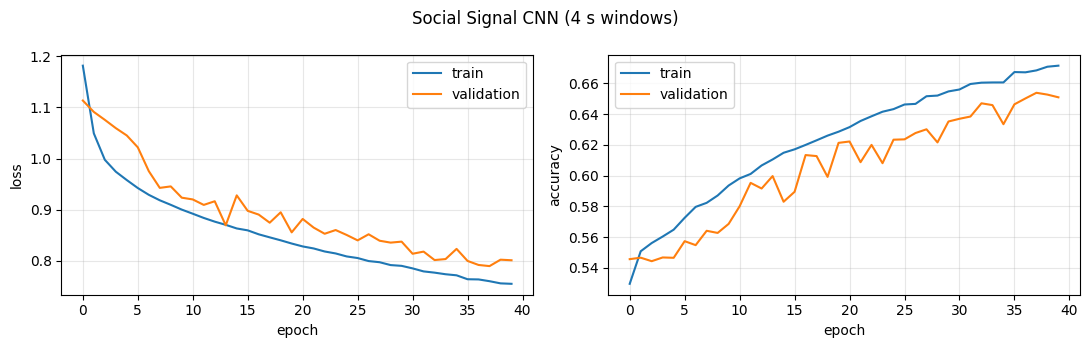


Best epoch: 38
Best validation accuracy: 0.6539
Total epochs: 40


In [ ]:

# B6 Step 8: Train the social signal CNN

social_cnn_history = train(
    social_cnn,
    X_train_social,
    y_train_social,
    X_val_social,
    y_val_social,
    epochs=40,
    batch_size=64,
    class_weight=None
)

# Plot training and validation curves
plot_history(
    social_cnn_history,
    "Social Signal CNN (4 s windows)"
)

# Record the best validation accuracy
social_cnn_best_epoch = int(
    np.argmax(social_cnn_history.history["val_accuracy"])
)

social_cnn_best_val_acc = social_cnn_history.history["val_accuracy"][
    social_cnn_best_epoch
]

print(f"\nBest epoch: {social_cnn_best_epoch + 1}")
print(f"Best validation accuracy: {social_cnn_best_val_acc:.4f}")
print(f"Total epochs: {len(social_cnn_history.history['loss'])}")


Social CNN - Validation  per-window accuracy: 0.654
Social CNN - Validation  per-recording accuracy (majority vote over windows): 0.689
                   precision    recall  f1-score   support

breathingNormally      0.661     0.319     0.431      2270
         coughing      0.670     0.517     0.584      2033
 hyperventilation      0.671     0.466     0.550      2149
            other      0.648     0.856     0.737      7143

         accuracy                          0.654     13595
        macro avg      0.662     0.540     0.576     13595
     weighted avg      0.657     0.654     0.634     13595



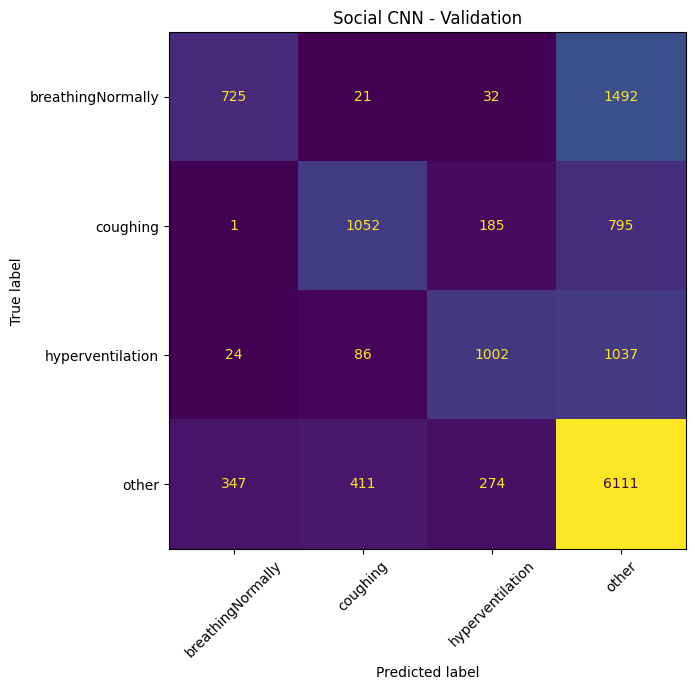


Predicted windows per class:
breathingNormally    1097
coughing             1570
hyperventilation     1493
other                9435
dtype: int64

Predicted class proportions:
breathingNormally    0.081
coughing             0.115
hyperventilation     0.110
other                0.694
dtype: float64

Actual validation class proportions:
breathingNormally    0.167
coughing             0.150
hyperventilation     0.158
other                0.525
Name: Validation, dtype: float64


In [ ]:

# B6 Step 9: Evaluate the social CNN on validation data

social_cnn_predict = lambda X: social_cnn.predict(
    X,
    batch_size=512,
    verbose=0
)

social_cnn_val_acc = evaluate(
    social_cnn_predict,
    X_val_social,
    y_val_social,
    rec_id=rec_id_val_social,
    classes=SOCIAL_CLASSES,
    title="Social CNN - Validation"
)

# Inspect predicted class distribution
social_cnn_val_pred = social_cnn_predict(X_val_social).argmax(axis=1)

cnn_pred_counts = pd.Series(
    np.bincount(
        social_cnn_val_pred,
        minlength=len(SOCIAL_CLASSES)
    ),
    index=SOCIAL_CLASSES
)

print("\nPredicted windows per class:")
print(cnn_pred_counts)

print("\nPredicted class proportions:")
print((cnn_pred_counts / cnn_pred_counts.sum()).round(3))

print("\nActual validation class proportions:")
print((window_counts_social["Validation"] / len(y_val_social)).round(3))


=== Social MLP: Test ===
Social MLP - Test  per-window accuracy: 0.527
Social MLP - Test  per-recording accuracy (majority vote over windows): 0.527
                   precision    recall  f1-score   support

breathingNormally      0.000     0.000     0.000      2199
         coughing      0.000     0.000     0.000      2051
 hyperventilation      0.000     0.000     0.000      2153
            other      0.527     1.000     0.690      7131

         accuracy                          0.527     13534
        macro avg      0.132     0.250     0.173     13534
     weighted avg      0.278     0.527     0.364     13534



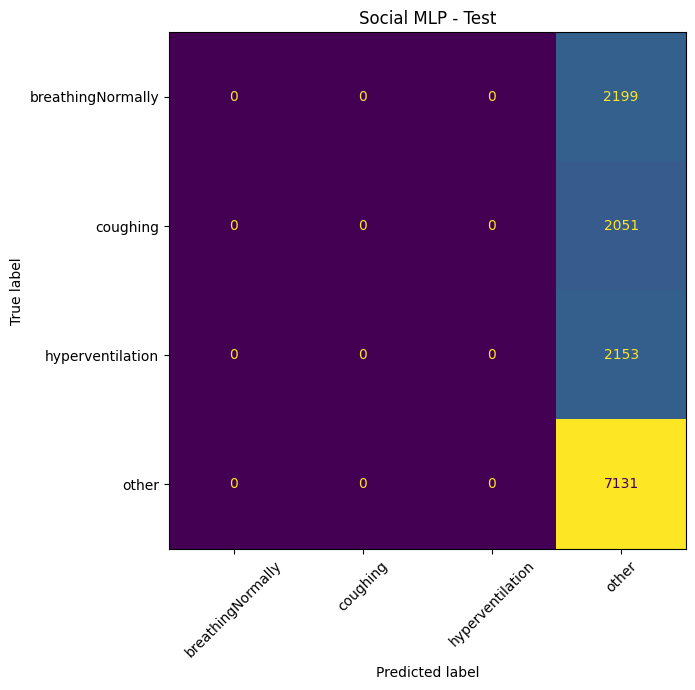


=== Social CNN: Test ===
Social CNN - Test  per-window accuracy: 0.667
Social CNN - Test  per-recording accuracy (majority vote over windows): 0.703
                   precision    recall  f1-score   support

breathingNormally      0.650     0.349     0.454      2199
         coughing      0.731     0.566     0.638      2051
 hyperventilation      0.678     0.409     0.510      2153
            other      0.656     0.871     0.749      7131

         accuracy                          0.667     13534
        macro avg      0.679     0.549     0.588     13534
     weighted avg      0.670     0.667     0.646     13534



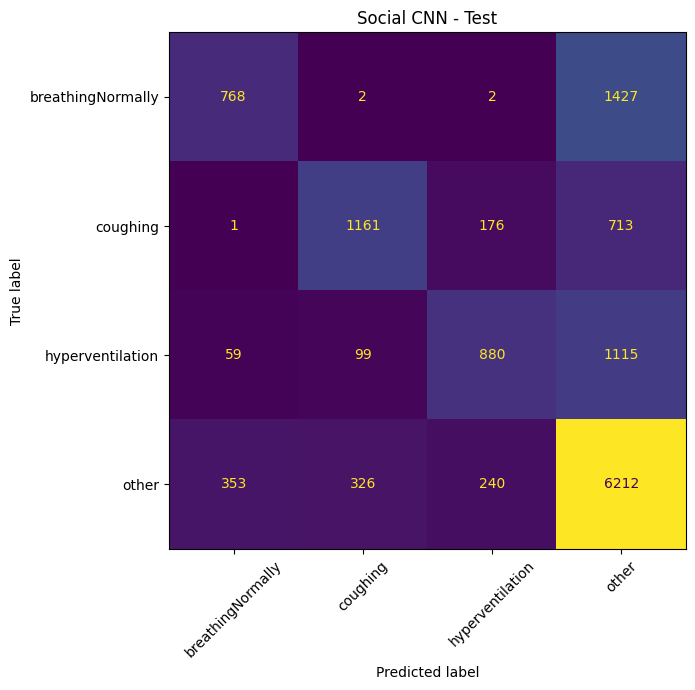


Validation and Test comparison:


,Model,Validation Accuracy,Test Accuracy
0,MLP,0.5254,0.5269
1,CNN,0.6539,0.6665


In [ ]:

# B6 Step 10: Final test evaluation

print("=== Social MLP: Test ===")

social_mlp_test_acc = evaluate(
    social_mlp_predict,
    X_test_social,
    y_test_social,
    rec_id=rec_id_test_social,
    classes=SOCIAL_CLASSES,
    title="Social MLP - Test"
)

print("\n=== Social CNN: Test ===")

social_cnn_test_acc = evaluate(
    social_cnn_predict,
    X_test_social,
    y_test_social,
    rec_id=rec_id_test_social,
    classes=SOCIAL_CLASSES,
    title="Social CNN - Test"
)

# Compare validation and test accuracy
social_test_comparison = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Validation Accuracy": [
        social_mlp_val_acc,
        social_cnn_val_acc
    ],
    "Test Accuracy": [
        social_mlp_test_acc,
        social_cnn_test_acc
    ]
})

print("\nValidation and Test comparison:")
display(social_test_comparison.round(4))


In [ ]:

# B6 Step 11: Convert social models to TFLite

# Convert the social MLP
social_mlp_tflite_path = convert_to_tflite(
    social_mlp,
    "social_mlp",
    window=WINDOW,
    step=STEP,
    classes=SOCIAL_CLASSES,
    out_dir=OUT_DIR
)

# Convert the social CNN
social_cnn_tflite_path = convert_to_tflite(
    social_cnn,
    "social_cnn",
    window=WINDOW,
    step=STEP,
    classes=SOCIAL_CLASSES,
    out_dir=OUT_DIR
)

# Inspect saved model files
for name, path in [
    ("MLP", social_mlp_tflite_path),
    ("CNN", social_cnn_tflite_path)
]:
    print(f"\n{name} model: {path}")
    print(f"Size: {path.stat().st_size / 1024:.2f} KiB")

# Check metadata for the CNN
social_cnn_meta = json.loads(
    (OUT_DIR / "social_cnn_meta.json").read_text()
)

print("\nCNN metadata:")
print(json.dumps(social_cnn_meta, indent=2))

assert social_cnn_meta["task"] == "social_signal"
assert social_cnn_meta["output"]["classes"] == SOCIAL_CLASSES

print("\nTFLite conversion completed.")


wrote social_mlp.tflite (50.1 kB) and social_mlp_meta.json
wrote social_cnn.tflite (49.3 kB) and social_cnn_meta.json

MLP model: lab3_models/social_mlp.tflite
Size: 50.09 KiB

CNN model: lab3_models/social_cnn.tflite
Size: 49.32 KiB

CNN metadata:
{
  "model_file": "social_cnn.tflite",
  "task": "social_signal",
  "sampling_frequency_hz": 12.5,
  "window_samples": 50,
  "step_samples": 25,
  "input": {
    "shape": [
      1,
      50,
      3
    ],
    "channels": [
      "accelX",
      "accelY",
      "accelZ"
    ],
    "units": "g (raw accelerometer values)",
    "dtype": "float32"
  },
  "output": {
    "shape": [
      1,
      4
    ],
    "classes": [
      "breathingNormally",
      "coughing",
      "hyperventilation",
      "other"
    ],
    "dtype": "float32"
  },
  "normalization": "inside the model \u2013 feed raw values"
}

TFLite conversion completed.


In [ ]:

# B6 Step 12: Verify social signal TFLite models

# Ensure the correct class names are used
assert CLASSES == SOCIAL_CLASSES

print("=== Social MLP TFLite Verification ===")

social_mlp_lite_probs = verify_tflite(
    social_mlp_tflite_path,
    social_mlp,
    X_test_social,
    y_test_social,
    name="social_mlp"
)

print("\n=== Social CNN TFLite Verification ===")

social_cnn_lite_probs = verify_tflite(
    social_cnn_tflite_path,
    social_cnn,
    X_test_social,
    y_test_social,
    name="social_cnn"
)

print("\nTFLite verification completed.")


=== Social MLP TFLite Verification ===
social_mlp.tflite: TFLite accuracy 0.527 · argmax agrees with Keras on 100.0% of windows · max |Δprob| = 1.79e-07 · 0.01 ms per window on this CPU

=== Social CNN TFLite Verification ===
social_cnn.tflite: TFLite accuracy 0.667 · argmax agrees with Keras on 100.0% of windows · max |Δprob| = 2.18e-06 · 0.01 ms per window on this CPU

TFLite verification completed.


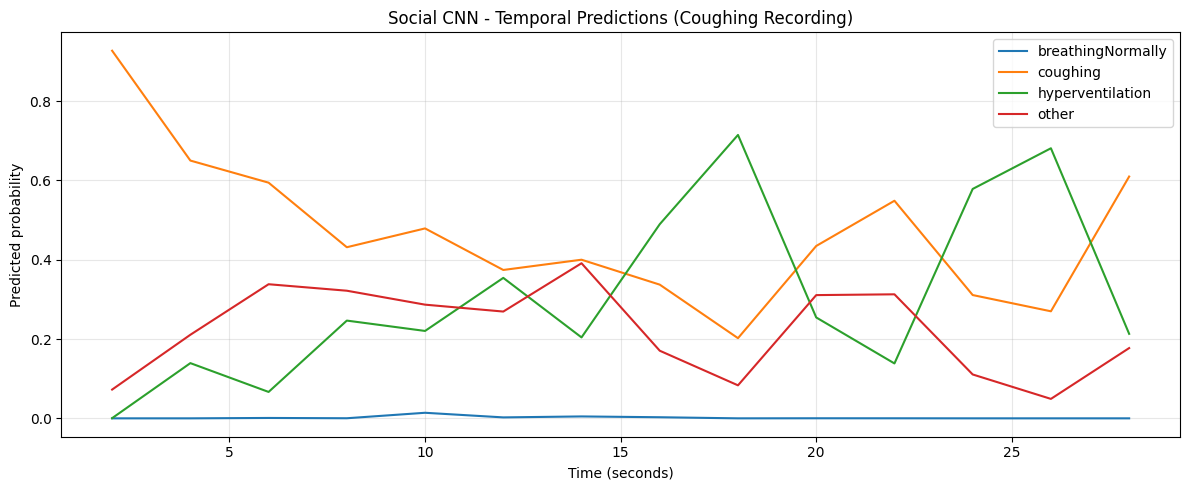

Recording ID: 1069
True recording label: coughing
Number of windows: 14

Predicted windows per class:
breathingNormally     0
coughing             10
hyperventilation      4
other                 0
dtype: int64

Coughing detection rate: 0.714


In [ ]:

# B6 Step 13: Inspect temporal predictions in one coughing recording

cough_id = SOCIAL_CLASSES.index("coughing")

# Select the first available coughing recording
cough_rec_ids = rec_val_social.loc[
    rec_val_social["y"] == cough_id
].index

selected_rec = next(
    i for i in cough_rec_ids
    if np.any(rec_id_val_social == i)
)

# Select windows belonging to this recording
mask = rec_id_val_social == selected_rec
X_sequence = X_val_social[mask]

# Predict probabilities for consecutive windows
sequence_probs = social_cnn.predict(
    X_sequence,
    batch_size=512,
    verbose=0
)

sequence_pred = sequence_probs.argmax(axis=1)

# Calculate the time at the centre of each window
time_seconds = (
    np.arange(len(X_sequence)) * STEP + WINDOW / 2
) / SAMPLING_FREQ

# Plot prediction probabilities over time
plt.figure(figsize=(12, 5))

for i, label in enumerate(SOCIAL_CLASSES):
    plt.plot(
        time_seconds,
        sequence_probs[:, i],
        label=label
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Predicted probability")
plt.title("Social CNN - Temporal Predictions (Coughing Recording)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Summarise predictions for this recording
prediction_counts = pd.Series(
    np.bincount(
        sequence_pred,
        minlength=len(SOCIAL_CLASSES)
    ),
    index=SOCIAL_CLASSES
)

print("Recording ID:", selected_rec)
print("True recording label: coughing")
print("Number of windows:", len(X_sequence))
print("\nPredicted windows per class:")
print(prediction_counts)

print(
    "\nCoughing detection rate:",
    f"{np.mean(sequence_pred == cough_id):.3f}"
)


## B7 · Smaller and faster: post-training quantisation

The phone has limited memory and battery, so it is useful to see whether the model can be made smaller without losing much accuracy.

TFLite can store model weights as 8-bit integers instead of 32-bit floats. This is called **post-training quantisation**. It can reduce the model size by roughly four times and may also make inference faster, with usually only a small drop in accuracy.

Convert your best model again using `optimizations=[tf.lite.Optimize.DEFAULT]`. The `convert_to_tflite()` function already passes this option through. Compare the quantised and float versions in terms of:

- model size
- accuracy
- inference time per window

For **full integer quantisation**, the converter also needs a `representative_dataset` generator that provides a few hundred training windows. Look up how this works in the TFLite documentation and try it.

### Resources

* **Post-training quantisation overview** – the main LiteRT guide. Has the comparison table of the three methods (dynamic range: ~4× smaller, CPU speed-up; full integer: ~4× smaller, needed for microcontrollers and Edge TPUs; float16: ~2× smaller, for GPUs), the decision flowchart, and the section on the `representative_dataset` generator (100–500 samples is enough).
  https://developers.google.com/edge/litert/conversion/tensorflow/quantization/post_training_quantization
* **Dynamic range quantisation tutorial** – the `optimizations=[tf.lite.Optimize.DEFAULT]` route you are asked to try first; compares file size and accuracy of the float and quantised models.
  https://developers.google.com/edge/litert/conversion/tensorflow/quantization/post_training_quant
* **Full integer quantisation tutorial** – shows the `representative_dataset` generator, setting `converter.inference_input_type` / `inference_output_type` (the tutorial uses `uint8`; `int8` also works), and evaluating the quantised model with the interpreter. Note that with integer inputs the app would have to quantise the accelerometer values itself before calling the model – read the input tensor's `quantization` parameters from `interp.get_input_details()`.
  https://developers.google.com/edge/litert/conversion/tensorflow/quantization/post_training_integer_quant
* **Float16 quantisation** – mainly for GPU delegates; worth knowing it exists.
  https://developers.google.com/edge/litert/conversion/tensorflow/quantization/post_training_float16_quant
* **Quantisation-aware training** – if post-training quantisation costs too much accuracy, the model can be trained with simulated quantisation (TensorFlow Model Optimization Toolkit). Not needed for this lab, but it is the next step in practice.
  https://www.tensorflow.org/model_optimization/guide/quantization/training


In [ ]:
# q_path = convert_to_tflite(cnn, "har_cnn_int8", optimizations=[tf.lite.Optimize.DEFAULT])
# verify_tflite(q_path, cnn, X_test, y_test)

In [ ]:

# B7 Step 1: Check existing HAR model and test data

required_vars = [
    "cnn",
    "best_cnn",
    "X_train",
    "X_test",
    "y_test",
    "WINDOW",
    "STEP",
    "TASK",
    "CLASSES",
    "convert_to_tflite",
    "verify_tflite"
]

print("=== Required variables ===")

for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

print("\n=== Current task ===")

if "TASK" in globals():
    print("TASK:", TASK)

if "CLASSES" in globals():
    print("Number of classes:", len(CLASSES))
    print("Classes:", CLASSES)

print("\n=== HAR model ===")

if "best_cnn" in globals():
    print("Input shape:", best_cnn.input_shape)
    print("Output shape:", best_cnn.output_shape)
    print("Parameters:", best_cnn.count_params())

print("\n=== HAR test data ===")

if "X_test" in globals() and "y_test" in globals():
    print("X_test shape:", X_test.shape)
    print("y_test shape:", y_test.shape)
    print("Unique labels:", np.unique(y_test))

print("\n=== Existing TFLite model ===")

if "OUT_DIR" in globals():
    har_path = OUT_DIR / "har_cnn.tflite"
    print("Model exists:", har_path.exists())

    if har_path.exists():
        print("Model size (KiB):", round(
            har_path.stat().st_size / 1024, 2
        ))


=== Required variables ===
cnn: Available
best_cnn: Available
X_train: Available
X_test: Available
y_test: Available
WINDOW: Available
STEP: Available
TASK: Available
CLASSES: Available
convert_to_tflite: Available
verify_tflite: Available

=== Current task ===
TASK: social_signal
Number of classes: 4
Classes: ['breathingNormally', 'coughing', 'hyperventilation', 'other']

=== HAR model ===
Input shape: (None, 50, 3)
Output shape: (None, 11)
Parameters: 11538

=== HAR test data ===
X_test shape: (4034, 50, 3)
y_test shape: (4034,)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10]

=== Existing TFLite model ===
Model exists: True
Model size (KiB): 51.02


In [ ]:

# B7 Step 2: Dynamic range quantisation

# Restore HAR task settings
TASK = "daily_activity"
CLASSES = daily_data["classes"].copy()

# Check the selected HAR model and labels
assert best_cnn.output_shape[-1] == len(CLASSES)
assert X_test.shape[1:] == (WINDOW, 3)

# Convert the trained CNN with default optimisation
q_path = convert_to_tflite(
    best_cnn,
    "har_cnn_dynamic",
    classes=CLASSES,
    optimizations=[tf.lite.Optimize.DEFAULT]
)

# Compare model file sizes
float_path = OUT_DIR / "har_cnn.tflite"

float_size = float_path.stat().st_size / 1024
quant_size = q_path.stat().st_size / 1024

print("\n=== Model Size Comparison ===")
print(f"Float32 model: {float_size:.2f} KiB")
print(f"Quantised model: {quant_size:.2f} KiB")
print(f"Size reduction: {(1 - quant_size / float_size) * 100:.2f}%")
print(f"Compression ratio: {float_size / quant_size:.2f}x")


wrote har_cnn_dynamic.tflite (21.8 kB) and har_cnn_dynamic_meta.json

=== Model Size Comparison ===
Float32 model: 51.02 KiB
Quantised model: 21.83 KiB
Size reduction: 57.22%
Compression ratio: 2.34x


In [ ]:

# B7 Step 3: Verify float and quantised CNN models

print("=== Float32 CNN ===")
float_probs = verify_tflite(
    float_path,
    best_cnn,
    X_test,
    y_test,
    name="har_cnn_float_b7"
)

print("\n=== Quantised CNN ===")
quant_probs = verify_tflite(
    q_path,
    best_cnn,
    X_test,
    y_test,
    name="har_cnn_dynamic_b7"
)

print("\n=== Accuracy Comparison ===")
float_acc = accuracy_score(y_test, float_probs.argmax(axis=1))
quant_acc = accuracy_score(y_test, quant_probs.argmax(axis=1))

print(f"Float32 accuracy: {float_acc:.4%}")
print(f"Quantised accuracy: {quant_acc:.4%}")
print(f"Accuracy difference: {(quant_acc - float_acc) * 100:+.2f} percentage points")

print("\n=== Prediction Agreement ===")
agreement = np.mean(
    float_probs.argmax(axis=1) == quant_probs.argmax(axis=1)
)

print(f"Float vs Quantised agreement: {agreement:.2%}")


=== Float32 CNN ===
har_cnn.tflite: TFLite accuracy 0.908 · argmax agrees with Keras on 100.0% of windows · max |Δprob| = 6.85e-07 · 0.01 ms per window on this CPU

=== Quantised CNN ===
har_cnn_dynamic.tflite: TFLite accuracy 0.907 · argmax agrees with Keras on 99.9% of windows · max |Δprob| = 2.26e-02 · 0.01 ms per window on this CPU

=== Accuracy Comparison ===
Float32 accuracy: 90.7784%
Quantised accuracy: 90.7288%
Accuracy difference: -0.05 percentage points

=== Prediction Agreement ===
Float vs Quantised agreement: 99.93%


In [ ]:

# B7 Step 4A: Prepare representative training windows

rng = np.random.default_rng(42)

n_samples = 200

indices = rng.choice(
    len(X_train),
    size=n_samples,
    replace=False
)

X_representative = X_train[indices].astype(np.float32)

print("=== Representative Dataset ===")
print("Source: HAR training data")
print("Training windows:", len(X_train))
print("Selected windows:", len(X_representative))
print("Shape:", X_representative.shape)
print("Dtype:", X_representative.dtype)
print("Minimum value:", X_representative.min())
print("Maximum value:", X_representative.max())
print("All values finite:", np.isfinite(X_representative).all())


=== Representative Dataset ===
Source: HAR training data
Training windows: 18729
Selected windows: 200
Shape: (200, 50, 3)
Dtype: float32
Minimum value: -2.0
Maximum value: 1.999939
All values finite: True


In [ ]:

# B7 Step 4B: Representative dataset generator

def representative_dataset():
    for window in X_representative:
        yield [window[np.newaxis, ...]]

# Check the first generated sample
sample = next(representative_dataset())

print("=== Representative Dataset Generator ===")
print("Sample type:", type(sample))
print("Number of inputs:", len(sample))
print("Input shape:", sample[0].shape)
print("Input dtype:", sample[0].dtype)
print("Generated samples:", sum(1 for _ in representative_dataset()))


=== Representative Dataset Generator ===
Sample type: <class 'list'>
Number of inputs: 1
Input shape: (1, 50, 3)
Input dtype: float32
Generated samples: 200


In [ ]:

# B7 Step 4C: Full integer quantisation

converter = tf.lite.TFLiteConverter.from_keras_model(best_cnn)

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Convert and save the model
int8_model = converter.convert()

int8_path = OUT_DIR / "har_cnn_full_int8.tflite"
int8_path.write_bytes(int8_model)

# Inspect the converted model
interpreter = tf.lite.Interpreter(model_path=str(int8_path))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

print("\n=== Full Integer Quantisation ===")
print("Model:", int8_path.name)
print("Model size (KiB):", round(len(int8_model) / 1024, 2))

print("\n=== Input Tensor ===")
print("Shape:", input_details["shape"])
print("Dtype:", input_details["dtype"])
print("Quantisation:", input_details["quantization"])

print("\n=== Output Tensor ===")
print("Shape:", output_details["shape"])
print("Dtype:", output_details["dtype"])
print("Quantisation:", output_details["quantization"])

print("\n=== Size Comparison ===")
print(f"Float32: {float_size:.2f} KiB")
print(f"Dynamic range: {quant_size:.2f} KiB")
print(f"Full integer: {len(int8_model) / 1024:.2f} KiB")


Saved artifact at '/tmp/tmpikdmtr9y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 50, 3), dtype=tf.float32, name='window')
Output Type:
  TensorSpec(shape=(None, 11), dtype=tf.float32, name=None)
Captures:
  138393886492624: TensorSpec(shape=(1, 1, 3), dtype=tf.float32, name=None)
  138393886501264: TensorSpec(shape=(1, 1, 3), dtype=tf.float32, name=None)
  138393886492432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138393886504336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138393886506640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138393886505872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138393886504528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138394337350800: TensorSpec(shape=(), dtype=tf.resource, name=None)

=== Full Integer Quantisation ===
Model: har_cnn_full_int8.tflite
Model size (KiB): 20.87

=== Input Tensor ===
Shape: [ 1 50  3]
Dtype: <class 'numpy.int

In [ ]:

# B7 Step 4D: Evaluate full integer CNN

interpreter = tf.lite.Interpreter(model_path=str(int8_path))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

input_scale, input_zero = input_details["quantization"]
output_scale, output_zero = output_details["quantization"]

int8_probs = []

for window in X_test:
    # Quantise the input
    input_float = window[np.newaxis, ...].astype(np.float32)
    input_int8 = np.round(
        input_float / input_scale + input_zero
    )
    input_int8 = np.clip(input_int8, -128, 127).astype(np.int8)

    # Run integer inference
    interpreter.set_tensor(input_details["index"], input_int8)
    interpreter.invoke()

    # Dequantise the output
    output_int8 = interpreter.get_tensor(output_details["index"])
    output_float = (
        output_int8.astype(np.float32) - output_zero
    ) * output_scale

    int8_probs.append(output_float[0])

int8_probs = np.array(int8_probs)

# Compare predictions
int8_predictions = int8_probs.argmax(axis=1)
float_predictions = float_probs.argmax(axis=1)

int8_acc = accuracy_score(y_test, int8_predictions)
int8_agreement = np.mean(int8_predictions == float_predictions)

print("=== Full Integer Model Evaluation ===")
print(f"Test accuracy: {int8_acc:.4%}")
print(f"Float32 accuracy: {float_acc:.4%}")
print(f"Accuracy difference: {(int8_acc - float_acc) * 100:+.2f} pp")
print(f"Prediction agreement: {int8_agreement:.2%}")
print("Evaluated windows:", len(int8_predictions))


=== Full Integer Model Evaluation ===
Test accuracy: 90.4561%
Float32 accuracy: 90.7784%
Accuracy difference: -0.32 pp
Prediction agreement: 98.34%
Evaluated windows: 4034


In [ ]:

# B7 Step 4E: Compare CPU inference latency

import time

def benchmark_tflite(path, X, repeats=5):
    interpreter = tf.lite.Interpreter(model_path=str(path))
    interpreter.allocate_tensors()

    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]

    scale, zero = inp["quantization"]
    times = []

    for repeat in range(repeats):
        start = time.perf_counter()

        for window in X:
            sample = window[np.newaxis, ...].astype(np.float32)

            if inp["dtype"] == np.int8:
                sample = np.round(sample / scale + zero)
                sample = np.clip(sample, -128, 127).astype(np.int8)

            interpreter.set_tensor(inp["index"], sample)
            interpreter.invoke()
            _ = interpreter.get_tensor(out["index"])

        elapsed = time.perf_counter() - start
        times.append(elapsed / len(X) * 1000)

    return np.median(times), np.std(times)


# Benchmark the same test windows
benchmark_results = {}

for name, path in [
    ("Float32", float_path),
    ("Dynamic Range", q_path),
    ("Full Integer", int8_path)
]:
    median_ms, std_ms = benchmark_tflite(path, X_test)

    benchmark_results[name] = median_ms

    print(
        f"{name}: {median_ms:.4f} ms/window "
        f"(std: {std_ms:.4f} ms)"
    )

print("\n=== Relative Latency ===")

float_latency = benchmark_results["Float32"]

for name in ["Dynamic Range", "Full Integer"]:
    latency = benchmark_results[name]
    print(f"{name} speed ratio: {float_latency / latency:.2f}x")


Float32: 0.0112 ms/window (std: 0.0003 ms)
Dynamic Range: 0.0121 ms/window (std: 0.0003 ms)
Full Integer: 0.0231 ms/window (std: 0.0015 ms)

=== Relative Latency ===
Dynamic Range speed ratio: 0.93x
Full Integer speed ratio: 0.49x


## B8 · Data augmentation

In Lab 2 you saw that people do not always wear the sensor at exactly the same angle. A model might also see noisier data when used with a different sensor. **Augmentation** adds these kinds of changes to the training data, for example:

- small random rotations of the 3-D acceleration signal
- Gaussian noise
- small changes to the signal amplitude
- small shifts along the time axis

Implement one or two of these augmentations as functions that you apply to `X_train`. Train your best model using the augmented data, then test it on:

1. the normal test set
2. a test set where you have deliberately rotated the data by 15°

Does augmentation reduce accuracy on the normal test set? Does it improve performance when the sensor is rotated?

In [ ]:

# B8 Step 1: Check existing HAR data and model

required_vars = [
    "np", "tf", "best_cnn",
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test",
    "WINDOW", "STEP", "CLASSES",
    "TASK", "build_cnn", "train"
]

print("=== Required Variables ===")
for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

if all(name in globals() for name in required_vars):
    print("\n=== HAR Configuration ===")
    print("TASK:", TASK)
    print("WINDOW:", WINDOW)
    print("STEP:", STEP)
    print("Number of classes:", len(CLASSES))

    print("\n=== Dataset Shapes ===")
    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)
    print("X_val:", X_val.shape)
    print("X_test:", X_test.shape)

    print("\n=== CNN Model ===")
    print("Input shape:", best_cnn.input_shape)
    print("Output shape:", best_cnn.output_shape)
    print("Parameters:", best_cnn.count_params())

    print("\n=== Consistency Checks ===")
    print("HAR task:", TASK == "daily_activity")
    print("Input shape correct:", X_train.shape[1:] == (50, 3))
    print("Class count correct:", len(CLASSES) == 11)
    print("Model output correct:", best_cnn.output_shape[-1] == 11)
    print("Training labels:", np.unique(y_train))


=== Required Variables ===
np: Available
tf: Available
best_cnn: Available
X_train: Available
y_train: Available
X_val: Available
y_val: Available
X_test: Available
y_test: Available
WINDOW: Available
STEP: Available
CLASSES: Available
TASK: Available
build_cnn: Available
train: Available

=== HAR Configuration ===
TASK: daily_activity
WINDOW: 50
STEP: 25
Number of classes: 11

=== Dataset Shapes ===
X_train: (18729, 50, 3)
y_train: (18729,)
X_val: (3997, 50, 3)
X_test: (4034, 50, 3)

=== CNN Model ===
Input shape: (None, 50, 3)
Output shape: (None, 11)
Parameters: 11538

=== Consistency Checks ===
HAR task: True
Input shape correct: True
Class count correct: True
Model output correct: True
Training labels: [ 0  1  2  3  4  5  6  7  8  9 10]


In [ ]:

from scipy.spatial.transform import Rotation

def rotate_windows(X: np.ndarray, max_deg: float = 15.0,
                   rng=np.random.default_rng(SEED)) -> np.ndarray:
    '''Rotate every window by a random angle up to max_deg about a random axis.'''

    X_rot = np.empty_like(X)

    for i in range(len(X)):
        # Generate a random rotation axis
        axis = rng.normal(size=3)
        axis = axis / np.linalg.norm(axis)

        # Generate a random rotation angle
        angle = np.deg2rad(rng.uniform(-max_deg, max_deg))

        # Build a 3x3 rotation matrix
        rotvec = axis * angle
        R = Rotation.from_rotvec(rotvec).as_matrix()

        # Apply the same rotation to all samples in the window
        X_rot[i] = X[i] @ R.T

    return X_rot


In [ ]:

# B8 Step 2: Verify random rotation

X_sample = X_train[:3].copy()
X_rotated = rotate_windows(X_sample, max_deg=15.0)

print("=== Rotation Check ===")
print("Original shape:", X_sample.shape)
print("Rotated shape:", X_rotated.shape)

print("\n=== First Sample ===")
print("Before:", X_sample[0, 0])
print("After: ", X_rotated[0, 0])

original_magnitude = np.linalg.norm(X_sample, axis=2)
rotated_magnitude = np.linalg.norm(X_rotated, axis=2)

print("\n=== Verification ===")
print("Values changed:", not np.allclose(X_sample, X_rotated))
print("Magnitude preserved:", np.allclose(
    original_magnitude, rotated_magnitude, atol=1e-5
))
print("Original data unchanged:", np.array_equal(
    X_sample, X_train[:3]
))


=== Rotation Check ===
Original shape: (3, 50, 3)
Rotated shape: (3, 50, 3)

=== First Sample ===
Before: [ 0.08227539 -1.0125122  -0.03570557]
After:  [-0.1649133  -1.0029005   0.01480613]

=== Verification ===
Values changed: True
Magnitude preserved: True
Original data unchanged: True


In [ ]:

# B8 Step 3: Prepare augmented training data

aug_rng = np.random.default_rng(SEED)

# Copy original training data and labels
X_train_aug = X_train.copy()
y_train_aug = y_train.copy()

# Select 50% of training windows
n_aug = len(X_train) // 2
aug_indices = aug_rng.choice(
    len(X_train),
    size=n_aug,
    replace=False
)

# Apply random rotations to selected windows
X_train_aug[aug_indices] = rotate_windows(
    X_train[aug_indices],
    max_deg=15.0,
    rng=aug_rng
)

# Check augmented training data
print("=== Augmented Training Data ===")
print("Original shape:", X_train.shape)
print("Augmented shape:", X_train_aug.shape)
print("Rotated windows:", n_aug)
print("Augmentation ratio:", f"{n_aug / len(X_train):.1%}")

print("\n=== Verification ===")
print("Labels unchanged:", np.array_equal(y_train, y_train_aug))
print("Original training data unchanged:",
      not np.shares_memory(X_train, X_train_aug))
print("All values finite:", np.isfinite(X_train_aug).all())
print("Shape unchanged:", X_train_aug.shape == X_train.shape)


=== Augmented Training Data ===
Original shape: (18729, 50, 3)
Augmented shape: (18729, 50, 3)
Rotated windows: 9364
Augmentation ratio: 50.0%

=== Verification ===
Labels unchanged: True
Original training data unchanged: True
All values finite: True
Shape unchanged: True


Epoch 1/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6337 - loss: 1.0962 - val_accuracy: 0.7411 - val_loss: 0.7715
Epoch 2/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7716 - loss: 0.6539 - val_accuracy: 0.8186 - val_loss: 0.6333
Epoch 3/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8242 - loss: 0.5297 - val_accuracy: 0.8531 - val_loss: 0.5667
Epoch 4/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8549 - loss: 0.4587 - val_accuracy: 0.8609 - val_loss: 0.5366
Epoch 5/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8708 - loss: 0.4172 - val_accuracy: 0.8684 - val_loss: 0.5215
Epoch 6/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8816 - loss: 0.3862 - val_accuracy: 0.8754 - val_loss: 0.5157
Epoch 7/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8894 - loss: 0.3671 - val_accuracy: 0.8772 - val_loss: 0.5049
Epoch 8/40
293/293 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8952 - loss: 0.3483 - val_accuracy: 0.

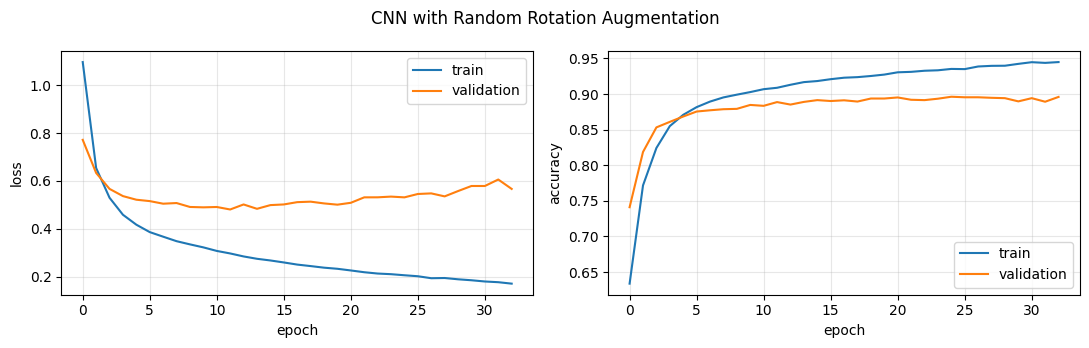


=== Augmented CNN Training Summary ===
Parameters: 11538
Best epoch: 25
Best validation accuracy: 0.8962


In [ ]:

# B8 Step 4: Train CNN with augmented data

# Set the random seed
keras.utils.set_random_seed(SEED)

# Build a new CNN with the same architecture
cnn_aug = build_cnn()

# Compile the augmented CNN
cnn_aug.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train on augmented data
cnn_aug_history = train(
    cnn_aug,
    X_train_aug,
    y_train_aug,
    X_val,
    y_val,
    epochs=40,
    batch_size=64,
    verbose=1
)

# Plot training and validation performance
plot_history(cnn_aug_history, "CNN with Random Rotation Augmentation")

# Record the best validation accuracy
cnn_aug_best_epoch = int(
    np.argmax(cnn_aug_history.history["val_accuracy"])
)

cnn_aug_best_val_acc = cnn_aug_history.history["val_accuracy"][
    cnn_aug_best_epoch
]

print("\n=== Augmented CNN Training Summary ===")
print("Parameters:", cnn_aug.count_params())
print("Best epoch:", cnn_aug_best_epoch + 1)
print("Best validation accuracy:", f"{cnn_aug_best_val_acc:.4f}")


In [ ]:

# B8 Step 5: Create a 15-degree rotated test set

# Build a fixed 15-degree rotation around the Y axis
R_test = Rotation.from_euler(
    "y", 15, degrees=True
).as_matrix()

# Apply the rotation to every test window
X_test_rot15 = X_test @ R_test.T

# Check rotated test data
print("=== Rotated Test Set ===")
print("Original shape:", X_test.shape)
print("Rotated shape:", X_test_rot15.shape)
print("Rotation angle: 15 degrees")
print("Rotation axis: Y")

print("\n=== First Test Sample ===")
print("Before:", X_test[0, 0])
print("After: ", X_test_rot15[0, 0])

print("\n=== Verification ===")
print("Values changed:", not np.allclose(X_test, X_test_rot15))
print("Magnitude preserved:", np.allclose(
    np.linalg.norm(X_test, axis=2),
    np.linalg.norm(X_test_rot15, axis=2),
    atol=1e-5
))
print("Labels unchanged:", len(y_test) == len(X_test_rot15))
print("All values finite:", np.isfinite(X_test_rot15).all())


=== Rotated Test Set ===
Original shape: (4034, 50, 3)
Rotated shape: (4034, 50, 3)
Rotation angle: 15 degrees
Rotation axis: Y

=== First Test Sample ===
Before: [-0.93237305 -0.2053833  -0.42803955]
After:  [-1.01138799 -0.2053833  -0.17213856]

=== Verification ===
Values changed: True
Magnitude preserved: True
Labels unchanged: True
All values finite: True


In [ ]:

# B8 Step 6: Compare baseline and augmented CNNs

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Predict labels on normal test data
baseline_normal_pred = best_cnn.predict(
    X_test, batch_size=512, verbose=0
).argmax(axis=1)

aug_normal_pred = cnn_aug.predict(
    X_test, batch_size=512, verbose=0
).argmax(axis=1)

# Predict labels on rotated test data
baseline_rot_pred = best_cnn.predict(
    X_test_rot15, batch_size=512, verbose=0
).argmax(axis=1)

aug_rot_pred = cnn_aug.predict(
    X_test_rot15, batch_size=512, verbose=0
).argmax(axis=1)

# Calculate accuracy and macro F1
results_b8 = pd.DataFrame({
    "Model": ["Baseline CNN", "Augmented CNN"],
    "Normal Accuracy": [
        accuracy_score(y_test, baseline_normal_pred),
        accuracy_score(y_test, aug_normal_pred)
    ],
    "Rotated Accuracy": [
        accuracy_score(y_test, baseline_rot_pred),
        accuracy_score(y_test, aug_rot_pred)
    ],
    "Normal Macro F1": [
        f1_score(y_test, baseline_normal_pred, average="macro"),
        f1_score(y_test, aug_normal_pred, average="macro")
    ],
    "Rotated Macro F1": [
        f1_score(y_test, baseline_rot_pred, average="macro"),
        f1_score(y_test, aug_rot_pred, average="macro")
    ]
})

# Measure the accuracy change caused by rotation
results_b8["Rotation Drop (pp)"] = (
    results_b8["Normal Accuracy"] -
    results_b8["Rotated Accuracy"]
) * 100

print("=== B8 Model Comparison ===")
print(results_b8.round(4).to_string(index=False))

print("\n=== Augmentation Effect ===")
print(
    "Normal accuracy difference (pp):",
    round(100 * (
        results_b8.loc[1, "Normal Accuracy"] -
        results_b8.loc[0, "Normal Accuracy"]
    ), 2)
)

print(
    "Rotated accuracy difference (pp):",
    round(100 * (
        results_b8.loc[1, "Rotated Accuracy"] -
        results_b8.loc[0, "Rotated Accuracy"]
    ), 2)
)


=== B8 Model Comparison ===
        Model  Normal Accuracy  Rotated Accuracy  Normal Macro F1  Rotated Macro F1  Rotation Drop (pp)
 Baseline CNN           0.9078            0.9053           0.9098            0.9056              0.2479
Augmented CNN           0.9098            0.9033           0.9105            0.9017              0.6445

=== Augmentation Effect ===
Normal accuracy difference (pp): 0.2
Rotated accuracy difference (pp): -0.2


In [ ]:

# B8 Step 7: Analyse prediction stability under rotation

# Compare predictions before and after rotation
baseline_agreement = np.mean(
    baseline_normal_pred == baseline_rot_pred
)

aug_agreement = np.mean(
    aug_normal_pred == aug_rot_pred
)

# Count changed predictions
baseline_changed = np.sum(
    baseline_normal_pred != baseline_rot_pred
)

aug_changed = np.sum(
    aug_normal_pred != aug_rot_pred
)

print("=== Prediction Stability ===")
print(f"Baseline agreement: {baseline_agreement:.2%}")
print(f"Augmented agreement: {aug_agreement:.2%}")

print("\n=== Changed Predictions ===")
print(f"Baseline CNN: {baseline_changed} / {len(y_test)}")
print(f"Augmented CNN: {aug_changed} / {len(y_test)}")

# Compare how many predictions are correct in both conditions
baseline_both_correct = np.mean(
    (baseline_normal_pred == y_test) &
    (baseline_rot_pred == y_test)
)

aug_both_correct = np.mean(
    (aug_normal_pred == y_test) &
    (aug_rot_pred == y_test)
)

print("\n=== Correct in Both Conditions ===")
print(f"Baseline CNN: {baseline_both_correct:.2%}")
print(f"Augmented CNN: {aug_both_correct:.2%}")


=== Prediction Stability ===
Baseline agreement: 97.89%
Augmented agreement: 97.62%

=== Changed Predictions ===
Baseline CNN: 85 / 4034
Augmented CNN: 96 / 4034

=== Correct in Both Conditions ===
Baseline CNN: 89.69%
Augmented CNN: 89.64%


## B9 · Subject-wise 10-fold cross-validation

A single train/test split gives you one accuracy, but the result can depend on which subjects happen to end up in the test set. For Coursework 3, use **10-fold cross-validation** instead.

The subjects for each activity are split into 10 groups. For each fold, train on 9 groups and test on the remaining group. Repeat this 10 times and average the test accuracies. The fold assignments are provided on Learn so that everyone's results are based on the same splits.

Implement the following:

1. **Load the fold assignments.** `load_folds()` reads a CSV with one row per recording (`activity, file, fold`) if it is next to the notebook. If the file is not there, it creates its own folds by shuffling each activity's recordings and splitting them into 10 groups. Adapt the loader if the file on Learn has a different format. **Use the Learn fold assignments for any results you report.**

2. **Run all 10 folds.** For each fold:
   - Create the training and test windows from the appropriate recordings.
   - Build and train a new model. Use your best model from B1–B5, although the MLP is fine for your first run.
   - Evaluate the model on the test windows.
   - Save the test accuracy **and** confusion matrix for that fold.

3. **Report the results.** Give the mean and standard deviation of the 10 test accuracies, along with the summed confusion matrix. Compare the mean accuracy with the hold-out result from Part A. How much do the results vary between folds? If two models differ by only one percentage point on a single split, what does the variation between folds tell you about how meaningful that difference is?

**A few things to keep in mind:**

- There is no validation set within each fold, so do not use early stopping based on the test fold. Use a fixed number of epochs, based on the best number you found in Part A.

### Resources

* **scikit-learn user guide, "Cross-validation iterators for grouped data"** – `GroupKFold` and `StratifiedGroupKFold` are the library versions of what `make_folds()` does (subjects as groups). You cannot use them directly here because our subject ids are only unique within an activity, but the explanation of *why* grouped splitting exists is exactly our situation, and you can use them for the per-activity split if you prefer.
  https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data
* **"Visualizing cross-validation behavior in scikit-learn"** – draws which samples land in train and test for each fold of `KFold`, `GroupKFold`, `StratifiedGroupKFold` and others. The clearest way to see what "grouped" changes.
  https://scikit-learn.org/stable/auto_examples/model_selection/plot_cv_indices.html
* **N. Y. Hammerla and T. Plötz, *Let's (not) stick together: pairwise similarity biases cross-validation in activity recognition*, UbiComp 2015** – the paper on exactly this problem in HAR: when overlapping windows from one recording end up on both sides of a split, accuracy is inflated, and it shows by how much.
  https://doi.org/10.1145/2750858.2807551
* **S. Saeb et al., *The need to approximate the use-case in clinical machine learning*, GigaScience 2017** – record-wise vs subject-wise cross-validation, with examples of models that looked excellent under record-wise CV and useless on new people.
  https://academic.oup.com/gigascience/article/6/5/gix019/3071704

In [ ]:
# B9 Step 1: Check HAR data and official fold files

from pathlib import Path
import pandas as pd

# Check variables required for B9
required_vars = [
    "recordings", "TASK", "CLASSES",
    "WINDOW", "STEP", "SEED"
]

missing = [v for v in required_vars if v not in globals()]

print("Missing variables:", missing)

if not missing:
    print("\n=== HAR Configuration ===")
    print("Task:", TASK)
    print("Classes:", len(CLASSES))
    print("Window:", WINDOW)
    print("Step:", STEP)
    print("Recordings:", len(recordings))
    print("Columns:", recordings.columns.tolist())

    print("\n=== Recording Examples ===")
    print(recordings[["label", "path"]].head())

# Check available CSV files next to the notebook
print("\n=== CSV Files in Working Directory ===")
print("Working directory:", Path.cwd())

csv_files = sorted(Path.cwd().glob("*.csv"))

if csv_files:
    for path in csv_files:
        print(path.name)
else:
    print("No CSV files found next to the notebook.")

Missing variables: []

=== HAR Configuration ===
Task: daily_activity
Classes: 11
Window: 50
Step: 25
Recordings: 1919
Columns: ['path', 'label', 'y']

=== Recording Examples ===
             label                                               path
0  sittingStanding  datasetJan2026/daily_activity/sittingStanding/...
1  sittingStanding  datasetJan2026/daily_activity/sittingStanding/...
2  sittingStanding  datasetJan2026/daily_activity/sittingStanding/...
3  sittingStanding  datasetJan2026/daily_activity/sittingStanding/...
4  sittingStanding  datasetJan2026/daily_activity/sittingStanding/...

=== CSV Files in Working Directory ===
Working directory: /content
No CSV files found next to the notebook.


In [ ]:
import re

N_FOLDS = 10

def subject_id(path: Path) -> str:
    '''Subject key from the file name, unique only within an activity: N_12.csv -> "12".
    Files without an N_ id (e.g. "running (26).csv") are treated as a subject of their own.'''
    m = re.fullmatch(r"N_(\d+)\.csv", path.name)
    return m.group(1) if m else path.stem


def make_folds(recs: pd.DataFrame, n_folds: int = N_FOLDS, seed: int = SEED) -> pd.Series:
    '''Fold number (0..n_folds-1) per recording, aligned with recs.index.
    Within each activity, SUBJECTS are shuffled and dealt round-robin into n_folds groups,
    so all of a subject's recordings of that activity land in the same fold. Folds are made
    separately per activity because subject ids are not shared across activities.'''
    rng = np.random.default_rng(seed)
    out = pd.Series(-1, index=recs.index)
    for label, idx in recs.groupby("label").groups.items():
        subjects = recs.loc[idx, "path"].map(subject_id)
        unique = rng.permutation(subjects.unique())
        fold_of = {s: k % n_folds for k, s in enumerate(unique)}
        out.loc[idx] = subjects.map(fold_of)
    return out


recordings["subject"] = recordings.path.map(subject_id)
recordings["fold"] = make_folds(recordings)

# Check 1: no subject appears in more than one fold of the same activity (the no-leakage rule)
assert (recordings.groupby(["label", "subject"]).fold.nunique() == 1).all(), "a subject is split across folds"
# Check 2: every activity contributes to every fold, in roughly equal numbers
print(pd.crosstab(recordings.label, recordings.fold).reindex(CLASSES))

# TODO: for k in range(N_FOLDS): train on recordings[recordings.fold != k], test on recordings[recordings.fold == k]
#       (window each side separately), using a fixed number of epochs; collect the per-fold accuracy and
#       confusion matrix; report mean ± std over the folds and the summed confusion matrix.

fold              0   1   2   3   4   5   6   7   8   9
label                                                  
sittingStanding  36  35  35  35  35  35  35  35  35  35
lyingBack        17  16  16  16  16  16  16  16  16  16
lyingLeft        13  13  13  13  12  12  12  12  12  12
lyingRight       12  12  12  12  12  12  12  12  12  12
lyingStomach     18  18  18  17  17  17  17  17  17  17
normalWalking    17  17  17  17  17  17  16  16  16  16
shuffleWalking   17  17  17  17  17  17  17  17  16  16
ascending        17  17  17  17  16  16  16  16  16  16
descending       15  15  15  15  15  15  15  15  14  14
running          18  18  18  18  17  17  17  17  17  17
miscMovement     17  17  17  17  17  17  17  17  18  16


In [ ]:
# B9: Inspect subject and recording distribution across folds

fold_summary = []

for k in range(N_FOLDS):
    fold_recs = recordings[recordings["fold"] == k]

    n_recordings = len(fold_recs)

    n_subjects = (
        fold_recs[["label", "subject"]]
        .drop_duplicates()
        .shape[0]
    )

    fold_summary.append({
        "Fold": k,
        "Recordings": n_recordings,
        "Activity-subject groups": n_subjects
    })

fold_summary = pd.DataFrame(fold_summary)

display(fold_summary)

print("\nTotal recordings:", fold_summary["Recordings"].sum())
print("Fold values:", sorted(recordings["fold"].unique()))

,Fold,Recordings,Activity-subject groups
0,0,197,197
1,1,195,195
2,2,195,195
3,3,194,194
4,4,191,191
5,5,191,191
6,6,190,190
7,7,190,190
8,8,189,188
9,9,187,187



Total recordings: 1919
Fold values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [ ]:
# B9: Prepare training and test data for Fold 0

k = 0

# Split recordings by fold
train_recs = recordings[recordings["fold"] != k]
test_recs = recordings[recordings["fold"] == k]

# Convert recordings into windows
X_train_fold, y_train_fold, rec_train_fold = windows_from_recordings(train_recs)
X_test_fold, y_test_fold, rec_test_fold = windows_from_recordings(test_recs)

# Inspect the resulting datasets
print("Fold:", k)
print("Training recordings:", len(train_recs))
print("Test recordings:", len(test_recs))

print("\nTraining windows:", X_train_fold.shape)
print("Test windows:", X_test_fold.shape)

print("\nTraining labels:", y_train_fold.shape)
print("Test labels:", y_test_fold.shape)

# Check subject separation within each activity
train_groups = set(zip(train_recs["label"], train_recs["subject"]))
test_groups = set(zip(test_recs["label"], test_recs["subject"]))

print("\nOverlapping subject groups:", len(train_groups & test_groups))

Fold: 0
Training recordings: 1722
Test recordings: 197

Training windows: (23992, 50, 3)
Test windows: (2768, 50, 3)

Training labels: (23992,)
Test labels: (2768,)

Overlapping subject groups: 0


In [ ]:
# B9: Build a CNN with fold-specific normalization

def build_cnn_fold(X_fit, window=WINDOW, n_classes=len(CLASSES)):

    # Fit normalization using training data only
    norm = layers.Normalization(axis=-1, name="normalize")
    norm.adapt(X_fit)

    # Use the same architecture as the B3 baseline CNN
    model = keras.Sequential([
        keras.Input(shape=(window, 3), name="window"),
        norm,

        layers.Conv1D(32, kernel_size=5, activation="relu"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, kernel_size=5, activation="relu"),
        layers.MaxPooling1D(pool_size=2),

        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.2),

        layers.Dense(
            n_classes,
            activation="softmax",
            name="probabilities"
        )
    ], name="har_cnn_fold")

    return model


# Create a fresh CNN for Fold 0
cnn_fold0 = build_cnn_fold(X_train_fold)

cnn_fold0.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect the new model
cnn_fold0.summary()

print("\nNormalization mean:")
print(cnn_fold0.get_layer("normalize").mean.numpy())

print("\nModel parameters:", cnn_fold0.count_params())

Model: "har_cnn_fold"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize (Normalization)       │ (None, 50, 3)          │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 46, 32)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_16 (MaxPooling1D) │ (None, 23, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_18 (Conv1D)              │ (None, 19, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_17 (MaxPooling1D) │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_8      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,538 (45.07 KB)

 Trainable params: 11,531 (45.04 KB)

 Non-trainable params: 7 (32.00 B)


Normalization mean:
[[[-0.03538958 -0.6650549   0.01870615]]]

Model parameters: 11538


In [ ]:
# B9: Set a fixed training configuration

B9_EPOCHS = 32
B9_BATCH_SIZE = 64

print("Model: B3 baseline CNN")
print("Fixed epochs:", B9_EPOCHS)
print("Batch size:", B9_BATCH_SIZE)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Early stopping: Disabled")

Model: B3 baseline CNN
Fixed epochs: 32
Batch size: 64
Optimizer: Adam
Learning rate: 0.001
Early stopping: Disabled


In [ ]:
# B9: Train the CNN on Fold 0

import time

t0 = time.time()

cnn_fold0_history = cnn_fold0.fit(
    X_train_fold,
    y_train_fold,
    epochs=B9_EPOCHS,
    batch_size=B9_BATCH_SIZE,
    shuffle=True,
    verbose=1
)

training_time = time.time() - t0

print("\n=== Fold 0 Training Summary ===")
print("Epochs trained:", len(cnn_fold0_history.history["loss"]))
print(f"Training time: {training_time:.1f} seconds")
print(f"Final training loss: {cnn_fold0_history.history['loss'][-1]:.4f}")
print(f"Final training accuracy: {cnn_fold0_history.history['accuracy'][-1]:.4f}")

Epoch 1/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6559 - loss: 1.0007
Epoch 2/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7791 - loss: 0.6500
Epoch 3/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8337 - loss: 0.5313
Epoch 4/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8637 - loss: 0.4577
Epoch 5/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8793 - loss: 0.4112
Epoch 6/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8901 - loss: 0.3778
Epoch 7/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8965 - loss: 0.3550
Epoch 8/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9037 - loss: 0.3344
Epoch 9/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9059 - loss: 0.3215
Epoch 10/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9098 - loss: 0.3099
Epoch 11/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9123 - loss: 0.2975
Epoch 12/32
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

=== Fold 0 Test Results ===
Test Accuracy: 0.9140 (91.40%)
Macro F1: 0.9143
Test windows: 2768
Confusion matrix shape: (11, 11)


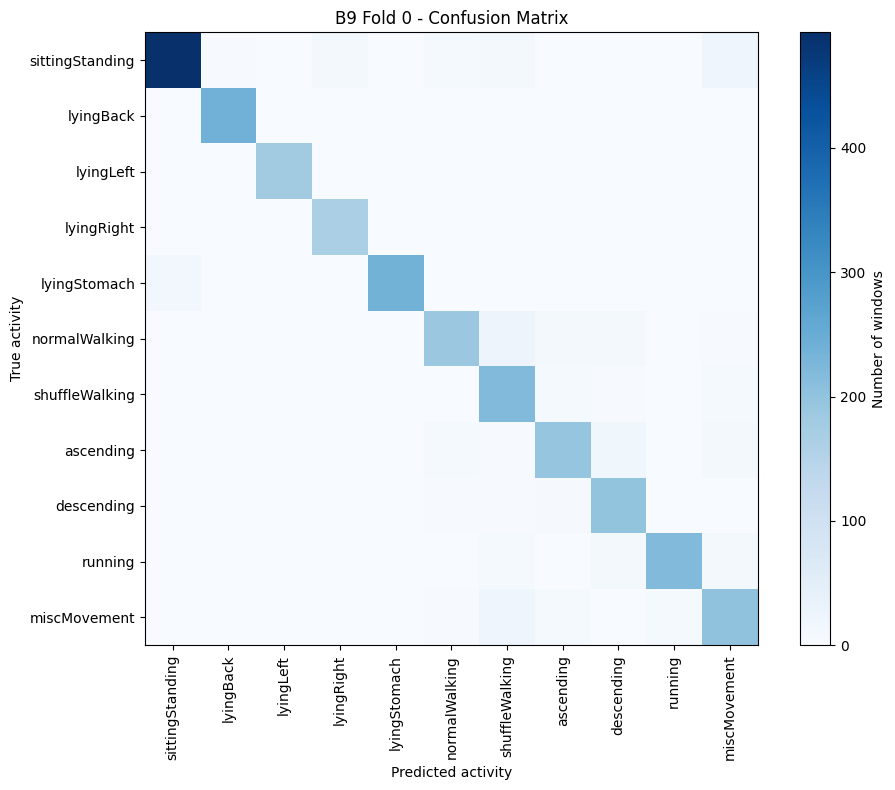

In [ ]:
# B9: Evaluate Fold 0 on held-out subjects

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Predict activity classes
y_prob_fold0 = cnn_fold0.predict(X_test_fold, verbose=0)
y_pred_fold0 = np.argmax(y_prob_fold0, axis=1)

# Compute evaluation metrics
fold0_accuracy = accuracy_score(y_test_fold, y_pred_fold0)
fold0_macro_f1 = f1_score(
    y_test_fold, y_pred_fold0,
    labels=np.arange(len(CLASSES)),
    average="macro",
    zero_division=0
)

fold0_cm = confusion_matrix(
    y_test_fold,
    y_pred_fold0,
    labels=np.arange(len(CLASSES))
)

print("=== Fold 0 Test Results ===")
print(f"Test Accuracy: {fold0_accuracy:.4f} ({fold0_accuracy*100:.2f}%)")
print(f"Macro F1: {fold0_macro_f1:.4f}")
print("Test windows:", len(y_test_fold))
print("Confusion matrix shape:", fold0_cm.shape)

# Visualise the confusion matrix
plt.figure(figsize=(10, 8))
plt.imshow(fold0_cm, cmap="Blues")
plt.colorbar(label="Number of windows")

plt.xticks(range(len(CLASSES)), CLASSES, rotation=90)
plt.yticks(range(len(CLASSES)), CLASSES)

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("B9 Fold 0 - Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
# B9: Save Fold 0 evaluation results

b9_fold_results = [{
    "fold": 0,
    "accuracy": fold0_accuracy,
    "macro_f1": fold0_macro_f1,
    "training_time": training_time,
    "n_test_windows": len(y_test_fold)
}]

b9_confusion_matrices = [fold0_cm.copy()]

print("=== Saved Fold 0 Results ===")

display(pd.DataFrame(b9_fold_results))

print("Confusion matrices saved:", len(b9_confusion_matrices))
print("Matrix shape:", b9_confusion_matrices[0].shape)

=== Saved Fold 0 Results ===


,fold,accuracy,macro_f1,training_time,n_test_windows
0,0,0.914017,0.914294,65.111114,2768


Confusion matrices saved: 1
Matrix shape: (11, 11)


In [ ]:
# B9: Train and evaluate Fold 1

k = 1

# Split recordings for this fold
train_recs_k = recordings[recordings["fold"] != k]
test_recs_k = recordings[recordings["fold"] == k]

# Check that subject groups do not overlap
train_groups_k = set(zip(train_recs_k["label"], train_recs_k["subject"]))
test_groups_k = set(zip(test_recs_k["label"], test_recs_k["subject"]))

assert not (train_groups_k & test_groups_k)

# Create training and test windows separately
X_train_k, y_train_k, _ = windows_from_recordings(train_recs_k)
X_test_k, y_test_k, _ = windows_from_recordings(test_recs_k)

print("Fold:", k)
print("Training windows:", X_train_k.shape)
print("Test windows:", X_test_k.shape)

# Build a fresh CNN with training-only normalization
keras.utils.set_random_seed(SEED + k)

cnn_k = build_cnn_fold(X_train_k)

cnn_k.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train for a fixed number of epochs
t0 = time.time()

history_k = cnn_k.fit(
    X_train_k,
    y_train_k,
    epochs=B9_EPOCHS,
    batch_size=B9_BATCH_SIZE,
    shuffle=True,
    verbose=0
)

elapsed_k = time.time() - t0

# Evaluate on the held-out fold
y_prob_k = cnn_k.predict(X_test_k, verbose=0)
y_pred_k = np.argmax(y_prob_k, axis=1)

acc_k = accuracy_score(y_test_k, y_pred_k)

f1_k = f1_score(
    y_test_k,
    y_pred_k,
    labels=np.arange(len(CLASSES)),
    average="macro",
    zero_division=0
)

cm_k = confusion_matrix(
    y_test_k,
    y_pred_k,
    labels=np.arange(len(CLASSES))
)

# Save the result
b9_fold_results.append({
    "fold": k,
    "accuracy": acc_k,
    "macro_f1": f1_k,
    "training_time": elapsed_k,
    "n_test_windows": len(y_test_k)
})

b9_confusion_matrices.append(cm_k.copy())

print("\n=== Fold 1 Results ===")
print(f"Test Accuracy: {acc_k:.4f} ({acc_k*100:.2f}%)")
print(f"Macro F1: {f1_k:.4f}")
print(f"Training time: {elapsed_k:.1f} seconds")
print(f"Final training accuracy: {history_k.history['accuracy'][-1]:.4f}")

print("\n=== Completed Folds ===")
display(pd.DataFrame(b9_fold_results))

Fold: 1
Training windows: (24053, 50, 3)
Test windows: (2707, 50, 3)

=== Fold 1 Results ===
Test Accuracy: 0.8892 (88.92%)
Macro F1: 0.8822
Training time: 63.6 seconds
Final training accuracy: 0.9414

=== Completed Folds ===


,fold,accuracy,macro_f1,training_time,n_test_windows
0,0,0.914017,0.914294,65.111114,2768
1,1,0.889176,0.882185,63.607512,2707


In [97]:
# B9: Run the remaining folds (2-9)

for k in range(2, N_FOLDS):

    # Skip already completed folds
    completed = [r["fold"] for r in b9_fold_results]

    if k in completed:
        print(f"Fold {k} already completed. Skipping.")
        continue

    print(f"\n========== Fold {k}/{N_FOLDS - 1} ==========")

    # Split recordings
    train_recs_k = recordings[recordings["fold"] != k]
    test_recs_k = recordings[recordings["fold"] == k]

    # Check subject separation
    train_groups_k = set(zip(train_recs_k["label"], train_recs_k["subject"]))
    test_groups_k = set(zip(test_recs_k["label"], test_recs_k["subject"]))

    assert not (train_groups_k & test_groups_k), "Subject leakage detected"

    # Create windows separately
    X_train_k, y_train_k, _ = windows_from_recordings(train_recs_k)
    X_test_k, y_test_k, _ = windows_from_recordings(test_recs_k)

    print("Training windows:", X_train_k.shape)
    print("Test windows:", X_test_k.shape)

    # Initialise a new CNN
    keras.utils.set_random_seed(SEED + k)

    cnn_k = build_cnn_fold(X_train_k)

    cnn_k.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train with fixed epochs
    t0 = time.time()

    history_k = cnn_k.fit(
        X_train_k,
        y_train_k,
        epochs=B9_EPOCHS,
        batch_size=B9_BATCH_SIZE,
        shuffle=True,
        verbose=0
    )

    elapsed_k = time.time() - t0

    # Evaluate on held-out subjects
    y_prob_k = cnn_k.predict(X_test_k, verbose=0)
    y_pred_k = np.argmax(y_prob_k, axis=1)

    acc_k = accuracy_score(y_test_k, y_pred_k)

    f1_k = f1_score(
        y_test_k,
        y_pred_k,
        labels=np.arange(len(CLASSES)),
        average="macro",
        zero_division=0
    )

    cm_k = confusion_matrix(
        y_test_k,
        y_pred_k,
        labels=np.arange(len(CLASSES))
    )

    # Store results
    b9_fold_results.append({
        "fold": k,
        "accuracy": acc_k,
        "macro_f1": f1_k,
        "training_time": elapsed_k,
        "n_test_windows": len(y_test_k)
    })

    b9_confusion_matrices.append(cm_k.copy())

    # Print this fold's results
    print(f"Test Accuracy: {acc_k*100:.2f}%")
    print(f"Macro F1: {f1_k:.4f}")
    print(f"Training time: {elapsed_k:.1f} seconds")

# Display all completed folds
print("\n=== B9 Completed Fold Results ===")

b9_results_df = pd.DataFrame(b9_fold_results).sort_values("fold")
display(b9_results_df)

print("Completed folds:", len(b9_results_df))
print("Saved confusion matrices:", len(b9_confusion_matrices))

Fold 2 already completed. Skipping.

========== Fold 3/9 ==========
Training windows: (24065, 50, 3)
Test windows: (2695, 50, 3)
Test Accuracy: 90.46%
Macro F1: 0.9018
Training time: 85.6 seconds

========== Fold 4/9 ==========
Training windows: (24114, 50, 3)
Test windows: (2646, 50, 3)
Test Accuracy: 91.08%
Macro F1: 0.9057
Training time: 61.9 seconds

========== Fold 5/9 ==========
Training windows: (24120, 50, 3)
Test windows: (2640, 50, 3)
Test Accuracy: 92.20%
Macro F1: 0.9236
Training time: 62.7 seconds

========== Fold 6/9 ==========
Training windows: (24123, 50, 3)
Test windows: (2637, 50, 3)
Test Accuracy: 92.53%
Macro F1: 0.9230
Training time: 62.5 seconds

========== Fold 7/9 ==========
Training windows: (24121, 50, 3)
Test windows: (2639, 50, 3)
Test Accuracy: 93.63%
Macro F1: 0.9333
Training time: 64.9 seconds

========== Fold 8/9 ==========
Training windows: (24110, 50, 3)
Test windows: (2650, 50, 3)
Test Accuracy: 89.74%
Macro F1: 0.8943
Training time: 62.6 seconds

===

,fold,accuracy,macro_f1,training_time,n_test_windows
0,0,0.914017,0.914294,65.111114,2768
1,1,0.889176,0.882185,63.607512,2707
2,2,0.922299,0.925994,63.552523,2767
3,3,0.904638,0.901778,85.622802,2695
4,4,0.910809,0.905688,61.858217,2646
5,5,0.921970,0.923599,62.741684,2640
6,6,0.925294,0.922998,62.496432,2637
7,7,0.936340,0.933251,64.891942,2639
8,8,0.897358,0.894325,62.611921,2650
9,9,0.921103,0.917524,64.187463,2611


Completed folds: 10
Saved confusion matrices: 10


In [ ]:
# B9: Summarise 10-fold cross-validation results

b9_results_df = pd.DataFrame(b9_fold_results).sort_values("fold")

# Verify that all ten folds are present exactly once
assert b9_results_df["fold"].tolist() == list(range(N_FOLDS))

# Extract the accuracy and Macro F1 scores
accuracies = b9_results_df["accuracy"].to_numpy()
macro_f1_scores = b9_results_df["macro_f1"].to_numpy()

# Calculate mean and sample standard deviation
mean_accuracy = np.mean(accuracies)
std_accuracy = np.std(accuracies, ddof=1)

mean_macro_f1 = np.mean(macro_f1_scores)
std_macro_f1 = np.std(macro_f1_scores, ddof=1)

print("=== B9 10-Fold Cross-validation Summary ===")
print(f"Mean Accuracy: {mean_accuracy*100:.2f}%")
print(f"Accuracy Std: {std_accuracy*100:.2f} pp")
print(f"Accuracy: {mean_accuracy*100:.2f} ± {std_accuracy*100:.2f}%")

print(f"\nMean Macro F1: {mean_macro_f1:.4f}")
print(f"Macro F1 Std: {std_macro_f1:.4f}")

print(f"\nMinimum Accuracy: {np.min(accuracies)*100:.2f}%")
print(f"Maximum Accuracy: {np.max(accuracies)*100:.2f}%")

print("\nTotal test windows:", b9_results_df["n_test_windows"].sum())
print("Total training time (seconds):",
      round(b9_results_df["training_time"].sum(), 1))

In [ ]:
# B9: Sum confusion matrices across all ten folds

# Check that all ten matrices are available
assert len(b9_confusion_matrices) == N_FOLDS

# Sum confusion matrices element by element
b9_summed_cm = np.sum(
    np.stack(b9_confusion_matrices),
    axis=0
)

print("=== Summed Confusion Matrix ===")
print("Shape:", b9_summed_cm.shape)
print("Total windows:", b9_summed_cm.sum())
print("Correct predictions:", np.trace(b9_summed_cm))

# Plot the summed confusion matrix
plt.figure(figsize=(11, 9))

plt.imshow(b9_summed_cm, cmap="Blues")
plt.colorbar(label="Number of windows")

plt.xticks(
    range(len(CLASSES)),
    CLASSES,
    rotation=90
)

plt.yticks(
    range(len(CLASSES)),
    CLASSES
)

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("B9 - Summed Confusion Matrix (10 Folds)")

plt.tight_layout()
plt.show()

In [ ]:
# B9: Calculate per-class recall from the summed confusion matrix

# Count true windows and correct predictions for each class
class_totals = b9_summed_cm.sum(axis=1)
class_correct = np.diag(b9_summed_cm)

# Calculate recall for each activity
class_recall = np.divide(
    class_correct,
    class_totals,
    out=np.zeros(len(CLASSES), dtype=float),
    where=class_totals != 0
)

# Create a summary table
b9_class_results = pd.DataFrame({
    "Activity": CLASSES,
    "Test Windows": class_totals,
    "Correct": class_correct,
    "Incorrect": class_totals - class_correct,
    "Recall (%)": class_recall * 100
})

# Show classes from lowest to highest recall
display(
    b9_class_results.sort_values("Recall (%)").round(2)
)

# Plot per-class recall
plt.figure(figsize=(10, 5))
plt.bar(CLASSES, class_recall * 100)

plt.xticks(rotation=60, ha="right")
plt.ylabel("Recall (%)")
plt.xlabel("Activity")
plt.title("B9 - Per-class Recall Across 10 Folds")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [ ]:
# B9: Identify the most frequent classification errors

# Copy the confusion matrix
error_cm = b9_summed_cm.copy()

# Remove correct predictions from the diagonal
np.fill_diagonal(error_cm, 0)

# Find all non-zero classification errors
true_idx, pred_idx = np.where(error_cm > 0)

errors = pd.DataFrame({
    "True Activity": [CLASSES[i] for i in true_idx],
    "Predicted Activity": [CLASSES[j] for j in pred_idx],
    "Error Windows": error_cm[true_idx, pred_idx]
})

# Calculate the proportion within each true class
errors["Error Rate (%)"] = (
    errors["Error Windows"].to_numpy()
    / class_totals[true_idx] * 100
)

# Display the ten most frequent errors
top_errors = errors.sort_values(
    "Error Windows", ascending=False
).head(10)

print("=== Top 10 Classification Errors ===")
display(top_errors.round(2))

print("\nTotal incorrect predictions:", error_cm.sum())

In [ ]:
# Compress the lab3_models folder into a ZIP file

!zip -r lab3_models.zip lab3_models

# End of Lab 3

You now have a working pipeline from CSV files to a verified `.tflite` model.

In [99]:
name = "har_mlp" # <-- your model's name
d = OUT_DIR # the lab3_models folder
meta = json.loads((d / f"{name}_meta.json").read_text())
example = json.loads((d / f"{name}_example.json").read_text())
classes = meta["output"]["classes"]
W = meta["window_samples"]
interp = tf.lite.Interpreter(model_path=str(d / f"{name}.tflite"))
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
print("model input :", inp["shape_signature"], inp["dtype"].__name__)
print("model output:", out["shape_signature"], out["dtype"].__name__)
print(f"metadata : window {W}, step {meta['step_samples']}, {len(classes)} classes")
print(f"template : passes [1, {W}, 3] float32, reads [1, {len(classes)}] float32")
# Feed the example window the way the app does
interp.resize_tensor_input(inp["index"], [1, W, 3])
interp.allocate_tensors()
interp.set_tensor(inp["index"], np.array([example["input_window"]], np.float32))
interp.invoke()
p = interp.get_tensor(out["index"])[0]
print(f"example : {classes[p.argmax()]} ({p.max():.0%}), outputs sum to {p.sum():.3f};",
f"Lab 3 expected {example['expected_class']}")

model input : [-1 50  3] float32
model output: [-1 11] float32
metadata : window 50, step 25, 11 classes
template : passes [1, 50, 3] float32, reads [1, 11] float32
example : lyingLeft (99%), outputs sum to 1.000; Lab 3 expected lyingLeft
